# Group 10 - Exploratory Data Analysis
## Amazing Creative Desk Coworking - customer segmentation

**Course**: Data Mining, NOVA IMS, Fall 2026-2027  
**Group**: 10

**Members**
- Gustavo Carvalho
- Diogo Gaspar
- Mohamed Triki

### Purpose
ACDC wants to understand member value, behaviour and lifecycle before designing targeted offers. This notebook
explores the 31 variables in `acdc_dataset.csv`, assesses and documents data quality, describes the patterns in
usage and revenue, builds features that a later segmentation could use, and states customer-group hypotheses.
No clustering model is trained here: Deliverable 1 is exploratory.

### AI usage statement
AI usage statement: AI tools (ChatGPT and Claude) were used for Python coding syntax assistance (pandas operations and matplotlib formatting), exploratory brainstorming of customer hypotheses, and grammar proofreading of text descriptions. All data cleaning rules, threshold choices, feature definitions, analytical insights, and business interpretations represent original group work. The group executed and verified every code cell in this notebook and takes full responsibility for the submission.

The group is responsible for checking and explaining every submitted result.

---

### Contents
- [Data Mining objective](#Data-Mining-objective) - what ACDC asks of us and what Deliverable 2 will take from here
1. [Setup](#1.-Setup) - environment, versions, palette and the documented variable list
2. [Data understanding](#2.-Data-understanding) - shape, types, first descriptive statistics
3. [Data-quality assessment](#3.-Data-quality-assessment) - duplicates, missing values, types, contradictions, implausible values
4. [Data-quality handling](#4.-Data-quality-handling) - documented decisions, flags and the quality log
5. [Univariate analysis](#5.-Univariate-analysis) - distributions, spread and category frequencies
6. [Relationships](#6.-Relationships) - value against usage, plan against status, correlation inside groups
7. [Time trends and add-on usage](#7.-Time-trends-and-add-on-usage) - lifecycle over time, add-on behaviour, missingness pattern
8. [Feature engineering](#8.-Feature-engineering) - base derivations and the engineered feature set
9. [Engineered feature patterns](#9.-Engineered-feature-patterns) - distributions, overlap and redundancy
10. [Anomaly screening](#10.-Anomaly-screening) - one labelled diagnostic, flagged not removed
11. [Clustering-reliability risks](#11.-Clustering-reliability-risks) - what could distort a later grouping
12. [Behavioural signals and group hypotheses](#12.-Behavioural-signals-and-group-hypotheses) - candidate groups and the expected cluster count
13. [Conclusion](#13.-Conclusion) - the four questions answered and the hand-over to Deliverable 2

---

## Data Mining objective

**The problem ACDC has.** Amazing Creative Desk Coworking sells desk space and add-on services to individual
members and to teams. It does not know which of its members are similar to one another, so it cannot aim a price,
a re-engagement offer or a service upgrade at the right people. Offers go out broadly, which costs money and trains
members to ignore them.

**What customer segmentation is meant to achieve.** Split the member base into a small number of groups that are
internally alike and externally different on things a manager can act on: what a member pays, how often the member
comes, how recently the member came, how long the relationship has run. Each group then gets its own commercial
response.

**Why an unsupervised grouping fits, and why we do not train one here.** There is no group label in the data to
predict from, so a supervised model has nothing to learn from. Unsupervised grouping discovers the structure from the
features alone. Deliverable 1 is the exploratory half of that work: it prepares the data, describes what is in it and
states which features are worth grouping on. No grouping model is trained in this notebook.

**What Deliverable 2 is expected to produce.** A chosen feature set, a documented preprocessing decision, a fitted
grouping with a justified number of groups, and named segments that match or reject the six hypotheses written in
section 12. Section 13 states what this notebook hands over to that work.

So what: this notebook is the evidence base for a segmentation, not the segmentation itself.

# 1. Setup
One cell finds the dataset, one checks the installed library versions, and the rest fixes the labels, colours and
small helpers that every later section reuses. The notebook uses pandas, NumPy, Matplotlib and Seaborn only.

In [1]:
# Imports kept together here: pandas and numpy for the tables, matplotlib and seaborn for the charts,
# pathlib to locate the file, ceil from the math module to size the figure grids, sys to report the Python version.
from pathlib import Path
from math import ceil
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
print("libraries imported: pandas, numpy, matplotlib, seaborn, plus pathlib, math and sys from the standard library")

libraries imported: pandas, numpy, matplotlib, seaborn, plus pathlib, math and sys from the standard library


In [2]:
# Versions tested for this notebook. Nothing is installed here: the cell reads the versions already
# present and reports whether each one falls inside the supported range.
REQUIRED = {
    "pandas": ((2, 3), (3, 0)),
    "numpy": ((2, 3), (3, 0)),
    "matplotlib": ((3, 10), (4, 0)),
    "seaborn": ((0, 13), (1, 0)),
}
version_rows = []
for package, (lower, upper) in REQUIRED.items():
    installed = __import__(package).__version__
    parts = tuple(int(x) for x in installed.split("+")[0].split(".")[:2])
    required = f">={lower[0]}.{lower[1]},<{upper[0]}.{upper[1]}"
    version_rows.append({"package": package, "installed": installed, "required": required,
                         "compatible": lower <= parts < upper})
versions = pd.DataFrame(version_rows)
print(versions.to_string(index=False))
print("\nall installed versions fall inside the tested range:", bool(versions["compatible"].all()))
print("python:", sys.version.split()[0])

   package installed    required  compatible
    pandas     2.3.3  >=2.3,<3.0        True
     numpy     2.3.5  >=2.3,<3.0        True
matplotlib    3.10.0 >=3.10,<4.0        True
   seaborn    0.13.2 >=0.13,<1.0        True

all installed versions fall inside the tested range: True
python: 3.11.0


In [3]:
# Locate the dataset. The file is looked for next to the notebook first, then in the repository layout, so the
# notebook runs from its own folder, from the project root or from a copied folder with the CSV beside it.
candidate_paths = [Path("acdc_dataset.csv"), Path("data") / "raw" / "acdc_dataset.csv",
                   Path("..") / "data" / "raw" / "acdc_dataset.csv"]
DATA_PATH = next((p for p in candidate_paths if p.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError("acdc_dataset.csv was not found in " + ", ".join(str(p) for p in candidate_paths))

print("dataset:", DATA_PATH)          # the path as it was found, always relative to where the notebook runs
print("separator ';' | the shape is verified in section 2, not assumed here")

dataset: ..\data\raw\acdc_dataset.csv
separator ';' | the shape is verified in section 2, not assumed here


In [4]:
# The shared style: one palette and one order for the plan tiers, defined once so every section shows them alike.
BLUE, GRAY, LIGHT_BLUE = "#1F4E9C", "#8A8F98", "#9DB7E0"   # project palette: blue / gray / white
ACCENT = "#C55A11"                                          # burnt orange, reserved for highlights only
CORR_CMAP = "RdBu_r"

# plan_tier is ordinal, not nominal: the course dataset annex documents the order below. Section 12 tests whether
# that documented order also holds for realised revenue.
tier_order = ["hot_desk", "flex", "dedicated_desk", "full_time", "private_office"]
TIER_COLORS = dict(zip(tier_order, sns.color_palette("Blues", 7)[2:]))
print("plan tiers in the documented order:", " < ".join(tier_order))

plan tiers in the documented order: hot_desk < flex < dedicated_desk < full_time < private_office


In [5]:
# A readable name for every variable, used as the label on tables and charts so the same wording appears twice.
FEATURE_LABELS = {
    "age": "Age (years)", "n_colleagues_on_account": "Colleagues on account",
    "plan_days_per_week": "Plan days per week", "days_since_last_visit": "Days since last visit",
    "total_visits": "Total visits", "avg_weekly_visits": "Average weekly visits",
    "entitled_visits_last_period": "Entitled visits last period", "actual_visits_last_period": "Actual visits last period",
    "meeting_room_hours": "Meeting room hours", "event_space_hours": "Event space hours",
    "guest_passes_issued": "Guest passes issued", "n_renewals": "Renewals", "lifetime_value": "Lifetime value (EUR)",
    "tenure_months": "Tenure (months)", "monthly_revenue": "Monthly revenue (EUR)", "utilization_rate": "Allowance used",
    "plan_tier_ordinal": "Plan tier (ordinal)", "n_addons_used": "Add-ons used", "visit_rate": "Visits per month",
    "value_per_visit": "Revenue per visit (EUR)", "renewal_rate": "Renewals per year",
    "premium_hours_total": "Premium facility hours", "team_size": "Team size", "recency_days": "Days since last visit",
    "visit_intensity_vs_plan": "Weekly visits vs plan days", "guest_pass_rate": "Guest passes per month",
    "addon_mix": "Add-on mix", "start_year_cohort": "Start-year cohort",
    "gender": "Gender", "industry": "Industry", "country": "Country", "plan_tier": "Plan tier",
    "is_team_account": "Team account", "status": "Membership status",
}
print("readable labels defined for", len(FEATURE_LABELS), "variables")


def chart_label(column):
    """Return the chart label of a column, falling back to the column name with spaces."""
    return FEATURE_LABELS.get(column, column.replace("_", " "))

readable labels defined for 34 variables


In [6]:
# Two small helpers used by most sections. They are written once here because the same two lines recur constantly.
def label_missing(series, label="(missing)"):
    """Show missing values as their own category in tables and charts, so nothing disappears silently.

    Args:
        series: a pandas column, most often a text one.
        label: the text used in place of a missing value.

    Returns:
        A copy of the column with every missing value replaced by that text.
    """
    labelled = series.astype(object).copy()
    labelled[labelled.isna()] = label
    return labelled


def check(condition, message):
    """Print a warning instead of stopping the notebook.

    Args:
        condition: the expectation being tested, as a True/False value.
        message: what to print when the expectation does not hold.

    Returns:
        True when the expectation held, False otherwise.
    """
    if not condition:
        print("WARNING:", message)
    return bool(condition)


print("helpers defined: label_missing (missing values as their own level) and check (report, do not stop)")

helpers defined: label_missing (missing values as their own level) and check (report, do not stop)


So what: the notebook runs on four everyday libraries, reads one file by a relative path, and fixes its labels,
colours and two small helpers once so no later section has to reinvent them.

# 2. Data understanding
We inspect the structure, the types and the first descriptive statistics before analysing member behaviour.
Nothing in this section changes the data.

### Words used throughout the notebook
The **median** is the middle value when a column is sorted: half the members sit below it and half above. The
**interquartile range**, written **IQR**, is the width of that middle half: the 75th percentile minus the 25th.
A median and an IQR describe a column without being dragged around by a few huge values, which is why they are used
more often here than the mean.

In [7]:
# Read the raw extract (';' separated) and confirm it is the file the brief describes.
raw = pd.read_csv(DATA_PATH, sep=";")
print(f"rows = {raw.shape[0]:,} | columns = {raw.shape[1]}")
check(raw.shape[1] == 31, f"expected 31 columns, found {raw.shape[1]} - the variable list below will not cover the extras")
check(raw.shape[0] == 15465, f"expected 15,465 rows, found {raw.shape[0]:,} - shares quoted later will differ from the extract description")
raw.head()

rows = 15,465 | columns = 31


,member_id,age,gender,industry,country,is_team_account,n_colleagues_on_account,plan_tier,plan_days_per_week,membership_start,...,uses_event_space,uses_guest_passes,uses_print,uses_mail_handling,uses_phone_booths,uses_day_passes,uses_storage,uses_bike_locker,n_renewals,lifetime_value
0,CW000001,38.0,Female,Information Technology,Portugal,False,0,flex,3,2021-08-01,...,False,True,0,False,True,True,False,False,2,4477.97
1,CW000002,38.0,Male,Information Technology,Portugal,True,2,HOT_DESK,2,2023-11-24,...,False,False,0,True,False,False,False,False,0,165.86
2,CW000003,43.0,Male,Education,DE,True,1,flex,3,2021-12-03,...,False,False,0,False,False,False,False,False,1,4486.17
3,CW000004,38.0,F,Legal,portugal,False,0,flex,3,2022-01-02,...,False,False,0,False,False,False,False,False,0,258.63
4,CW000005,45.0,Female,Information Technology,United Kingdom,False,0,hot_desk,2,2023-10-24,...,False,False,0,False,False,True,False,False,0,335.74


In [8]:
# Column names, non-null counts and dtypes in one view: this is where a numeric column that arrived as text,
# or a text column that arrived as numeric, is spotted.
raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15465 entries, 0 to 15464
Data columns (total 31 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   member_id                    15465 non-null  object 
 1   age                          14907 non-null  float64
 2   gender                       14935 non-null  object 
 3   industry                     15465 non-null  object 
 4   country                      15035 non-null  object 
 5   is_team_account              15465 non-null  bool   
 6   n_colleagues_on_account      15465 non-null  int64  
 7   plan_tier                    15360 non-null  object 
 8   plan_days_per_week           15465 non-null  int64  
 9   membership_start             15465 non-null  object 
 10  membership_end               15465 non-null  object 
 11  last_badge_swipe             15465 non-null  object 
 12  days_since_last_visit        15465 non-null  int64  
 13  total_visits    

In [9]:
# The last rows are shown as well: corruption introduced at the end of an export is invisible in head().
print("--- last rows ---")
print(raw.tail().to_string())
print("\n--- dtypes ---")
raw.dtypes.to_frame("dtype")

--- last rows ---
      member_id   age  gender                industry   country  is_team_account  n_colleagues_on_account       plan_tier  plan_days_per_week membership_start membership_end last_badge_swipe  days_since_last_visit  total_visits  avg_weekly_visits  entitled_visits_last_period  actual_visits_last_period  meeting_room_hours  event_space_hours  guest_passes_issued  uses_meeting_rooms  uses_event_space  uses_guest_passes  uses_print  uses_mail_handling  uses_phone_booths  uses_day_passes  uses_storage  uses_bike_locker  n_renewals lifetime_value
15460  CW009828  29.0  Female                 Unknown     Spain            False                        0            flex                   3       2022-12-09     2023-07-01       2023-06-28                      3            74               2.55                        26.09                         21                 0.0                0.0                  0.0               False             False              False           1    

,dtype
member_id,object
age,float64
gender,object
industry,object
country,object
is_team_account,bool
n_colleagues_on_account,int64
plan_tier,object
plan_days_per_week,int64
membership_start,object


In [10]:
# Group the columns by pandas dtype, so we know what describe() will and will not cover.
numeric_columns = raw.select_dtypes(include="number").columns.tolist()
text_columns = raw.select_dtypes(include="object").columns.tolist()
bool_columns = raw.select_dtypes(include="bool").columns.tolist()
ungrouped = [c for c in raw.columns if c not in numeric_columns + text_columns + bool_columns]
for group, columns in [("numeric", numeric_columns), ("object (text)", text_columns), ("bool", bool_columns)]:
    print(f"{group} ({len(columns)}): {', '.join(columns)}\n")
print(f"covered: {len(numeric_columns) + len(text_columns) + len(bool_columns)} of {raw.shape[1]} columns")
check(not ungrouped, f"columns outside numeric/object/bool: {ungrouped}")

numeric (13): age, n_colleagues_on_account, plan_days_per_week, days_since_last_visit, total_visits, avg_weekly_visits, entitled_visits_last_period, actual_visits_last_period, meeting_room_hours, event_space_hours, guest_passes_issued, uses_print, n_renewals

object (text) (9): member_id, gender, industry, country, plan_tier, membership_start, membership_end, last_badge_swipe, lifetime_value

bool (9): is_team_account, uses_meeting_rooms, uses_event_space, uses_guest_passes, uses_mail_handling, uses_phone_booths, uses_day_passes, uses_storage, uses_bike_locker

covered: 31 of 31 columns


True

In [11]:
# Descriptive statistics of the columns that arrived numeric.
raw.describe().round(2).T

,count,mean,std,min,25%,50%,75%,max
age,14907.0,34.86,10.39,1.0,29.00,34.00,40.00,149.00
n_colleagues_on_account,15465.0,0.54,1.18,-1.0,0.00,0.00,1.00,9.00
plan_days_per_week,15465.0,3.39,1.46,0.0,2.00,3.00,5.00,9.00
days_since_last_visit,15465.0,117.11,275.53,-956.0,4.00,13.00,55.00,1212.00
total_visits,15465.0,110.41,182.94,-112.0,8.00,34.00,132.00,6530.00
avg_weekly_visits,15465.0,1.78,1.94,0.0,0.71,1.42,2.41,47.40
entitled_visits_last_period,15465.0,27.52,13.48,0.0,17.39,26.09,43.48,78.27
actual_visits_last_period,15465.0,13.80,11.39,0.0,5.00,10.00,20.00,60.00
meeting_room_hours,14167.0,33.08,428.17,-56.6,0.00,0.00,7.20,41220.00
event_space_hours,15465.0,5.12,26.01,-13.5,0.00,0.00,0.00,602.80


In [12]:
# Descriptive statistics of the text columns: count, uniqueness and the most frequent value.
# lifetime_value is text here, which is the first signal that it needs parsing (section 3.3).
raw.describe(include=["O"]).T

,count,unique,top,freq
member_id,15465,15450,CW005845,2
gender,14935,12,Female,7414
industry,15465,43,Information Technology,3322
country,15035,33,Portugal,9959
plan_tier,15360,19,flex,5182
membership_start,15465,1539,2021-01-01,560
membership_end,15465,1423,1970-01-01,3956
last_badge_swipe,15465,1543,2023-12-30,279
lifetime_value,14425,11860,0,1725


In [13]:
# The boolean columns: mean() on a boolean column is the share of True, so this doubles as the add-on take-up table.
raw.describe(include=["bool"]).T

,count,unique,top,freq
is_team_account,15465,2,False,11112
uses_meeting_rooms,15465,2,False,10202
uses_event_space,15465,2,False,13624
uses_guest_passes,15465,2,False,12651
uses_mail_handling,15465,2,False,11901
uses_phone_booths,15465,2,False,11469
uses_day_passes,15465,2,False,12069
uses_storage,15465,2,False,13169
uses_bike_locker,15465,2,False,15439


### Variable descriptions
The descriptions below come from the course dataset annex.

| Theme | Variable | Description |
|---|---|---|
| Identity and profile | `member_id` | Unique identifier of each member |
| Identity and profile | `age` | Age of the member at the extraction date |
| Identity and profile | `gender` | Gender of the member |
| Identity and profile | `country` | Country where the member (or their company) is based |
| Identity and profile | `industry` | Industry sector the member works in |
| Account and plan | `is_team_account` | Whether the membership is held by a team/company account |
| Account and plan | `n_colleagues_on_account` | Number of colleagues sharing the account |
| Account and plan | `plan_tier` | Current tier: hot_desk < flex < dedicated_desk < full_time < private_office |
| Account and plan | `plan_days_per_week` | Days per week the plan entitles the member to use the space |
| Lifecycle and dates | `membership_start` | Date the membership first began |
| Lifecycle and dates | `membership_end` | Date the membership first ended |
| Lifecycle and dates | `last_badge_swipe` | Date of the most recent physical entry to the space |
| Lifecycle and dates | `days_since_last_visit` | Days since the member's last recorded visit |
| Visit activity | `total_visits` | Total visits over the whole membership |
| Visit activity | `avg_weekly_visits` | Average visits per week over the membership |
| Visit activity | `entitled_visits_last_period` | Visits the plan entitled the member to in the last period |
| Visit activity | `actual_visits_last_period` | Visits actually made in the last period |
| Premium and add-on usage | `meeting_room_hours` | Hours of meeting-room usage |
| Premium and add-on usage | `event_space_hours` | Hours of event-space usage |
| Premium and add-on usage | `guest_passes_issued` | Number of guest passes issued |
| Premium and add-on usage | `uses_meeting_rooms` | Ever used the meeting-room add-on |
| Premium and add-on usage | `uses_event_space` | Ever used the event-space add-on |
| Premium and add-on usage | `uses_guest_passes` | Ever used the guest-pass add-on |
| Premium and add-on usage | `uses_print` | Used the print add-on |
| Premium and add-on usage | `uses_mail_handling` | Used the mail-handling add-on |
| Premium and add-on usage | `uses_phone_booths` | Used the phone-booth add-on |
| Premium and add-on usage | `uses_day_passes` | Used the day-pass add-on |
| Premium and add-on usage | `uses_storage` | Used the storage add-on |
| Premium and add-on usage | `uses_bike_locker` | Used the bike-locker add-on |
| Loyalty and value | `n_renewals` | Number of times the membership was renewed |
| Loyalty and value | `lifetime_value` | Total revenue attributed to the member over the whole membership |

### Variable types
We separate the metric variables from the non-metric ones before analysing them. `lifetime_value` is text in the raw
file and becomes metric after parsing. `gender`, `industry` and `country` are nominal, while `plan_tier` is ordinal
and follows the documented order `hot_desk < flex < dedicated_desk < full_time < private_office`.

In [14]:
# Assign each of the 31 columns to one typology group. The lists are written out so every group can be checked
# against the file in the cell that follows.
metric_features = ["age", "n_colleagues_on_account", "plan_days_per_week", "days_since_last_visit", "total_visits",
                   "avg_weekly_visits", "entitled_visits_last_period", "actual_visits_last_period",
                   "meeting_room_hours", "event_space_hours", "guest_passes_issued", "n_renewals", "lifetime_value"]
binary_features = ["is_team_account"] + [c for c in raw.columns if c.startswith("uses_")]
categorical_features = ["gender", "industry", "country", "plan_tier"]
date_features = ["membership_start", "membership_end", "last_badge_swipe"]
id_feature = ["member_id"]
typed_columns = metric_features + binary_features + categorical_features + date_features + id_feature
print("metric:", len(metric_features), "| binary:", len(binary_features), "| categorical:", len(categorical_features),
      "| dates:", len(date_features), "| id:", len(id_feature))
print("metric variables:", ", ".join(metric_features))

metric: 13 | binary: 10 | categorical: 4 | dates: 3 | id: 1
metric variables: age, n_colleagues_on_account, plan_days_per_week, days_since_last_visit, total_visits, avg_weekly_visits, entitled_visits_last_period, actual_visits_last_period, meeting_room_hours, event_space_hours, guest_passes_issued, n_renewals, lifetime_value


In [15]:
# Put the typology in a table and check that it covers the file exactly: no column left out, no column invented.
typology_rows = []
for group, columns in [("metric", metric_features), ("binary", binary_features), ("categorical", categorical_features),
                       ("date", date_features), ("identifier", id_feature)]:
    for column in columns:
        typology_rows.append({"variable": column, "group": group})
typology = pd.DataFrame(typology_rows).set_index("variable")
columns_left_out = [c for c in raw.columns if c not in typed_columns]
columns_not_in_file = [c for c in typed_columns if c not in raw.columns]
print(f"typology covers {len(typed_columns)} of {raw.shape[1]} columns")
check(not columns_left_out, f"columns left out of the typology: {columns_left_out}")
check(not columns_not_in_file, f"typology names columns that are not in the file: {columns_not_in_file}")
typology

typology covers 31 of 31 columns


,group
variable,
age,metric
n_colleagues_on_account,metric
plan_days_per_week,metric
days_since_last_visit,metric
total_visits,metric
avg_weekly_visits,metric
entitled_visits_last_period,metric
actual_visits_last_period,metric
meeting_room_hours,metric


So what: the file is one row per member with 31 documented columns, thirteen of them metric, and `lifetime_value`
arrives as text, so nothing can be summarised until it is parsed.

# 3. Data-quality assessment
We check duplicates, missing values, types, contradictions between fields and implausible values. This section
measures what is in the file; section 4 records what we decide to do about it.

## 3.1 Duplicates

In [16]:
# Count exact duplicate rows and repeated identifiers, and say what the duplicates mean for the unit of analysis.
n_duplicate_rows = int(raw.duplicated().sum())
n_duplicate_ids = int(raw["member_id"].duplicated().sum())
print(f"exact duplicate rows : {n_duplicate_rows} ({n_duplicate_rows / len(raw):.2%})")
print(f"repeated member_id   : {n_duplicate_ids}")
check(raw.drop_duplicates()["member_id"].is_unique,
      "member_id is still repeated after dropping exact duplicates - the rows are similar but not identical")
print("after dropping exact duplicates, member_id is unique:", bool(raw.drop_duplicates()["member_id"].is_unique))
print("unit of analysis: one row = one member, so duplicates are removed (section 4.1), not averaged")

exact duplicate rows : 15 (0.10%)
repeated member_id   : 15


after dropping exact duplicates, member_id is unique: True
unit of analysis: one row = one member, so duplicates are removed (section 4.1), not averaged


## 3.2 Missing values and empty strings

In [17]:
# Count NaN per column and look for empty strings, which are missing values that pandas cannot see.
missing_series = raw.isna().sum()
missing_summary = pd.DataFrame({"missing": missing_series, "pct": (missing_series / len(raw) * 100).round(2)})
print(missing_summary[missing_summary["missing"] > 0].sort_values("missing", ascending=False).to_string())
n_empty_strings = int((raw[text_columns] == "").sum().sum())
print(f"\nempty strings in text columns: {n_empty_strings}")
check(n_empty_strings == 0, f"{n_empty_strings} empty strings found: they are missing values written as text")
print(f"columns with at least one missing value: {int((missing_series > 0).sum())} of {raw.shape[1]}"
      f" | rows with at least one: {raw.isna().any(axis=1).mean():.1%}")

                     missing   pct
meeting_room_hours      1298  8.39
guest_passes_issued     1271  8.22
lifetime_value          1040  6.72
age                      558  3.61
gender                   530  3.43
country                  430  2.78
plan_tier                105  0.68



empty strings in text columns: 0
columns with at least one missing value: 7 of 31 | rows with at least one: 28.3%


In [18]:
# The two largest blocks of absence: are they the same members? Shared rows would mean one underlying cause;
# two independent blocks would mean two gaps to handle separately.
no_meeting_hours = raw["meeting_room_hours"].isna()
sentinel_999 = raw["days_since_last_visit"] == 999
overlap_rows = pd.DataFrame({
    "rows": [int(no_meeting_hours.sum()), int(sentinel_999.sum()), int((no_meeting_hours & sentinel_999).sum()),
             int((no_meeting_hours & ~sentinel_999).sum()), int((~no_meeting_hours & sentinel_999).sum())],
}, index=["no meeting_room_hours", "days_since_last_visit == 999", "both", "only missing hours", "only the 999 code"])
print(overlap_rows.to_string())
same_rows = int(overlap_rows.loc["both", "rows"]) == int(no_meeting_hours.sum()) == int(sentinel_999.sum())
print(f"\nare the two blocks the same rows? {same_rows}")
print("Reading: the blocks match in size but not in membership, so they are two separate gaps, one in the usage")
print("feed and one in the recency feed, and they are recorded as two issues rather than one.")

                              rows
no meeting_room_hours         1298
days_since_last_visit == 999  1298
both                           157
only missing hours            1141
only the 999 code             1141

are the two blocks the same rows? False
Reading: the blocks match in size but not in membership, so they are two separate gaps, one in the usage
feed and one in the recency feed, and they are recorded as two issues rather than one.


In [19]:
# How widespread the gaps are across the whole file.
missing_pct_raw = (raw.isna().mean() * 100).sort_values()
missing_pct_raw = missing_pct_raw[missing_pct_raw > 0]
print(f"columns with at least one missing value: {len(missing_pct_raw)} of {raw.shape[1]}")
print(f"the largest single gap covers {missing_pct_raw.max():.1f}% of rows")
print(f"rows with at least one missing value: {raw.isna().any(axis=1).mean():.1%}")

columns with at least one missing value: 7 of 31
the largest single gap covers 8.4% of rows
rows with at least one missing value: 28.3%


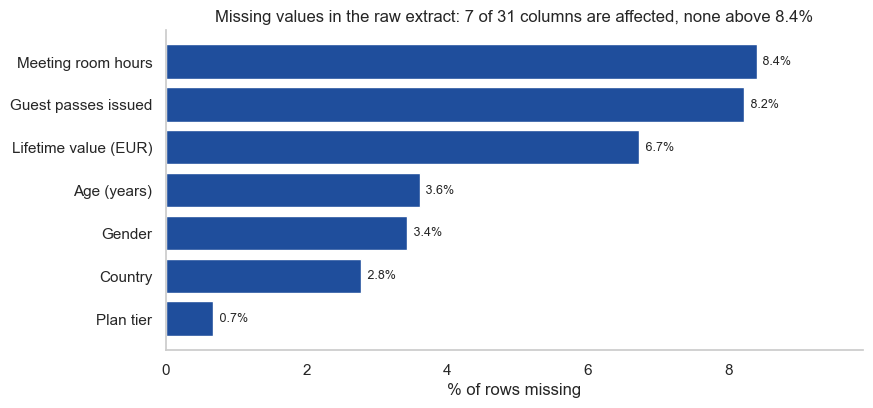

In [20]:
# Bar chart of the share of rows missing in each raw column, titled from the numbers it shows.
fig, ax = plt.subplots(figsize=(9, 0.38 * len(missing_pct_raw) + 1.5))
bars = ax.barh(range(len(missing_pct_raw)), missing_pct_raw.values, color=BLUE)
ax.set_yticks(range(len(missing_pct_raw)), [chart_label(c) for c in missing_pct_raw.index])
ax.bar_label(bars, fmt=" %.1f%%", fontsize=9, padding=2)
ax.set(xlabel="% of rows missing", xlim=(0, missing_pct_raw.max() * 1.18),
       title=f"Missing values in the raw extract: {len(missing_pct_raw)} of {raw.shape[1]} columns are affected, "
             f"none above {missing_pct_raw.max():.1f}%")
ax.grid(False)
sns.despine()
plt.show()

## 3.3 Data types

In [21]:
# Show the text formats hidden in lifetime_value and the dtypes of the date and add-on columns.
ltv_text = raw["lifetime_value"].astype("string")
has_euro = int(ltv_text.str.contains("\u20ac", regex=False).sum())
has_comma = int(ltv_text.str.contains(",", regex=False).sum())
print(f"lifetime_value with a currency sign: {has_euro} | with a thousands separator: {has_comma}")
examples = raw["lifetime_value"].dropna()
show_at = [int(i) for i in np.linspace(0, len(examples) - 1, 8)]
print("examples, spread evenly through the column:", examples.iloc[show_at].tolist())
print()
print(raw[[c for c in raw.columns if c.startswith("uses_")]].dtypes.to_frame("dtype").to_string())
print()
print(raw[date_features].head(3).to_string())
print("\nuses_print arrives as an int 0/1 while the other add-on flags are bool; the three date columns arrive as text.")

lifetime_value with a currency sign: 291 | with a thousands separator: 110
examples, spread evenly through the column: ['4477.97', '548.32', '322.12', '423.51', '325.29', '0', '224.35', '435.82']

                    dtype
uses_meeting_rooms   bool
uses_event_space     bool
uses_guest_passes    bool
uses_print          int64
uses_mail_handling   bool
uses_phone_booths    bool
uses_day_passes      bool
uses_storage         bool
uses_bike_locker     bool

  membership_start membership_end last_badge_swipe
0       2021-08-01     2023-03-06       2023-03-23
1       2023-11-24     1970-01-01       2023-11-24
2       2021-12-03     1970-01-01       2023-07-22

uses_print arrives as an int 0/1 while the other add-on flags are bool; the three date columns arrive as text.


In [22]:
# The one money parser used by the cells that need lifetime_value as a number. It only reads: it never writes
# back into the raw frame, so the parsed column in section 4.8 stays a documented decision rather than a side effect.
def money_to_number(series):
    """Turn money written as text into a number.

    Args:
        series: a text column holding amounts such as "1 234,56 \u20ac".

    Returns:
        A float column with the currency sign, the spaces and the thousands separator removed.
    """
    cleaned = (series.astype("string").str.replace("\u20ac", "", regex=False)
               .str.replace(" ", "", regex=False).str.replace(",", "", regex=False).str.strip())
    return pd.to_numeric(cleaned, errors="coerce").astype(float)


print("money parser defined; lifetime_value is still text in raw and is parsed in section 4.8")

money parser defined; lifetime_value is still text in raw and is parsed in section 4.8


## 3.4 Contradictions between fields
Two fields can each look valid and still disagree about the same member. We compare renewals with the length of the
membership, actual visits with the plan entitlement, and the recorded last visit with `days_since_last_visit`.
A breach is treated as a data-quality issue rather than as a modelling choice.

### The renewal rule and the sentinel value
A **sentinel value** is a number a system writes in place of a real one: `1970-01-01` in `membership_end` does not
record a date, it records "this membership has not ended". A renewal needs a month to renew in, so the rule compares
`n_renewals` with the membership length in months. Rows carrying that sentinel are excluded, because for them the end
date is a placeholder and `1970-01-01 - membership_start` is a large negative duration that makes any renewal count
as exceeding it.

In [23]:
# One parser for both documented date layouts. Defined here because section 3.4 has to read the dates as they
# arrive and section 4.3 reuses it when the columns are converted. It never changes the original column.
def parse_mixed_dates(series):
    """Read dates written in either documented layout.

    Args:
        series: a text column of dates, written as YYYY-MM-DD or as DD/MM/YYYY.

    Returns:
        A datetime column; a value in neither layout becomes a missing date.
    """
    stripped = series.astype("string").str.strip()
    is_dmy = stripped.str.contains("/", regex=False)
    parsed = pd.Series(pd.NaT, index=series.index, dtype="datetime64[ns]")
    parsed.loc[~is_dmy] = pd.to_datetime(stripped[~is_dmy], format="%Y-%m-%d")
    parsed.loc[is_dmy] = pd.to_datetime(stripped[is_dmy], format="%d/%m/%Y")
    return parsed


print("date parser defined; the layouts it accepts are YYYY-MM-DD and DD/MM/YYYY")

date parser defined; the layouts it accepts are YYYY-MM-DD and DD/MM/YYYY


In [24]:
# Read the dates as they arrive and measure the membership length each row implies.
start_parsed = parse_mixed_dates(raw["membership_start"])
end_parsed = parse_mixed_dates(raw["membership_end"])
months_as_read = (end_parsed - start_parsed).dt.days / 30.44
sentinel_end = end_parsed == pd.Timestamp("1970-01-01")
usable_duration = start_parsed.notna() & end_parsed.notna() & ~sentinel_end
measured_rows = usable_duration & (months_as_read > 0)

renewals_with_sentinel = int((raw["n_renewals"] > months_as_read).sum())
renewals_without_sentinel = int(((raw["n_renewals"] > months_as_read) & measured_rows).sum())
end_before_start = int((usable_duration & (end_parsed < start_parsed)).sum())
inflation = renewals_with_sentinel - renewals_without_sentinel
print(f"membership months usable for the renewal rule: {int(measured_rows.sum()):,} of {len(raw):,} rows")
print(f"renewals exceeding the membership length, sentinel included: {renewals_with_sentinel:,}")
print(f"renewals exceeding the membership length, sentinel excluded: {renewals_without_sentinel:,}")
print(f"the sentinel was inflating the count by {inflation:,} rows, "
      f"{inflation / max(renewals_with_sentinel, 1):.1%} of what the unadjusted rule reported")
print(f"rows carrying the sentinel end date: {int(sentinel_end.sum()):,}")

membership months usable for the renewal rule: 11,357 of 15,465 rows
renewals exceeding the membership length, sentinel included: 4,122
renewals exceeding the membership length, sentinel excluded: 15
the sentinel was inflating the count by 4,107 rows, 99.6% of what the unadjusted rule reported
rows carrying the sentinel end date: 3,956


In [25]:
# The six contradiction rules, counted on the raw data with the corrected renewal rule.
coherence_checks = pd.DataFrame({
    "rule": [
        "n_renewals > membership months (sentinel excluded)",
        "actual_visits_last_period > entitled_visits_last_period",
        "entitled_visits_last_period == 0 while the member has visits",
        "days_since_last_visit is 999 (sentinel)",
        "days_since_last_visit is negative (visit recorded in the future)",
        "membership_end before membership_start (sentinel and unparseable dates excluded)",
    ],
    "rows": [
        renewals_without_sentinel,
        int((raw["actual_visits_last_period"] > raw["entitled_visits_last_period"]).sum()),
        int(((raw["entitled_visits_last_period"] == 0) & (raw["actual_visits_last_period"] > 0)).sum()),
        int((raw["days_since_last_visit"] == 999).sum()),
        int((raw["days_since_last_visit"] < 0).sum()),
        end_before_start,
    ],
})
coherence_checks["pct_of_rows"] = (coherence_checks["rows"] / len(raw) * 100).round(2)
print(coherence_checks.to_string(index=False))

                                                                            rule  rows  pct_of_rows
                              n_renewals > membership months (sentinel excluded)    15         0.10
                         actual_visits_last_period > entitled_visits_last_period     8         0.05
                    entitled_visits_last_period == 0 while the member has visits     8         0.05
                                         days_since_last_visit is 999 (sentinel)  1298         8.39
                days_since_last_visit is negative (visit recorded in the future)    56         0.36
membership_end before membership_start (sentinel and unparseable dates excluded)   152         0.98


## 3.5 Placeholder codes and implausible values
Codes such as 999, -1 and 9 are only meaningful if the field behind them has room for them. We count them before
deciding anything. An age that lands in a tight band just outside the plausible range would read as a transcription
slip, while a spread of ages from 1 to 149 suggests a system code.

In [26]:
# The count and impossible-value checks on the raw file, one row per check.
ltv_as_number = money_to_number(raw["lifetime_value"])
negative_count_columns = ["total_visits", "n_renewals", "meeting_room_hours", "event_space_hours", "guest_passes_issued"]
placeholder_rows = [
    ("age < 18 or > 100", int(((raw["age"] < 18) | (raw["age"] > 100)).sum())),
    ("  of which age 1-14", int((raw["age"] < 15).sum())),
    ("  of which age 131-149", int((raw["age"] > 130).sum())),
    ("  of which age 15-17 or 101-130 (borderline)",
     int(((raw["age"].between(15, 17)) | (raw["age"].between(101, 130))).sum())),
    ("n_colleagues_on_account == -1", int((raw["n_colleagues_on_account"] == -1).sum())),
    ("days_since_last_visit == 999", int((raw["days_since_last_visit"] == 999).sum())),
    ("days_since_last_visit < 0", int((raw["days_since_last_visit"] < 0).sum())),
    ("plan_days_per_week == 0", int((raw["plan_days_per_week"] == 0).sum())),
    ("plan_days_per_week == 9", int((raw["plan_days_per_week"] == 9).sum())),
    ("plan_days_per_week == 7 (valid: private office)", int((raw["plan_days_per_week"] == 7).sum())),
    ("lifetime_value == 0", int((ltv_as_number == 0).sum())),
    ("lifetime_value < 0", int((ltv_as_number < 0).sum())),
]
for column in negative_count_columns:
    placeholder_rows.append((f"{column} < 0", int((raw[column] < 0).sum())))
print(pd.DataFrame(placeholder_rows, columns=["check", "rows"]).to_string(index=False))

                                          check  rows
                              age < 18 or > 100   143
                              of which age 1-14    98
                           of which age 131-149    45
     of which age 15-17 or 101-130 (borderline)     0
                  n_colleagues_on_account == -1   566
                   days_since_last_visit == 999  1298
                      days_since_last_visit < 0    56
                        plan_days_per_week == 0    43
                        plan_days_per_week == 9    54
plan_days_per_week == 7 (valid: private office)   719
                            lifetime_value == 0  1743
                             lifetime_value < 0    82
                               total_visits < 0    42
                                 n_renewals < 0    66
                         meeting_room_hours < 0    16
                          event_space_hours < 0     8
                        guest_passes_issued < 0     7


In [27]:
# Where the impossible ages actually sit, since two readings of them lead to different handling.
invalid_ages = raw.loc[(raw["age"] < 18) | (raw["age"] > 100), "age"]
print(f"impossible ages: {len(invalid_ages)} rows, running {invalid_ages.min():.0f} to {invalid_ages.max():.0f}")
print("values just inside the border (15-17 and 101-130):",
      int(((raw["age"].between(15, 17)) | (raw["age"].between(101, 130))).sum()))
print("Ages cluster in two bands, 1-14 and 131-149, with nothing near the borders. That reads as a system code")
print("rather than a transcription slip: an 8-year-old member and a 137-year-old member are both implausible.")

impossible ages: 143 rows, running 1 to 149
values just inside the border (15-17 and 101-130): 0
Ages cluster in two bands, 1-14 and 131-149, with nothing near the borders. That reads as a system code
rather than a transcription slip: an 8-year-old member and a 137-year-old member are both implausible.


## 3.6 Distribution shapes and heavy tails
The raw numeric columns are compared on quantiles. A variable whose maximum sits far above its own 99th percentile
is a candidate for a unit error rather than a heavy tail, and section 4.9 tests that reading.

In [28]:
# Quantiles of the variables with the heaviest tails, read from the raw export.
tail_columns = ["lifetime_value", "total_visits", "avg_weekly_visits", "meeting_room_hours", "event_space_hours",
                "guest_passes_issued", "days_since_last_visit", "n_renewals", "age"]
raw_numeric = raw.copy()
raw_numeric["lifetime_value"] = money_to_number(raw["lifetime_value"])
quantile_table = raw_numeric[tail_columns].quantile([0.25, 0.5, 0.75, 0.9, 0.99, 0.999, 1.0]).T
quantile_table.columns = ["p25", "p50", "p75", "p90", "p99", "p999", "max"]
quantile_table = quantile_table.round(2)
quantile_table["max / p99"] = (quantile_table["max"] / quantile_table["p99"]).round(1)
print(quantile_table.to_string())

                          p25     p50      p75       p90       p99        p999        max  max / p99
lifetime_value         252.77  825.04  5061.54  11261.19  25662.74  1107887.23  3371260.0      131.4
total_visits             8.00   34.00   132.00    373.00    693.36      883.22     6530.0        9.4
avg_weekly_visits        0.71    1.42     2.41      3.83      5.32       28.88       47.4        8.9
meeting_room_hours       0.00    0.00     7.20     79.54    326.80     1711.07    41220.0      126.1
event_space_hours        0.00    0.00     0.00      1.40    126.96      332.18      602.8        4.7
guest_passes_issued      0.00    0.00     0.00     15.00    117.07      248.81      589.0        5.0
days_since_last_visit    4.00   13.00    55.00    262.60    999.00      999.00     1212.0        1.2
n_renewals               0.00    0.00     2.00      3.00      5.00        6.00        6.0        1.2
age                     29.00   34.00    40.00     46.00     57.00      141.00      149.0  

In [29]:
# Which columns show that gap most sharply.
widest = quantile_table.sort_values("max / p99", ascending=False).head(3)
print("largest gaps between the 99th percentile and the maximum:")
print(widest[["p99", "max", "max / p99"]].to_string())
print("\nA large gap says the last rows are not part of the same distribution as the rest of the column.")
print("Section 4.9 tests that pattern against a unit error before deciding how to treat the rows.")

largest gaps between the 99th percentile and the maximum:
                         p99        max  max / p99
lifetime_value      25662.74  3371260.0      131.4
meeting_room_hours    326.80    41220.0      126.1
total_visits          693.36     6530.0        9.4

A large gap says the last rows are not part of the same distribution as the rest of the column.
Section 4.9 tests that pattern against a unit error before deciding how to treat the rows.


### Issues found
| Area | Issue seen in the raw data |
|---|---|
| Rows | exact duplicates |
| Text categories | spelling / case / language variants in `gender`, `country`, `industry`, `plan_tier` |
| Dates | stored as text, two formats mixed (`YYYY-MM-DD` and `DD/MM/YYYY`), sentinel `1970-01-01` in `membership_end` |
| Placeholders | `days_since_last_visit` = 999, `n_colleagues_on_account` = -1, `plan_days_per_week` in {0, 9}, `lifetime_value` = 0 (tested in section 4.8) |
| Impossible values | negative counts / hours / values, ages outside 18-100 in two clusters |
| Types | `lifetime_value` text with a currency sign and a thousands separator; `uses_print` int instead of bool |
| Tails | very large `lifetime_value`, `total_visits`, `meeting_room_hours` (tested in section 4.9) |
| Coherence | `n_renewals` above the membership length after the active sentinel is excluded, visits above the plan entitlement, `entitled = 0` with visits recorded, `membership_end` before `membership_start` |
| Overlap | the missing `meeting_room_hours` rows and the `days_since_last_visit` = 999 rows are equal in size but are different members (section 3.2) |

So what: the file carries exact duplicates, silent gaps, a sentinel date, placeholder codes, impossible ages and a
handful of values so far above their own 99th percentile that they must be tested before they are used.

# 4. Data-quality handling
We correct documented errors and placeholders while retaining valid extreme observations. Each decision is recorded
in a flag column, so its effect on any later analysis can be reviewed. Nothing is imputed, nothing is capped and no
row is deleted except the exact duplicates.

## 4.1 Remove exact duplicates

In [30]:
# Drop exact duplicate rows (keep first) and report whether the identifier is then unique.
analysis_data = raw.drop_duplicates(keep="first").copy()
n_duplicates_removed = int(len(raw) - len(analysis_data))
print(f"rows before: {len(raw):,} | after: {len(analysis_data):,} | removed: {n_duplicates_removed}")
check(analysis_data["member_id"].is_unique, "member_id is not unique after the duplicate removal - the pairs differ in some field")
print("member_id unique now:", bool(analysis_data["member_id"].is_unique))

rows before: 15,465 | after: 15,450 | removed: 15
member_id unique now: True


## 4.2 Category labels
Variants such as `FLEX`, `Flex ` and `Portucal` describe the same category. We map them explicitly and check that
the number of missing values does not change: a mapping that turns an unmapped variant into NaN would be losing data.

In [31]:
# The mapping helper, used by all four text columns: strip the spaces, lower-case the text and look the result up
# in a mapping written below. For plan tier, spaces become underscores first, since "Hot Desk" and "hot_desk" are
# the same plan.
def standardise(series, mapping, name, replace_spaces=False):
    """Map spelling variants to standard labels and report what the mapping did.

    Args:
        series: the text column to clean.
        mapping: a dictionary from a lower-cased variant to its standard label.
        name: the column name, used in the printed report.
        replace_spaces: True when spaces in the raw text stand for underscores, as they do in plan_tier.

    Returns:
        A cleaned text column with one standard label per category.
    """
    key = series.str.strip().str.lower()
    if replace_spaces:
        key = key.str.replace(" ", "_", regex=False)
    mapped = key.map(mapping)
    nan_before, nan_after = int(series.isna().sum()), int(mapped.isna().sum())
    unmapped = sorted(key[mapped.isna() & key.notna()].unique())
    check(nan_before == nan_after, f"{name}: NaN count moved {nan_before} -> {nan_after}; unmapped variants: {unmapped}")
    print(f"{name:10s} NaN before = {nan_before:4d} | after = {nan_after:4d} | distinct labels "
          f"{series.nunique()} -> {mapped.nunique()}" + (f" | UNMAPPED: {unmapped}" if unmapped else ""))
    return mapped


category_columns = ["gender", "country", "industry", "plan_tier"]
raw_categories = analysis_data[category_columns].copy()      # kept to count how many rows the mapping changed
print(f"mapping helper defined; {len(category_columns)} text columns will be standardised: {', '.join(category_columns)}")
print("the check inside it compares the NaN count before and after each mapping, so a lost label is reported")

mapping helper defined; 4 text columns will be standardised: gender, country, industry, plan_tier
the check inside it compares the NaN count before and after each mapping, so a lost label is reported


In [32]:
# Standardise gender and country.
gender_mapping = {"female": "Female", "f": "Female", "male": "Male", "m": "Male", "other": "Other", "o": "Other"}
analysis_data["gender"] = standardise(analysis_data["gender"], gender_mapping, "gender")

country_mapping = {
    "portugal": "Portugal", "pt": "Portugal", "portucal": "Portugal",
    "germany": "Germany", "de": "Germany", "deutschland": "Germany",
    "united kingdom": "United Kingdom", "uk": "United Kingdom", "gb": "United Kingdom", "u.k.": "United Kingdom",
    "spain": "Spain", "es": "Spain", "espa\u00f1a": "Spain", "espana": "Spain",
    "france": "France", "fr": "France",
    "netherlands": "Netherlands", "the netherlands": "Netherlands", "nl": "Netherlands", "holland": "Netherlands",
    "ireland": "Ireland", "ie": "Ireland",
    "other (europe)": "Other (Europe)",
}
analysis_data["country"] = standardise(analysis_data["country"], country_mapping, "country")

gender     NaN before =  530 | after =  530 | distinct labels 12 -> 3
country    NaN before =  429 | after =  429 | distinct labels 33 -> 8


In [33]:
# Standardise industry and plan tier.
industry_mapping = {
    "information technology": "Information Technology", "it": "Information Technology", "tech": "Information Technology",
    "consulting": "Consulting",
    "design & creative": "Design & Creative", "design/creative": "Design & Creative", "design and creative": "Design & Creative",
    "marketing & pr": "Marketing & PR", "marketing/pr": "Marketing & PR", "marketing and pr": "Marketing & PR",
    "finance": "Finance", "legal": "Legal", "education": "Education", "health": "Health",
    "real estate": "Real Estate", "realestate": "Real Estate", "real-estate": "Real Estate",
    "unknown": "Unknown", "other": "Other",
}
analysis_data["industry"] = standardise(analysis_data["industry"], industry_mapping, "industry")

plan_mapping = {
    "flex": "flex",
    "hot_desk": "hot_desk", "hotdesk": "hot_desk",
    "dedicated_desk": "dedicated_desk", "dedicateddesk": "dedicated_desk",
    "full_time": "full_time", "fulltime": "full_time",
    "private_office": "private_office", "privateoffice": "private_office",
}
analysis_data["plan_tier"] = standardise(analysis_data["plan_tier"], plan_mapping, "plan_tier", replace_spaces=True)

industry   NaN before =    0 | after =    0 | distinct labels 43 -> 11


plan_tier  NaN before =  105 | after =  105 | distinct labels 19 -> 5


In [34]:
# Report the mapped categories and how many rows each mapping changed.
for column in category_columns:
    print(f"--- {column}")
    print(analysis_data[column].value_counts(dropna=False).to_string())
    print()

rows_with_variant = pd.Series(False, index=analysis_data.index)
variants_fixed = {}
for column in category_columns:
    changed = raw_categories[column].notna() & (raw_categories[column] != analysis_data[column])
    variants_fixed[column] = int(changed.sum())
    rows_with_variant |= changed
n_variants_rows = int(rows_with_variant.sum())
n_portugal = int((analysis_data["country"] == "Portugal").sum())
top_country = analysis_data["country"].value_counts().index[0]
top_industry = analysis_data["industry"].value_counts().index[0]
top_plan_tier = analysis_data["plan_tier"].value_counts().index[0]
print("rows changed per column:", variants_fixed)
print(f"{n_variants_rows:,} rows ({n_variants_rows / len(analysis_data):.1%}) carried at least one variant label")
print(f"{top_country}: {n_portugal:,} of {len(analysis_data):,} = {n_portugal / len(analysis_data):.1%} of all rows "
      f"({n_portugal / analysis_data['country'].notna().sum():.1%} of the rows with a known country)")
print(f"largest industry: {top_industry} | largest plan tier: {top_plan_tier}")

--- gender
gender
Female    7858
Male      6565
NaN        530
Other      497

--- country
country
Portugal          10499
United Kingdom     1165
Germany             901
Spain               741
France              533
Netherlands         487
Other (Europe)      451
NaN                 429
Ireland             244

--- industry
industry
Information Technology    3557
Consulting                2055
Design & Creative         1974
Marketing & PR            1962
Finance                   1219
Other                     1175
Legal                      878
Education                  775
Unknown                    693
Health                     601
Real Estate                561

--- plan_tier
plan_tier
flex              5449
hot_desk          5212
full_time         2471
dedicated_desk    1549
private_office     664
NaN                105



rows changed per column: {'gender': 884, 'country': 776, 'industry': 1079, 'plan_tier': 768}
3,238 rows (21.0%) carried at least one variant label
Portugal: 10,499 of 15,450 = 68.0% of all rows (69.9% of the rows with a known country)
largest industry: Information Technology | largest plan tier: flex


In [35]:
# Report the final category sets and confirm the mappings did not create missing values.
check(set(analysis_data["gender"].dropna().unique()) == {"Female", "Male", "Other"},
      f"unexpected gender labels: {sorted(analysis_data['gender'].dropna().unique())}")
check(set(analysis_data["plan_tier"].dropna().unique()) == set(tier_order),
      f"unexpected plan tiers: {sorted(analysis_data['plan_tier'].dropna().unique())}")
check(set(analysis_data["country"].dropna().unique()) == {"Portugal", "United Kingdom", "Germany", "Spain", "France",
                                                    "Netherlands", "Ireland", "Other (Europe)"},
      f"unexpected countries: {sorted(analysis_data['country'].dropna().unique())}")
check(analysis_data["industry"].nunique() == 11, f"expected 11 industries, found {analysis_data['industry'].nunique()}")
for column in category_columns:
    check(analysis_data[column].isna().sum() == raw_categories[column].isna().sum(),
          f"{column}: the mapping changed the NaN count")
print("label sets after mapping:", {c: int(analysis_data[c].nunique()) for c in category_columns})
print("NaN counts after mapping:", {c: int(analysis_data[c].isna().sum()) for c in category_columns})

label sets after mapping: {'gender': 3, 'country': 8, 'industry': 11, 'plan_tier': 5}


NaN counts after mapping: {'gender': 530, 'country': 429, 'industry': 0, 'plan_tier': 105}


## 4.3 Date formats
About 4% of the dates use `DD/MM/YYYY`, while the rest use `YYYY-MM-DD`. We count the formats, prove that the slash
format is day-first from the numbers themselves, and only then parse it. The `flag_date_format_dmy` column records
which rows carried the second format: that is a formatting issue, distinct from the `1970-01-01` sentinel recorded in
section 4.5, and the two are counted separately in section 11.

In [36]:
# Count the date formats in the raw strings of each date column.
analysis_data["flag_date_format_dmy"] = False      # True if any of the three date strings uses DD/MM/YYYY
for column in date_features:
    series = analysis_data[column].str.strip()
    n_slash = int(series.str.contains("/", regex=False).sum())
    n_iso = int(series.str.fullmatch(r"\d{4}-\d{2}-\d{2}").sum())
    n_other = len(series) - n_slash - n_iso
    check(n_other == 0, f"{column}: {n_other} rows in a third date format - the parser below will not cover them")
    print(f"{column:17s} DD/MM/YYYY = {n_slash:4d} ({n_slash / len(series):.1%}) | YYYY-MM-DD = {n_iso:5d} | other = {n_other}")
    analysis_data["flag_date_format_dmy"] |= series.str.contains("/", regex=False)
n_dmy_rows = int(analysis_data["flag_date_format_dmy"].sum())
print(f"rows with at least one DD/MM/YYYY date: {n_dmy_rows:,} ({n_dmy_rows / len(analysis_data):.1%})")

membership_start  DD/MM/YYYY =  637 (4.1%) | YYYY-MM-DD = 14813 | other = 0
membership_end    DD/MM/YYYY =  461 (3.0%) | YYYY-MM-DD = 14989 | other = 0
last_badge_swipe  DD/MM/YYYY =  637 (4.1%) | YYYY-MM-DD = 14813 | other = 0
rows with at least one DD/MM/YYYY date: 637 (4.1%)


In [37]:
# Prove the slash dates are day-first before parsing them as such: in a real DD/MM/YYYY the second position
# (the month) can never exceed 12, while the first position (the day) often does.
proof_rows = []
for column in date_features:
    series = analysis_data[column].str.strip()
    parts = series[series.str.contains("/", regex=False)].str.split("/", expand=True).astype(int)
    first_gt12 = int((parts[0] > 12).sum())
    second_gt12 = int((parts[1] > 12).sum())
    proof_rows.append({"column": column, "slash_dates": len(parts), "first_number_gt_12": first_gt12,
                       "second_number_gt_12": second_gt12})
    check(second_gt12 == 0, f"{column}: {second_gt12} second numbers above 12, so day-first is not certain")
    check(first_gt12 > 0, f"{column}: no first number above 12, so this column cannot prove the format")
day_first_proof = pd.DataFrame(proof_rows)
print(day_first_proof.to_string(index=False))
print("\nThe second number never exceeds 12 while the first often does, which fixes the order as DD/MM/YYYY.")

          column  slash_dates  first_number_gt_12  second_number_gt_12
membership_start          637                 366                    0
  membership_end          461                 276                    0
last_badge_swipe          637                 440                    0

The second number never exceeds 12 while the first often does, which fixes the order as DD/MM/YYYY.


In [38]:
# Parse both formats with the helper written in section 3.4: the ISO layout where there is no slash, the proven
# day-first layout where there is. The columns are replaced in place, so every later section reads real dates.
for column in date_features:
    analysis_data[column] = parse_mixed_dates(analysis_data[column])
n_nat_after_parse = int(analysis_data[date_features].isna().sum().sum())
check(n_nat_after_parse == 0, f"{n_nat_after_parse} dates did not parse with the two documented formats")
print("missing dates after parsing:", analysis_data[date_features].isna().sum().to_dict())
print(analysis_data[date_features].agg(["min", "max"]).T.to_string())

missing dates after parsing:

 {'membership_start': 0, 'membership_end': 0, 'last_badge_swipe': 0}


                        min        max
membership_start 2021-01-01 2023-12-30
membership_end   1970-01-01 2024-01-01
last_badge_swipe 2020-09-06 2024-04-28


## 4.4 Placeholders and impossible values
Negative counts and ages outside the documented range are treated as missing. Codes such as 999 and -1 are
interpreted from the meaning of the field rather than converted mechanically.

In [39]:
# Ages outside 18-100 become NaN with a flag; uses_print becomes bool.
analysis_data["flag_age_invalid"] = (analysis_data["age"] < 18) | (analysis_data["age"] > 100)
invalid_age = analysis_data.loc[analysis_data["flag_age_invalid"], "age"]
n_age_invalid = int(len(invalid_age))
n_borderline = int(((analysis_data["age"] >= 15) & (analysis_data["age"] <= 17)).sum()
                   + ((analysis_data["age"] >= 101) & (analysis_data["age"] <= 130)).sum())
analysis_data.loc[analysis_data["flag_age_invalid"], "age"] = np.nan
print(f"age set to NaN: {n_age_invalid} rows")
print(f"impossible values run {invalid_age.min():.0f}-{invalid_age[invalid_age < 18].max():.0f} and "
      f"{invalid_age[invalid_age > 100].min():.0f}-{invalid_age.max():.0f}; borderline rows (15-17, 101-130): {n_borderline}")
check(n_borderline == 0, "borderline ages exist, so the 18-100 bound cuts through a populated range - revisit the bound")
print(f"valid age range now: {analysis_data['age'].min():.0f}-{analysis_data['age'].max():.0f}")
check(set(analysis_data["uses_print"].unique()) <= {0, 1}, "uses_print holds values other than 0 and 1")
analysis_data["uses_print"] = analysis_data["uses_print"].astype(bool)
print("uses_print dtype:", analysis_data["uses_print"].dtype)

age set to NaN: 143 rows
impossible values run 1-14 and 131-149; borderline rows (15-17, 101-130): 0
valid age range now: 18-93
uses_print dtype: bool


In [40]:
# n_colleagues_on_account == -1. An individual has no colleagues, so -1 is read as 0; a team account with -1 has an
# unknown size, so it becomes NaN. The account type decides, which is why the two are crossed before the rule.
carries_minus_one = analysis_data["n_colleagues_on_account"] == -1
print(pd.crosstab(analysis_data["is_team_account"], carries_minus_one,
                  margins=True, margins_name="all").to_string())
print("(columns: False = the row does not carry -1, True = it does)")
analysis_data["flag_n_colleagues_placeholder"] = carries_minus_one
is_individual = ~analysis_data["is_team_account"]
n_to_zero = int((analysis_data["flag_n_colleagues_placeholder"] & is_individual).sum())
n_to_nan = int((analysis_data["flag_n_colleagues_placeholder"] & ~is_individual).sum())
analysis_data.loc[analysis_data["flag_n_colleagues_placeholder"] & is_individual, "n_colleagues_on_account"] = 0
analysis_data.loc[analysis_data["flag_n_colleagues_placeholder"] & ~is_individual, "n_colleagues_on_account"] = np.nan
print(f"\n-1 handled: {int(analysis_data['flag_n_colleagues_placeholder'].sum()):,} "
      f"(read as 0 for individuals: {n_to_zero:,}, set to missing for teams: {n_to_nan:,})")

n_colleagues_on_account  False  True    all
is_team_account                            
False                    10688   412  11100
True                      4197   153   4350
all                      14885   565  15450


(columns: False = the row does not carry -1, True = it does)

-1 handled: 565 (read as 0 for individuals: 412, set to missing for teams: 153)


In [41]:
# Sentinel and impossible codes in the recency and usage columns become NaN with one flag per rule.
n_days_999 = int((analysis_data["days_since_last_visit"] == 999).sum())
n_days_negative = int((analysis_data["days_since_last_visit"] < 0).sum())
analysis_data["flag_days_since_last_visit_invalid"] = (analysis_data["days_since_last_visit"] == 999) | (analysis_data["days_since_last_visit"] < 0)
analysis_data.loc[analysis_data["flag_days_since_last_visit_invalid"], "days_since_last_visit"] = np.nan
print(f"days_since_last_visit: 999 -> {n_days_999:,} rows, negative -> {n_days_negative:,} rows, "
      f"set to NaN: {int(analysis_data['flag_days_since_last_visit_invalid'].sum()):,}")

for column in negative_count_columns:
    analysis_data[f"flag_{column}_negative"] = analysis_data[column] < 0
    analysis_data.loc[analysis_data[f"flag_{column}_negative"], column] = np.nan
    print(f"{column:22s} negative -> NaN: {int(analysis_data[f'flag_{column}_negative'].sum()):}")
print("\n999 is read as 'no recency recorded', not as 999 days: the code sits exactly where a system default would,")
print("and a member cannot be 999 days inactive inside a three-year extract and still be marked active.")

days_since_last_visit: 999 -> 1,298 rows, negative -> 56 rows, set to NaN: 1,354
total_visits           negative -> NaN: 42
n_renewals             negative -> NaN: 66
meeting_room_hours     negative -> NaN: 16
event_space_hours      negative -> NaN: 8
guest_passes_issued    negative -> NaN: 7

999 is read as 'no recency recorded', not as 999 days: the code sits exactly where a system default would,
and a member cannot be 999 days inactive inside a three-year extract and still be marked active.


## 4.5 Membership status and reference date
`membership_end = 1970-01-01` is a sentinel for an active member: no membership can have ended in 1970 inside a file
whose earliest start is 2021. The extract carries no stated extraction date, so we infer it from the last badge swipe
and the recorded days since that visit. The resulting share of ended members covers the three-year window; it is not
an annual churn rate.

In [42]:
# Create is_active and status from the 1970-01-01 sentinel, then record the window the file covers.
analysis_data["is_active"] = analysis_data["membership_end"] == pd.Timestamp("1970-01-01")
analysis_data["status"] = analysis_data["is_active"].map({True: "active", False: "ended"})
n_active, n_ended = int(analysis_data["is_active"].sum()), int((~analysis_data["is_active"]).sum())
pct_active = n_active / len(analysis_data) * 100
pct_ended = n_ended / len(analysis_data) * 100
window_first_start = analysis_data["membership_start"].min()
window_last_start = analysis_data["membership_start"].max()
window_years = (window_last_start - window_first_start).days / 365.25
print(f"active = {n_active:,} ({pct_active:.1f}%) | ended = {n_ended:,} ({pct_ended:.1f}%)")
print(f"membership_start range: {window_first_start.date()} -> {window_last_start.date()} "
      f"({window_years:.2f} years of starts)")
print(f"The {pct_ended:.1f}% ended is a cumulative share over a {window_years:.0f}-year window, not a yearly churn rate.")

active = 3,954 (25.6%) | ended = 11,496 (74.4%)
membership_start range: 2021-01-01 -> 2023-12-30 (2.99 years of starts)
The 74.4% ended is a cumulative share over a 3-year window, not a yearly churn rate.


In [43]:
# The same status split counted by year of joining, since that is what section 7 reads.
members_by_start_year = analysis_data["membership_start"].dt.year.value_counts().sort_index()
print("members by year of joining:", {int(y): int(n) for y, n in members_by_start_year.items()})

members by year of joining: {2021: 7626, 2022: 4449, 2023: 3375}


In [44]:
# Infer the reference date. Where recency is recorded, last_badge_swipe + days_since_last_visit is the date the file
# was extracted. The most frequent of those implied dates is the candidate.
implied_date = analysis_data["last_badge_swipe"] + pd.to_timedelta(analysis_data["days_since_last_visit"], unit="D")
active_usable = analysis_data["is_active"] & ~analysis_data["flag_days_since_last_visit_invalid"]
print("most frequent implied dates (active members with a usable days_since_last_visit):")
print(implied_date[active_usable].value_counts().head(4).to_string())
reference_date = implied_date[active_usable].mode()[0]
max_real_end = analysis_data.loc[~analysis_data["is_active"], "membership_end"].max()
print(f"\nreference date = {reference_date.date()} (the most frequent implied date)")
print(f"latest membership_end among the rows without the sentinel = {max_real_end.date()}")
check(reference_date == max_real_end,
      f"the two estimates of the reference date disagree ({reference_date.date()} vs {max_real_end.date()}) - "
      "recency measures anchored on the mode would shift by the difference")

most frequent implied dates (active members with a usable days_since_last_visit):
2024-01-01    3288
2023-12-31     231
2023-12-28       4
2023-12-29       3

reference date = 2024-01-01 (the most frequent implied date)
latest membership_end among the rows without the sentinel = 2024-01-01


True

In [45]:
# How well that candidate holds up, checked separately for the active and the ended members.
n_active_usable = int(active_usable.sum())
n_exact = int((implied_date[active_usable] == reference_date).sum())
n_within1 = int(implied_date[active_usable].isin([reference_date, reference_date - pd.Timedelta(days=1)]).sum())
ended_usable = ~analysis_data["is_active"] & ~analysis_data["flag_days_since_last_visit_invalid"]
n_end_usable = int(ended_usable.sum())
n_end_match = int((implied_date[ended_usable] == analysis_data.loc[ended_usable, "membership_end"]).sum())
print(f"active  : {n_exact:,} / {n_active_usable:,} = {n_exact / n_active_usable:.1%} exactly on {reference_date.date()}, "
      f"{n_within1 / n_active_usable:.1%} on that date or the day before")
print(f"ended   : {n_end_match:,} / {n_end_usable:,} = {n_end_match / n_end_usable:.1%} have "
      "last_badge_swipe + days_since_last_visit equal to membership_end")

active  : 3,288 / 3,573 = 92.0% exactly on 2024-01-01, 98.5% on that date or the day before
ended   : 9,855 / 10,523 = 93.7% have last_badge_swipe + days_since_last_visit equal to membership_end


In [46]:
# Why the last badge swipe in the file is not the extraction date.
last_swipe = analysis_data["last_badge_swipe"].max()
n_swipe_past_reference = int((analysis_data["last_badge_swipe"] > reference_date).sum())
print(f"last badge swipe in the file: {last_swipe.date()}, {(last_swipe - reference_date).days} days past the "
      f"reference date, {n_swipe_past_reference} members swiping after it")
print("Badge swipes run past the reference date, so the last swipe cannot be read as the extraction date. The")
print("reference date is used only to anchor recency and tenure for the members still in the base.")

last badge swipe in the file: 2024-04-28, 118 days past the reference date, 34 members swiping after it
Badge swipes run past the reference date, so the last swipe cannot be read as the extraction date. The
reference date is used only to anchor recency and tenure for the members still in the base.


### Two meanings of recency, one feature
For an ended membership, "days since the last visit" is naturally measured to the membership end; for an active
member it is measured to the reference date. We keep one `recency_days` feature (section 8) and carry `status` beside
it, so the two populations are never pooled by accident. The raw `days_since_last_visit` column is kept untouched as
a cross-check, and section 8 reports how far the two agree.

## 4.6 Tenure

In [47]:
# Tenure in months: to membership_end for an ended member, to the reference date for an active one. The sentinel
# is never used as an end date here, which is what makes tenure usable for active members at all.
end_for_tenure = analysis_data["membership_end"].where(~analysis_data["is_active"], reference_date)
tenure_raw = (end_for_tenure - analysis_data["membership_start"]).dt.days / 30.44
analysis_data["flag_tenure_nonpositive"] = tenure_raw <= 0
analysis_data["tenure_months"] = tenure_raw.where(~analysis_data["flag_tenure_nonpositive"])
n_end_before_start = int((tenure_raw < 0).sum())
n_end_equals_start = int((tenure_raw == 0).sum())
print(f"end before start: {n_end_before_start:,} | end == start: {n_end_equals_start:,} | "
      f"set to NaN: {int(analysis_data['flag_tenure_nonpositive'].sum()):,}")
print(analysis_data["tenure_months"].describe().round(2).to_string())
print("\nTenure is a derived duration, so the rows whose end precedes their start carry a flag and no value.")

end before start: 152 | end == start: 0 | set to NaN: 152
count    15298.00
mean        12.31
std         11.13
min          0.07
25%          2.14
50%          9.28
75%         20.93
max         35.97

Tenure is a derived duration, so the rows whose end precedes their start carry a flag and no value.


## 4.7 Plan days per week, and what the plan fields really encode
`plan_days_per_week` and `entitled_visits_last_period` are not independent: the plan tier fixes the number of days,
and the entitlement is a near-exact multiple of those days. We establish that structure first, because it decides
which of the two columns carries information and how the impossible day counts should be read.

In [48]:
# What each plan tier actually contains: the day counts it uses, and the entitlement that goes with them.
tier_rows = []
for tier in analysis_data["plan_tier"].dropna().unique():
    in_tier = analysis_data["plan_tier"] == tier
    days_seen = sorted({int(v) for v in analysis_data.loc[in_tier, "plan_days_per_week"].dropna()})
    tier_rows.append({"plan_tier": tier, "members": int(in_tier.sum()), "day_values_seen": days_seen,
                      "median_days": analysis_data.loc[in_tier, "plan_days_per_week"].median(),
                      "median_entitled": analysis_data.loc[in_tier, "entitled_visits_last_period"].median()})
tier_structure = pd.DataFrame(tier_rows).set_index("plan_tier").sort_values("median_days")
tier_structure["entitled_per_plan_day"] = (tier_structure["median_entitled"] / tier_structure["median_days"]).round(2)
print(tier_structure.to_string())
print("median days per week by tier:", {t: float(v) for t, v in tier_structure["median_days"].items()})

                members day_values_seen  median_days  median_entitled  entitled_per_plan_day
plan_tier                                                                                   
hot_desk           5212       [0, 2, 9]          2.0            17.39                    8.7
flex               5449       [0, 3, 9]          3.0            26.09                    8.7
dedicated_desk     1549       [0, 5, 9]          5.0            43.48                    8.7
full_time          2471       [0, 5, 9]          5.0            43.48                    8.7
private_office      664       [0, 7, 9]          7.0            60.87                    8.7
median days per week by tier: {'hot_desk': 2.0, 'flex': 3.0, 'dedicated_desk': 5.0, 'full_time': 5.0, 'private_office': 7.0}


In [49]:
# Does the entitlement simply restate the plan days? Divide one by the other for every member with a valid day count.
valid_days = analysis_data["plan_days_per_week"].isin([1, 2, 3, 4, 5, 6, 7])
per_member_ratio = analysis_data["entitled_visits_last_period"] / analysis_data["plan_days_per_week"].where(valid_days)
entitled_per_day = float(per_member_ratio.median())
n_ratio_exact = int((per_member_ratio - entitled_per_day).abs().le(0.01).sum())
print(f"entitled visits per plan day, per member: median {entitled_per_day:.3f}, "
      f"IQR {per_member_ratio.quantile(0.25):.3f}-{per_member_ratio.quantile(0.75):.3f}")
print(f"{n_ratio_exact:,} of {int(per_member_ratio.notna().sum()):,} rows with a valid day count sit within 0.01 of that ratio")
print(f"Reading: entitled_visits_last_period is plan_days_per_week multiplied by roughly {entitled_per_day:.1f} "
      "visits per plan-day per period. It re-encodes the plan; it does not measure usage.")

entitled visits per plan day, per member: median 8.696, IQR 8.695-8.697
11,950 of 15,353 rows with a valid day count sit within 0.01 of that ratio
Reading: entitled_visits_last_period is plan_days_per_week multiplied by roughly 8.7 visits per plan-day per period. It re-encodes the plan; it does not measure usage.


In [50]:
# Are the day counts 0 and 9 placeholders or real values? Compare each row's entitlement with the days its tier implies.
valid_days_by_tier = {}
for tier in tier_order:
    in_tier = (analysis_data["plan_tier"] == tier) & valid_days
    valid_days_by_tier[tier] = analysis_data.loc[in_tier, "plan_days_per_week"].median()
print("days per week implied by each tier:", {t: float(v) for t, v in valid_days_by_tier.items()})

suspect_days = analysis_data["plan_days_per_week"].isin([0, 9])
implied_days = (analysis_data["entitled_visits_last_period"] / entitled_per_day).round(1)
suspect_frame = pd.DataFrame({
    "member_id": analysis_data["member_id"],
    "plan_tier": label_missing(analysis_data["plan_tier"]),
    "plan_days_per_week": analysis_data["plan_days_per_week"],
    "implied_days_from_entitlement": implied_days,
})
suspect_frame["tier_implied_days"] = suspect_frame["plan_tier"].map(valid_days_by_tier)
suspect_frame = suspect_frame.loc[suspect_days]
suspect_summary = suspect_frame.groupby(["plan_tier", "plan_days_per_week"]).agg(
    rows=("member_id", "size"), tier_implied_days=("tier_implied_days", "first"),
    median_implied_days=("implied_days_from_entitlement", "median")).round(1)
print(suspect_summary.to_string())
n_known_tier = int(suspect_frame["plan_tier"].ne("(missing)").sum())
n_matching_tier = int((suspect_frame["implied_days_from_entitlement"] == suspect_frame["tier_implied_days"]).sum())
print(f"\n{int(suspect_days.sum())} rows carry 0 or 9; {n_known_tier:,} of them have a plan tier and "
      f"{n_matching_tier:,} have an entitlement that matches that tier's day count")
nine_rows = suspect_frame.loc[suspect_frame["plan_days_per_week"] == 9, "implied_days_from_entitlement"]
print(f"for the rows coded 9 the entitlement implies about {nine_rows.median():.0f} visits per period, which is 9 "
      "times the same factor")
print("Finding: the impossible day count is recoverable from the plan tier, and for the 9 rows the code has")
print("propagated into a second field. We record that and leave both columns as they are: writing the recovered")
print("value in would be filling a gap the client never asked us to fill.")

days per week implied by each tier: {'hot_desk': 2.0, 'flex': 3.0, 'dedicated_desk': 5.0, 'full_time': 5.0, 'private_office': 7.0}
                                   rows  tier_implied_days  median_implied_days
plan_tier      plan_days_per_week                                              
dedicated_desk 0                      3                5.0                  5.0
               9                      6                5.0                  9.0
flex           0                     20                3.0                  3.0
               9                     22                3.0                  3.2
full_time      0                      5                5.0                  0.0
               9                     10                5.0                  7.0
hot_desk       0                     14                2.0                  2.0
               9                     15                2.0                  9.0
private_office 0                      1                7.0           

In [51]:
# The same question in reverse: the rows with no plan tier. Their day count is present, so the tier could be
# inferred from it - except for day count 5, which two different tiers share.
missing_tier = analysis_data["plan_tier"].isna()
print(f"rows with no plan tier: {int(missing_tier.sum()):,} ({missing_tier.mean():.1%})")
print("their plan_days_per_week values:",
      {int(k): int(v) for k, v in analysis_data.loc[missing_tier, "plan_days_per_week"].value_counts().sort_index().items()})
tiers_per_day = analysis_data.dropna(subset=["plan_tier"]).groupby("plan_days_per_week")["plan_tier"].nunique()
print("tiers sharing a day count (plan_days -> how many tiers use it):", {int(k): int(v) for k, v in tiers_per_day.items()})
n_ambiguous = int(analysis_data.loc[missing_tier, "plan_days_per_week"].map(tiers_per_day).gt(1).sum())
print(f"of those {int(missing_tier.sum()):,} rows, {n_ambiguous:,} carry a day count shared by more than one tier, "
      "so the tier is not recoverable from it")
print("Handling: the tier stays missing and appears as its own level '(missing)' wherever plan tier is used.")

rows with no plan tier: 105 (0.7%)
their plan_days_per_week values: {5: 49, 7: 56}
tiers sharing a day count (plan_days -> how many tiers use it): {0: 5, 2: 1, 3: 1, 5: 2, 7: 1, 9: 5}
of those 105 rows, 49 carry a day count shared by more than one tier, so the tier is not recoverable from it
Handling: the tier stays missing and appears as its own level '(missing)' wherever plan tier is used.


In [52]:
# Apply the plan-days decision: 0 and 9 become NaN with a flag, 7 is retained.
analysis_data["flag_plan_days_invalid"] = analysis_data["plan_days_per_week"].isin([0, 9])
n_days_zero = int((analysis_data["plan_days_per_week"] == 0).sum())
n_days_nine = int((analysis_data["plan_days_per_week"] == 9).sum())
n_days_seven = int((analysis_data["plan_days_per_week"] == 7).sum())
analysis_data.loc[analysis_data["flag_plan_days_invalid"], "plan_days_per_week"] = np.nan
print(f"plan_days 0: {n_days_zero} rows, 9: {n_days_nine} rows -> NaN; 7 kept: {n_days_seven} rows")
print(analysis_data["plan_days_per_week"].value_counts(dropna=False).sort_index().to_string())
print("9 is impossible in a seven-day week; 0 would mean a plan that entitles nothing, yet those rows do carry")
print("entitled visits. Both are placeholders whose true value is documented above rather than written into the data.")

plan_days 0: 43 rows, 9: 54 rows -> NaN; 7 kept: 718 rows
plan_days_per_week
2.0    5183
3.0    5407
5.0    4045
7.0     718
NaN      97
9 is impossible in a seven-day week; 0 would mean a plan that entitles nothing, yet those rows do carry
entitled visits. Both are placeholders whose true value is documented above rather than written into the data.


## 4.8 Lifetime value

In [53]:
# Parse lifetime_value with the money helper from section 3.3, then turn the negative amounts into missing values.
ltv_parsed = money_to_number(analysis_data["lifetime_value"])
n_unparsed = int(ltv_parsed.isna().sum() - analysis_data["lifetime_value"].isna().sum())
check(n_unparsed == 0, f"{n_unparsed} values did not parse into numbers and became missing")
analysis_data["lifetime_value"] = ltv_parsed.astype(float)
analysis_data["flag_ltv_negative"] = analysis_data["lifetime_value"] < 0
n_ltv_negative = int(analysis_data["flag_ltv_negative"].sum())
analysis_data.loc[analysis_data["flag_ltv_negative"], "lifetime_value"] = np.nan
print(f"parsed OK | negative set to missing: {n_ltv_negative} | missing now: {int(analysis_data['lifetime_value'].isna().sum())}")
print(analysis_data["lifetime_value"].describe().round(2).to_string())

parsed OK | negative set to missing: 82 | missing now: 1122

count      14328.00
mean        6447.52
std        62965.32
min            0.00
25%          256.72
50%          859.22
75%         5100.66
max      3371260.00


### Zero lifetime value
A zero can be a genuine free membership or a placeholder for an unknown amount. We test it three ways: does the zero
rate depend on the plan? do zero-value members behave like newer or less loyal members? and how large is the effect
of the decision on the headline revenue figures? The decision follows the test and the thresholds are printed with it.

In [54]:
# Evidence 1: share of zero-LTV rows per plan tier compared with that tier's share of all rows.
is_zero_ltv = analysis_data["lifetime_value"] == 0
n_zero_ltv = int(is_zero_ltv.sum())
tier_labels = label_missing(analysis_data["plan_tier"])
tier_cmp = pd.DataFrame({
    "pct_of_zero_rows": (tier_labels[is_zero_ltv].value_counts(normalize=True) * 100).round(1),
    "pct_of_all_rows": (tier_labels.value_counts(normalize=True) * 100).round(1),
})
tier_cmp["gap_pp"] = (tier_cmp["pct_of_zero_rows"] - tier_cmp["pct_of_all_rows"]).round(1)
print(f"rows with lifetime_value == 0: {n_zero_ltv:,} ({n_zero_ltv / len(analysis_data):.1%})")
print(tier_cmp.to_string())
print("If the zeros were free memberships they would pile up on the cheapest plans; they are spread instead.")

rows with lifetime_value == 0: 1,742 (11.3%)
                pct_of_zero_rows  pct_of_all_rows  gap_pp
plan_tier                                                
flex                        35.2             35.3    -0.1
hot_desk                    30.3             33.7    -3.4
full_time                   18.1             16.0     2.1
dedicated_desk              10.3             10.0     0.3
private_office               4.8              4.3     0.5
(missing)                    1.4              0.7     0.7
If the zeros were free memberships they would pile up on the cheapest plans; they are spread instead.


In [55]:
# Evidence 2: do zero-value members differ on renewals, tenure and visits?
nonzero_ltv = analysis_data["lifetime_value"] > 0
compare_columns = ["n_renewals", "tenure_months", "total_visits"]
zero_vs_non = pd.DataFrame({"zero_LTV": analysis_data.loc[is_zero_ltv, compare_columns].mean(),
                            "non_zero_LTV": analysis_data.loc[nonzero_ltv, compare_columns].mean()}).round(2)
zero_vs_non.loc["pct_active"] = [round(analysis_data.loc[is_zero_ltv, "is_active"].mean() * 100, 1),
                                 round(analysis_data.loc[nonzero_ltv, "is_active"].mean() * 100, 1)]
print("means (pct_active in %):")
print(zero_vs_non.to_string())

means (pct_active in %):
               zero_LTV  non_zero_LTV
n_renewals         1.03          0.99
tenure_months     12.64         11.93
total_visits      96.78        108.95
pct_active        27.70         25.30


In [56]:
# Evidence 3: the zero rate per tier beside the median non-zero revenue of that tier, and the decision test.
tier_evidence = pd.DataFrame({
    "rows": analysis_data.groupby("plan_tier").size(),
    "zero_rows": is_zero_ltv.groupby(analysis_data["plan_tier"]).sum().astype(int),
    "median_nonzero_LTV": analysis_data.loc[nonzero_ltv].groupby("plan_tier")["lifetime_value"].median().round(0),
})
tier_evidence["zero_pct_of_tier"] = (tier_evidence["zero_rows"] / tier_evidence["rows"] * 100).round(1)
print(tier_evidence.to_string())

overall_zero_rate = n_zero_ltv / len(analysis_data) * 100
max_rate_deviation_pp = float((tier_evidence["zero_pct_of_tier"] - overall_zero_rate).abs().max())
renewal_gap = float(abs(zero_vs_non.loc["n_renewals", "zero_LTV"] - zero_vs_non.loc["n_renewals", "non_zero_LTV"]))
tenure_not_shorter = bool(zero_vs_non.loc["tenure_months", "zero_LTV"] >= zero_vs_non.loc["tenure_months", "non_zero_LTV"])
RATE_THRESHOLD_PP, RENEWAL_THRESHOLD = 2.0, 0.10
zero_is_placeholder = (max_rate_deviation_pp < RATE_THRESHOLD_PP) and (renewal_gap < RENEWAL_THRESHOLD) and tenure_not_shorter
print(f"\ntest thresholds: no tier deviates from the overall zero rate by {RATE_THRESHOLD_PP} pp or more "
      f"(largest deviation {max_rate_deviation_pp:.1f} pp), renewal gap below {RENEWAL_THRESHOLD} "
      f"(actual {renewal_gap:.2f}), zero rows not newer than the rest ({tenure_not_shorter})")
print(f"zero rate per tier ranges {tier_evidence['zero_pct_of_tier'].min():.1f}% - "
      f"{tier_evidence['zero_pct_of_tier'].max():.1f}% around an overall {overall_zero_rate:.1f}%")
print("Decision: zero lifetime_value behaves like a placeholder for unknown revenue:", zero_is_placeholder)
if not zero_is_placeholder:
    print("WARNING: the evidence no longer supports the placeholder reading - the decision text must be revisited.")

                rows  zero_rows  median_nonzero_LTV  zero_pct_of_tier
plan_tier                                                            
dedicated_desk  1549        180             11026.0              11.6
flex            5449        613              1855.0              11.2
full_time       2471        315              5840.0              12.7
hot_desk        5212        527               356.0              10.1
private_office   664         83             21464.0              12.5

test thresholds: no tier deviates from the overall zero rate by 2.0 pp or more (largest deviation 1.4 pp), renewal gap below 0.1 (actual 0.04), zero rows not newer than the rest (True)
zero rate per tier ranges 10.1% - 12.7% around an overall 11.3%
Decision: zero lifetime_value behaves like a placeholder for unknown revenue: True


In [57]:
# The size of the decision, reported rather than hidden: what the zeros do to the headline revenue figures.
ltv_with_zeros = analysis_data["lifetime_value"].copy()
median_with_zeros = float(ltv_with_zeros.median())
mean_with_zeros = float(ltv_with_zeros.mean())
analysis_data["flag_ltv_zero_as_missing"] = is_zero_ltv
analysis_data.loc[analysis_data["flag_ltv_zero_as_missing"], "lifetime_value"] = np.nan
n_ltv_missing = int(analysis_data["lifetime_value"].isna().sum())
print(f"zeros kept       : median {median_with_zeros:,.0f} | mean {mean_with_zeros:,.0f}")
print(f"zeros as missing : median {analysis_data['lifetime_value'].median():,.0f} | mean {analysis_data['lifetime_value'].mean():,.0f}")
print(f"the decision moves the median from {median_with_zeros:,.0f} to {analysis_data['lifetime_value'].median():,.0f} EUR "
      f"({analysis_data['lifetime_value'].median() / median_with_zeros:.1f}x): that is the size of the assumption")
n_raw_blank_ltv = int(raw["lifetime_value"].reindex(analysis_data.index).isna().sum())
print(f"blank in the file: {n_raw_blank_ltv:,} | recorded as zero: {n_zero_ltv:,} | negative: {n_ltv_negative} "
      f"| missing now: {n_ltv_missing:,} = {n_ltv_missing / len(analysis_data):.1%} of {len(analysis_data):,} rows")
print("Nothing is imputed: the flag stays, and every revenue feature is computed on the rows that carry a value.")

zeros kept       : median 859 | mean 6,448
zeros as missing : median 1,668 | mean 7,340
the decision moves the median from 859 to 1,668 EUR (1.9x): that is the size of the assumption
blank in the file: 1,040 | recorded as zero: 1,742 | negative: 82 | missing now: 2,864 = 18.5% of 15,450 rows
Nothing is imputed: the flag stays, and every revenue feature is computed on the rows that carry a value.


## 4.9 Extreme values: error, suspect or valid
A large value is not automatically an error, and a large value is not automatically valid either. Each candidate is
compared with what the same plan earns per month multiplied by the tenure it actually ran, and against the physical
capacity of the window. Unit-error hypotheses are tested explicitly, because a factor of 100 or 1000 is the most
common way a money field breaks.

In [58]:
# Compare each suspected lifetime-value extreme with the revenue its own plan tier usually produces per month.
monthly_revenue_raw = (analysis_data["lifetime_value"] / analysis_data["tenure_months"]
                       ).where(analysis_data["tenure_months"] > 0)
tier_median_monthly = monthly_revenue_raw.groupby(analysis_data["plan_tier"]).median()
typical_for_row = analysis_data["plan_tier"].map(tier_median_monthly) * analysis_data["tenure_months"]
analysis_data["flag_ltv_extreme"] = analysis_data["lifetime_value"] > 1_000_000
extreme_frame = pd.DataFrame({
    "lifetime_value": analysis_data["lifetime_value"],
    "tenure_months": analysis_data["tenure_months"],
    "plan_tier": analysis_data["plan_tier"],
    "status": analysis_data["status"],
    "total_visits": analysis_data["total_visits"],
    "expected_if_plan_typical": typical_for_row,
    "multiple_of_plan_typical": analysis_data["lifetime_value"] / typical_for_row,
}).loc[analysis_data["flag_ltv_extreme"]]
print(extreme_frame.round(1).to_string())

       lifetime_value  tenure_months       plan_tier  status  total_visits  expected_if_plan_typical  multiple_of_plan_typical
374         1342807.0           28.9  dedicated_desk  active         555.0                   11802.4                     113.8
1619        1861269.0           24.0  private_office   ended         562.0                   16882.6                     110.2
2221        1008590.0           25.4  dedicated_desk  active         445.0                   10355.6                      97.4
3287        1294678.0           33.1  dedicated_desk   ended         539.0                   13503.8                      95.9
3348        1044480.0           13.3        hot_desk   ended          65.0                    1755.5                     595.0
5227        1201221.0           29.5        hot_desk   ended         153.0                    3878.6                     309.7
6727        1215967.0           36.0       full_time  active         665.0                   11249.7           

In [59]:
# How far those rows sit from what their own plan produces.
ltv_population_median = float(analysis_data["lifetime_value"].median())
ltv_iqr = (float(analysis_data["lifetime_value"].quantile(0.25)), float(analysis_data["lifetime_value"].quantile(0.75)))
multiple_for_others = monthly_revenue_raw / analysis_data["plan_tier"].map(tier_median_monthly)
n_comparable = int(extreme_frame["multiple_of_plan_typical"].notna().sum())
print(f"{len(extreme_frame)} members above EUR 1M; {n_comparable} of them have both a tier and a tenure to compare against")
print(f"their multiple of the plan-typical lifetime value runs {extreme_frame['multiple_of_plan_typical'].min():.0f}x - "
      f"{extreme_frame['multiple_of_plan_typical'].max():.0f}x (median {extreme_frame['multiple_of_plan_typical'].median():.0f}x)")
print(f"for the rest of the base the same multiple has a 99th percentile of {multiple_for_others.quantile(0.99):.1f}x")
print("Reading: these rows are not the heavy tail of an ordinary distribution. They sit far above what their own")
print("plan produces in the same time, which is why the unit-error hypotheses are tested next.")

17 members above EUR 1M; 15 of them have both a tier and a tenure to compare against
their multiple of the plan-typical lifetime value runs 96x - 595x (median 110x)
for the rest of the base the same multiple has a 99th percentile of 5.8x
Reading: these rows are not the heavy tail of an ordinary distribution. They sit far above what their own
plan produces in the same time, which is why the unit-error hypotheses are tested next.


In [60]:
# Test the unit-error hypotheses. If the field were recorded in cents the values would be 100 times too high; if in
# a thousandth unit, 1000 times. A hypothesis is supported when the corrected value lands inside the interquartile
# range of the same column. Landing there is evidence for the hypothesis, not proof of what was originally entered.
suspect_values = analysis_data.loc[analysis_data["flag_ltv_extreme"], "lifetime_value"]
for factor in (100, 1000):
    corrected = suspect_values / factor
    inside = int(corrected.between(*ltv_iqr).sum())
    print(f"divide by {factor:4d}: median {corrected.median():>10,.0f} | lands inside the population IQR: "
          f"{inside} of {len(suspect_values)} | population median {ltv_population_median:,.0f}")
print(f"population IQR used for the test: {ltv_iqr[0]:,.0f} - {ltv_iqr[1]:,.0f} EUR")
print("A 100-fold reading leaves the corrected values far above the ordinary range, so it is not supported.")
print("A 1000-fold reading brings every one of them inside it, so a thousand-fold scale error is a live hypothesis.")
print("Only ACDC can confirm it, and if it holds the value axis of any later grouping changes shape.")

divide by  100: median     12,966 | lands inside the population IQR: 0 of 17 | population median 1,668
divide by 1000: median      1,297 | lands inside the population IQR: 17 of 17 | population median 1,668
population IQR used for the test: 350 - 6,094 EUR
A 100-fold reading leaves the corrected values far above the ordinary range, so it is not supported.
A 1000-fold reading brings every one of them inside it, so a thousand-fold scale error is a live hypothesis.
Only ACDC can confirm it, and if it holds the value axis of any later grouping changes shape.


In [61]:
# The same reasoning for the meeting-room column, against the physical limits of the window rather than a plan.
window_days = int((reference_date - analysis_data["membership_start"].min()).days)
working_hours_capacity = window_days * 8
calendar_hours_capacity = window_days * 24
print(analysis_data.loc[analysis_data["meeting_room_hours"].nlargest(6).index,
                   ["meeting_room_hours", "tenure_months", "plan_tier", "uses_meeting_rooms"]].round(1).to_string(index=False))
print(f"\nthe window holds {calendar_hours_capacity:,} calendar hours and {working_hours_capacity:,} "
      f"working-day hours; the largest meeting-room figure is {analysis_data['meeting_room_hours'].max():,.0f} hours")
n_above_working = int((analysis_data["meeting_room_hours"] > working_hours_capacity).sum())
n_above_calendar = int((analysis_data["meeting_room_hours"] > calendar_hours_capacity).sum())
analysis_data["flag_meeting_hours_above_capacity"] = analysis_data["meeting_room_hours"] > working_hours_capacity
print(f"rows above the working-day capacity: {n_above_working} | above every hour in the window: {n_above_calendar}")
print(f"event_space_hours peaks at {analysis_data['event_space_hours'].max():,.1f} and guest_passes_issued at "
      f"{analysis_data['guest_passes_issued'].max():,.0f}; both stay inside the window")

 meeting_room_hours  tenure_months      plan_tier  uses_meeting_rooms
            41220.0           22.4           flex                True
            14988.0           15.8           flex                True
            12372.0           17.3       hot_desk                True
             9762.0           36.0 dedicated_desk                True
             8994.0           25.1      full_time                True
             8928.0           29.5 private_office                True

the window holds 26,280 calendar hours and 8,760 working-day hours; the largest meeting-room figure is 41,220 hours
rows above the working-day capacity: 6 | above every hour in the window: 1
event_space_hours peaks at 602.8 and guest_passes_issued at 589; both stay inside the window


In [62]:
# The usage columns tested against what one person can physically do.
visits_per_day = analysis_data["total_visits"] / (analysis_data["tenure_months"] * 30.44)
plausible_daily_maximum = 3
analysis_data["flag_visits_above_daily_max"] = visits_per_day > plausible_daily_maximum
n_visits_above_daily_max = int(analysis_data["flag_visits_above_daily_max"].sum())
n_guest_passes_above_year = int((analysis_data["guest_passes_issued"] > 365).sum())
print(f"implied visits per calendar day: median {visits_per_day.median():.2f}, "
      f"p99 {visits_per_day.quantile(0.99):.2f}, maximum {visits_per_day.max():.2f}")
print(f"rows above {plausible_daily_maximum} visits a day, a plausible daily ceiling for one person: {n_visits_above_daily_max}")
print(f"guest passes above 365 in the window: {n_guest_passes_above_year}")

implied visits per calendar day: median 0.20, p99 0.75, maximum 6.79
rows above 3 visits a day, a plausible daily ceiling for one person: 8
guest passes above 365 in the window: 4


In [63]:
# What the suspects do to the revenue concentration.
ltv_known = analysis_data["lifetime_value"].dropna()
sorted_with = ltv_known.sort_values(ascending=False)
share_with = float(sorted_with.head(int(len(sorted_with) * 0.01)).sum() / sorted_with.sum() * 100)
without_suspects = analysis_data.loc[~analysis_data["flag_ltv_extreme"], "lifetime_value"].dropna().sort_values(ascending=False)
share_without = float(without_suspects.head(int(len(without_suspects) * 0.01)).sum() / without_suspects.sum() * 100)
n_suspects = int(analysis_data["flag_ltv_extreme"].sum())
share_held_by_suspects = float(analysis_data.loc[analysis_data["flag_ltv_extreme"], "lifetime_value"].sum() / ltv_known.sum() * 100)
print(f"the top 1% of members hold {share_with:.1f}% of recorded lifetime value with the {n_suspects} suspects, "
      f"and {share_without:.1f}% without them")
print(f"those {n_suspects} members alone hold {share_held_by_suspects:.1f}% of recorded revenue")

the top 1% of members hold 45.8% of recorded lifetime value with the 17 suspects, and 23.8% without them
those 17 members alone hold 29.5% of recorded revenue


In [64]:
# The verdict per pattern, kept and flagged rather than deleted.
verdicts = pd.DataFrame([
    ("lifetime_value above EUR 1M", n_suspects, "suspect, kept and flagged",
     "far above their own plan; a 1000-fold scale error would put every one inside the ordinary range, so the hypothesis is live but unproven"),
    ("meeting_room_hours above the working-day capacity of the window", n_above_working, "error candidates, kept and flagged",
     "no member can book more hours than the window contains, whatever the unit"),
    ("total_visits implying more than 3 visits a day", n_visits_above_daily_max, "suspect, kept and flagged",
     "possible for a team sharing one account, impossible for one person badge-swiping alone"),
    ("guest_passes_issued above 365", n_guest_passes_above_year, "keep",
     "a corporate account issuing a guest pass a working day is unusual but not impossible"),
    ("event_space_hours at its maximum", 0, "keep", "the largest value fits well inside the window"),
], columns=["pattern", "members", "decision", "reason"])
print(verdicts.to_string(index=False))
print("\nRisk to a later grouping: revenue and the meeting-room column carry these values, so a distance computed")
print("without scaling would be dominated by them. They are kept, flagged and handed to Deliverable 2 rather than")
print("deleted or trimmed.")

                                                        pattern  members                           decision                                                                                                                                  reason
                                    lifetime_value above EUR 1M       17          suspect, kept and flagged far above their own plan; a 1000-fold scale error would put every one inside the ordinary range, so the hypothesis is live but unproven
meeting_room_hours above the working-day capacity of the window        6 error candidates, kept and flagged                                                               no member can book more hours than the window contains, whatever the unit
                 total_visits implying more than 3 visits a day        8          suspect, kept and flagged                                                  possible for a team sharing one account, impossible for one person badge-swiping alone
                        

In [65]:
# Consistency flags: pairs of fields that disagree about the same member. Everything is flagged, nothing is edited.
analysis_data["flag_end_before_start"] = ~analysis_data["is_active"] & (analysis_data["membership_end"] < analysis_data["membership_start"])
analysis_data["flag_swipe_before_start"] = analysis_data["last_badge_swipe"] < analysis_data["membership_start"]
analysis_data["flag_swipe_after_end"] = ~analysis_data["is_active"] & (analysis_data["last_badge_swipe"] > analysis_data["membership_end"])
analysis_data["flag_swipe_after_reference"] = analysis_data["is_active"] & (analysis_data["last_badge_swipe"] > reference_date)
analysis_data["flag_team_account_colleagues"] = ~analysis_data["is_team_account"] & (analysis_data["n_colleagues_on_account"] > 0)
# The renewal rule keeps the corrected definition from section 3.4: only a membership that has run can be tested.
analysis_data["flag_renewals_exceed_tenure"] = ((analysis_data["n_renewals"] > np.floor(analysis_data["tenure_months"]))
                                           & ~analysis_data["is_active"] & analysis_data["tenure_months"].notna())
analysis_data["flag_visits_exceed_entitlement"] = analysis_data["actual_visits_last_period"] > analysis_data["entitled_visits_last_period"]
analysis_data["flag_no_entitlement_with_visits"] = (analysis_data["entitled_visits_last_period"] == 0) & (analysis_data["actual_visits_last_period"] > 0)
consistency_flags = ["flag_end_before_start", "flag_swipe_before_start", "flag_swipe_after_end",
                     "flag_swipe_after_reference", "flag_team_account_colleagues", "flag_renewals_exceed_tenure",
                     "flag_visits_exceed_entitlement", "flag_no_entitlement_with_visits"]
print(analysis_data[consistency_flags].sum().to_string())
n_renewal_flag = int(analysis_data["flag_renewals_exceed_tenure"].sum())
n_ended_measurable = int((~analysis_data["is_active"] & analysis_data["tenure_months"].notna()).sum())
print(f"\nrenewal-vs-tenure flag: {n_renewal_flag} members, measured on the {n_ended_measurable:,} ended members "
      "with a usable tenure")
print("That is far smaller than the unadjusted rule in section 3.4 because the sentinel rows are no longer counted:")
print("a membership that was never dated cannot be contradicted by its renewal count.")

flag_end_before_start              152
flag_swipe_before_start             94
flag_swipe_after_end               213
flag_swipe_after_reference          27
flag_team_account_colleagues         0
flag_renewals_exceed_tenure         15
flag_visits_exceed_entitlement       8
flag_no_entitlement_with_visits      8

renewal-vs-tenure flag: 15 members, measured on the 11,344 ended members with a usable tenure
That is far smaller than the unadjusted rule in section 3.4 because the sentinel rows are no longer counted:
a membership that was never dated cannot be contradicted by its renewal count.


In [66]:
# What the contradictions do to derived ratios: the point is that a ratio must not silently absorb them.
n_over_entitled = int(analysis_data["flag_visits_exceed_entitlement"].sum())
n_zero_entitled = int(analysis_data["flag_no_entitlement_with_visits"].sum())
print(analysis_data.loc[analysis_data["flag_renewals_exceed_tenure"], ["member_id", "n_renewals", "tenure_months"]]
      .sort_values("n_renewals", ascending=False).head(5).to_string(index=False))
print(f"\nvisits above the plan entitlement: {n_over_entitled} members | entitlement 0 with visits recorded: {n_zero_entitled}")
print("Handling: the rows are kept and flagged, and utilization_rate is defined only where the entitlement is")
print("positive, so a zero denominator becomes a missing value rather than an infinite ratio.")
print("Effect on a later grouping: a feature built on renewals or on the entitlement would place these members by")
print("their contradiction, so the flag travels with the feature and is reviewed before any distance is computed.")

member_id  n_renewals  tenure_months
 CW014607         5.0       4.566360
 CW006596         4.0       3.383706
 CW005379         4.0       3.022339
 CW011550         4.0       2.660972
 CW000884         3.0       2.989488

visits above the plan entitlement: 8 members | entitlement 0 with visits recorded: 8
Handling: the rows are kept and flagged, and utilization_rate is defined only where the entitlement is
positive, so a zero denominator becomes a missing value rather than an infinite ratio.
Effect on a later grouping: a feature built on renewals or on the entitlement would place these members by
their contradiction, so the flag travels with the feature and is reviewed before any distance is computed.


## 4.10 Quality log and the missing values that remain

In [67]:
# The quality log: every issue found in section 3, the members it touches and what section 4 did about it.
log_rows = [
    ("Exact duplicate rows", "all", n_duplicate_rows, "dropped (keep first)"),
    ("Category spelling variants", "gender/country/industry/plan_tier", n_variants_rows, "explicit mapping, missing counts preserved"),
    ("DD/MM/YYYY date strings (any date column)", "dates", n_dmy_rows, "parsed day-first (proven in 4.3), flagged"),
    ("Sentinel membership_end 1970-01-01", "membership_end", n_active, "read as an active membership, status = active"),
    ("Age outside 18-100", "age", n_age_invalid, "set to missing + flag"),
    ("n_colleagues_on_account = -1", "n_colleagues_on_account", int(analysis_data["flag_n_colleagues_placeholder"].sum()), "read as 0 (individual) or missing (team) + flag"),
    ("days_since_last_visit 999 or negative", "days_since_last_visit", int(analysis_data["flag_days_since_last_visit_invalid"].sum()), "set to missing + flag"),
    ("plan_days_per_week 0 or 9", "plan_days_per_week", int(analysis_data["flag_plan_days_invalid"].sum()), "set to missing + flag (7 kept)"),
    ("Negative lifetime_value", "lifetime_value", n_ltv_negative, "set to missing + flag"),
    ("Zero lifetime_value (placeholder)", "lifetime_value", int(analysis_data["flag_ltv_zero_as_missing"].sum()), "set to missing + flag"),
    ("Non-positive tenure", "tenure_months", int(analysis_data["flag_tenure_nonpositive"].sum()), "set to missing + flag"),
    ("Renewals above the membership length (sentinel excluded)", "n_renewals", n_renewal_flag, "flag only"),
    ("Visits above the plan entitlement", "visits", n_over_entitled, "flag only"),
    ("Entitlement 0 with visits recorded", "visits", n_zero_entitled, "flag only; ratio undefined there"),
    ("Membership end before start", "dates", int(analysis_data["flag_end_before_start"].sum()), "flag only"),
    ("Last swipe before start", "dates", int(analysis_data["flag_swipe_before_start"].sum()), "flag only"),
    ("Last swipe after end (ended)", "dates", int(analysis_data["flag_swipe_after_end"].sum()), "flag only"),
    ("Last swipe after the reference date (active)", "dates", int(analysis_data["flag_swipe_after_reference"].sum()), "flag only"),
]
for column in negative_count_columns:
    log_rows.append((f"Negative {column}", column, int(analysis_data[f"flag_{column}_negative"].sum()), "set to missing + flag"))
log_rows += [
    ("lifetime_value above EUR 1M", "lifetime_value", n_suspects, "kept + flag, unit error tested in 4.9"),
    ("meeting_room_hours above the window capacity", "meeting_room_hours", n_above_working, "kept + flag"),
    ("total_visits above 3 a day", "total_visits", n_visits_above_daily_max, "kept + flag"),
]
quality_log = pd.DataFrame(log_rows, columns=["issue", "column", "members", "action"])
quality_log["pct_of_members"] = (quality_log["members"] / len(analysis_data) * 100).round(2)
print(quality_log.to_string(index=False))

                                                   issue                            column  members                                          action  pct_of_members
                                    Exact duplicate rows                               all       15                            dropped (keep first)            0.10
                              Category spelling variants gender/country/industry/plan_tier     3238      explicit mapping, missing counts preserved           20.96
               DD/MM/YYYY date strings (any date column)                             dates      637       parsed day-first (proven in 4.3), flagged            4.12
                      Sentinel membership_end 1970-01-01                    membership_end     3954   read as an active membership, status = active           25.59
                                      Age outside 18-100                               age      143                           set to missing + flag            0.93
                

In [68]:
# How many rules the log turned into columns of the working frame.
n_flag_columns = int(sum(c.startswith("flag_") for c in analysis_data.columns))
print(f"{len(quality_log)} issue types logged, {n_flag_columns} flag columns written")
print("Percentages overlap: one member can carry several issues, so the column does not add up (section 11).")

26 issue types logged, 24 flag columns written
Percentages overlap: one member can carry several issues, so the column does not add up (section 11).


In [69]:
# Missing values in the original 31 columns after handling, compared with the raw export.
missing_compare = pd.DataFrame({"raw export": raw.isna().mean() * 100,
                                "after handling": analysis_data[raw.columns].isna().mean() * 100}).round(2)
missing_compare = missing_compare[(missing_compare > 0).any(axis=1)].sort_values("after handling")
largest_gain = str((missing_compare["after handling"] - missing_compare["raw export"]).idxmax())
print(missing_compare.to_string())
print(f"\nthe column whose missingness grew most is {chart_label(largest_gain)}: "
      f"{missing_compare.loc[largest_gain, 'raw export']:.1f}% -> {missing_compare.loc[largest_gain, 'after handling']:.1f}%")
print("No value is invented to fill a gap: the extra missingness is the honest record of what the file did not contain.")

                         raw export  after handling
event_space_hours              0.00            0.05
total_visits                   0.00            0.27
n_renewals                     0.00            0.43
plan_days_per_week             0.00            0.63
plan_tier                      0.68            0.68
n_colleagues_on_account        0.00            0.99
country                        2.78            2.78
gender                         3.43            3.43
age                            3.61            4.53
guest_passes_issued            8.22            8.26
meeting_room_hours             8.39            8.49
days_since_last_visit          0.00            8.76
lifetime_value                 6.72           18.54

the column whose missingness grew most is Lifetime value (EUR): 6.7% -> 18.5%
No value is invented to fill a gap: the extra missingness is the honest record of what the file did not contain.


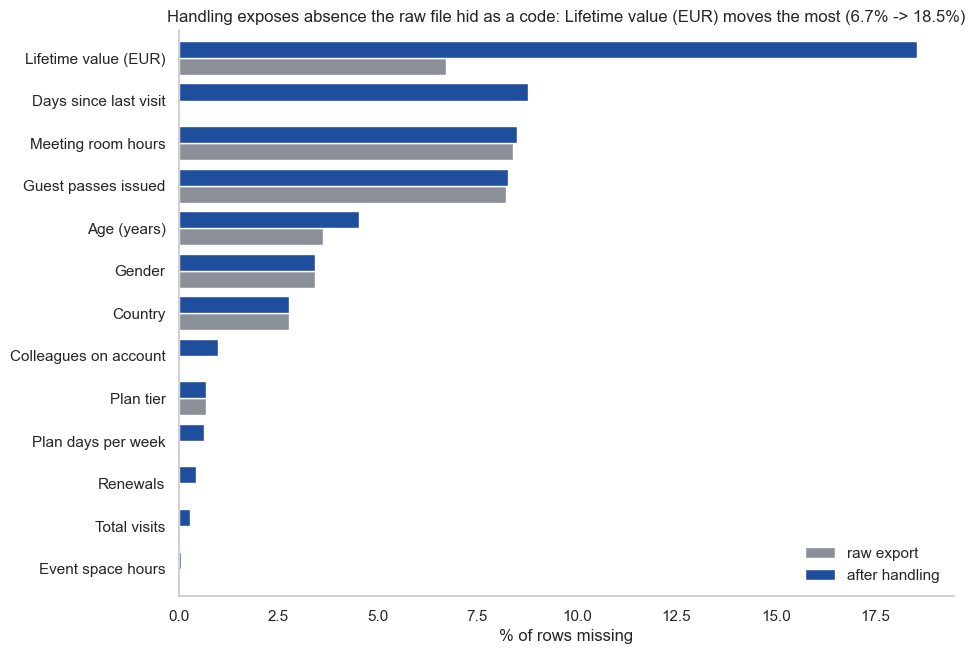

In [70]:
# The same comparison drawn as a chart, so the size of each block of absence is visible.
fig, ax = plt.subplots(figsize=(10, 0.45 * len(missing_compare) + 1.5))
missing_compare.plot.barh(ax=ax, color=[GRAY, BLUE], width=0.8)
ax.set_yticklabels([chart_label(c) for c in missing_compare.index])
ax.set(xlabel="% of rows missing", ylabel="",
       title=f"Handling exposes absence the raw file hid as a code: {chart_label(largest_gain)} "
             f"moves the most ({missing_compare.loc[largest_gain, 'raw export']:.1f}% -> "
             f"{missing_compare.loc[largest_gain, 'after handling']:.1f}%)")
ax.legend(title="", frameon=False, loc="lower right")
ax.grid(False)
sns.despine()
plt.show()

### Decisions taken in this section
Every rule is recorded as a flag column so its effect can be reviewed: placeholders and impossible values become
missing, category variants are mapped, dates are parsed in the proven order, the sentinel becomes a status, suspect
extremes are kept and flagged, and contradictions are flagged only. Nothing is filled in, nothing is trimmed, and
only the exact duplicates are removed.

So what: the frame that section 5 analyses is the same file with its documented errors turned into missing values
plus a flag, so every later number can be traced back to a rule written above.

# 5. Univariate analysis
We look at each metric variable with a summary table, a histogram and a box plot, and at each non-metric variable
with a frequency table. A log scale is used where a distribution has a long tail. Three variables are treated
separately because most members sit on an exact zero for them.

### Words used in this section
A **skew** figure says which side of a distribution the long tail is on: zero is symmetrical, a positive value means
a tail to the right. An **outlier** is a value that sits outside the ordinary range of its own column; it is not
automatically an error, and here it is flagged rather than removed. The **fence** rule we use calls a value an outlier
when it falls below `Q1 - 1.5*IQR` or above `Q3 + 1.5*IQR`, where Q1 and Q3 are the 25th and 75th percentiles and the
IQR is their difference, as defined in section 2. A column is **zero-inflated** when a large share of members have an
exact zero in it, because most people never used that service.

In [71]:
# Descriptive statistics of the metric variables after handling, with the 1st and 99th percentiles added.
analysis_data[metric_features].describe(percentiles=[0.01, 0.5, 0.99]).round(2).T

,count,mean,std,min,1%,50%,99%,max
age,14750.0,34.75,8.39,18.0,19.00,34.00,55.00,93.00
n_colleagues_on_account,15297.0,0.58,1.15,0.0,0.00,0.00,5.00,9.00
plan_days_per_week,15353.0,3.38,1.41,2.0,2.00,3.00,7.00,7.00
days_since_last_visit,14096.0,37.30,67.61,0.0,1.00,10.00,294.00,1212.00
total_visits,15408.0,110.78,183.03,0.0,1.00,35.00,693.93,6530.00
avg_weekly_visits,15450.0,1.78,1.94,0.0,0.04,1.42,5.32,47.40
entitled_visits_last_period,15450.0,27.51,13.48,0.0,2.65,26.09,60.87,78.27
actual_visits_last_period,15450.0,13.80,11.39,0.0,0.00,10.00,43.51,60.00
meeting_room_hours,14139.0,33.14,428.59,0.0,0.00,0.00,326.80,41220.00
event_space_hours,15442.0,5.12,26.03,0.0,0.00,0.00,127.44,602.80


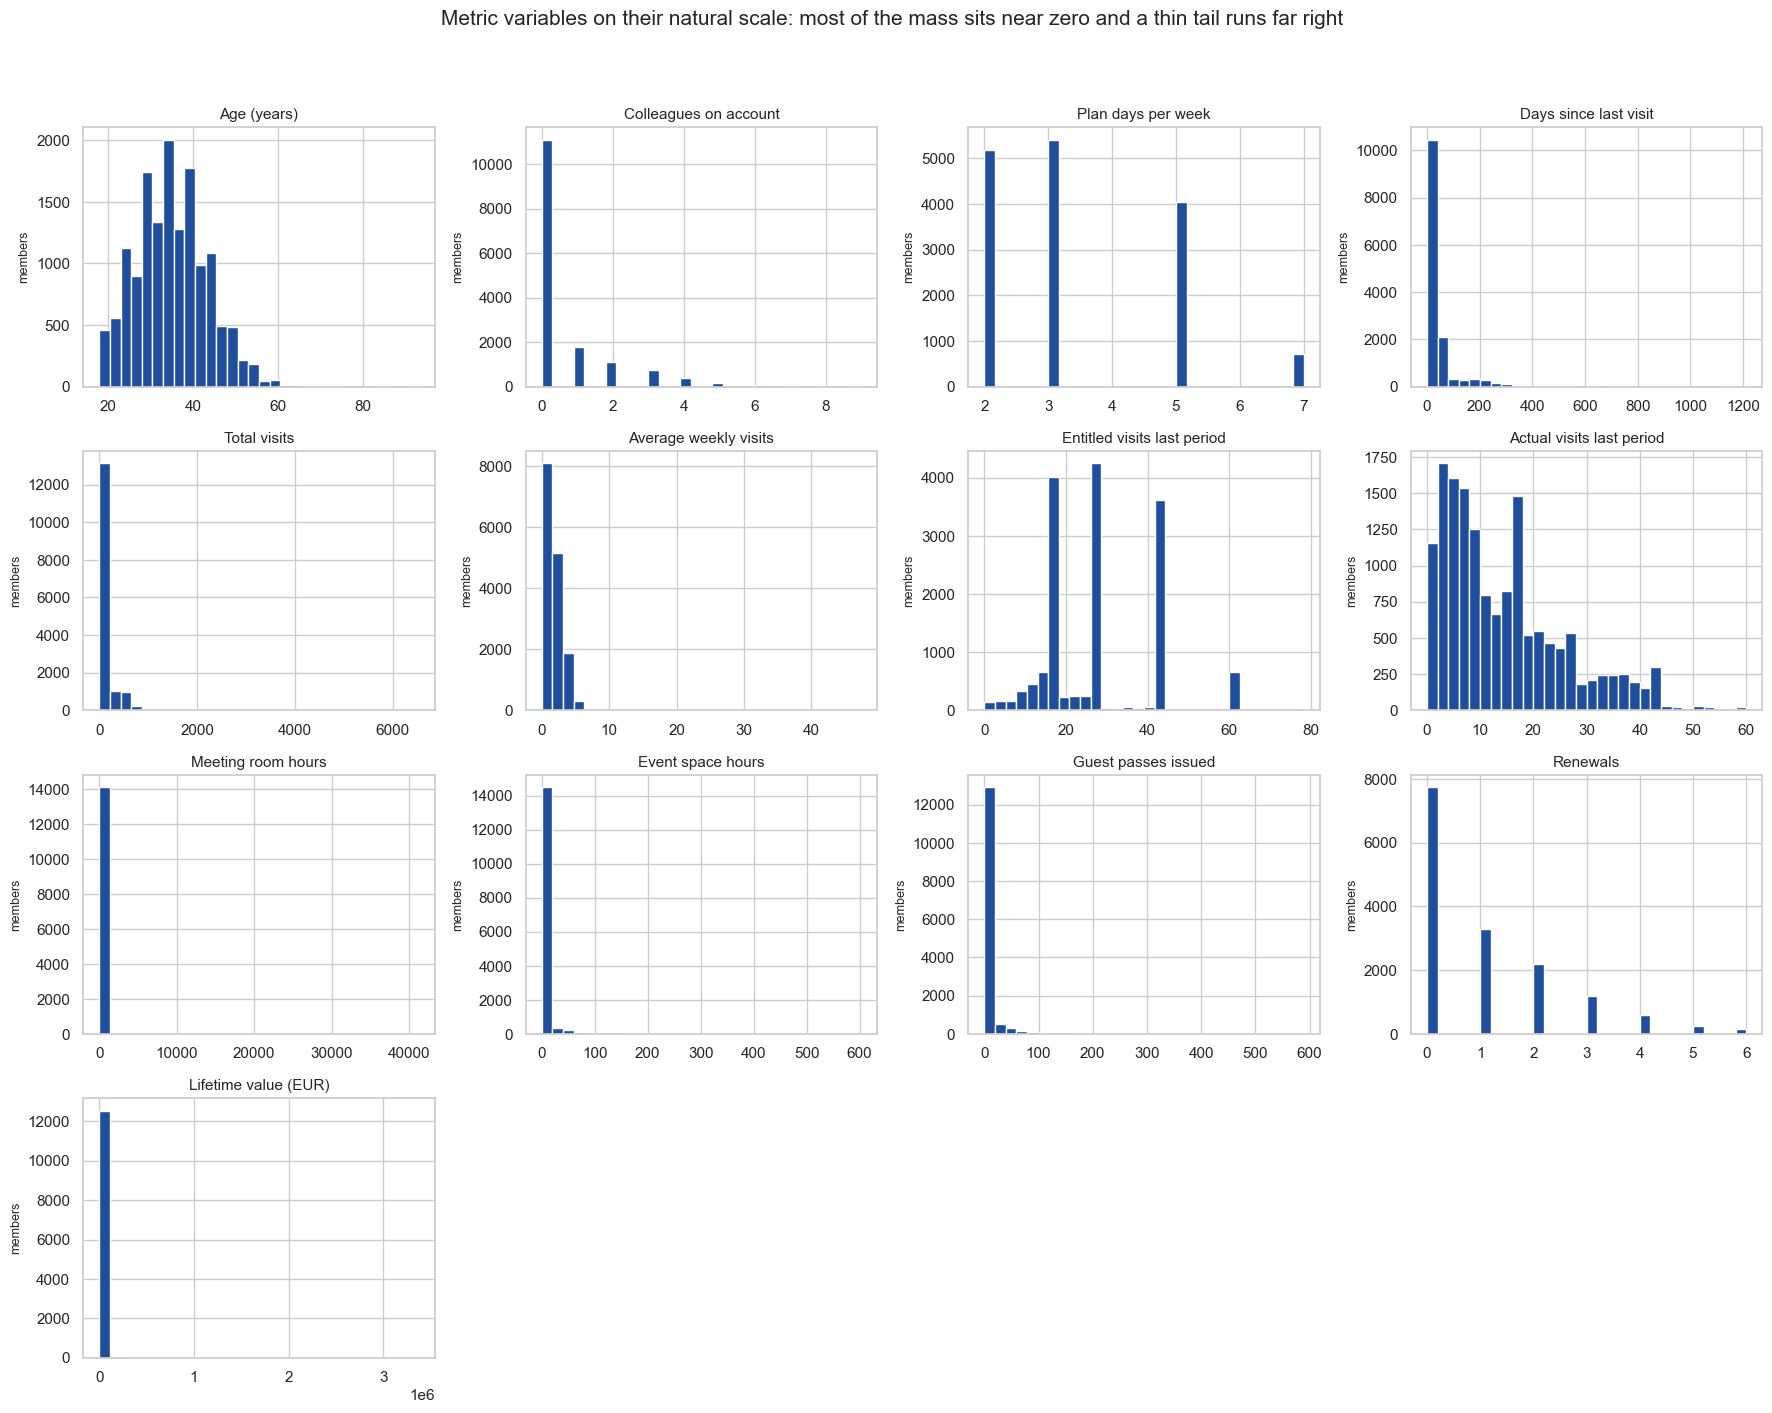

In [72]:
# Histogram grid of the metric variables on their natural scale.
columns_per_row = 4
n_rows = int(ceil(len(metric_features) / columns_per_row))
fig, axes = plt.subplots(n_rows, columns_per_row, figsize=(18, 3.6 * n_rows))
for ax, feature in zip(axes.flatten(), metric_features):
    ax.hist(analysis_data[feature].dropna(), bins=30, color=BLUE)
    ax.set_title(FEATURE_LABELS[feature], fontsize=11)
    ax.set_ylabel("members", fontsize=9)
for ax in axes.flatten()[len(metric_features):]:
    ax.set_visible(False)
fig.suptitle("Metric variables on their natural scale: most of the mass sits near zero and a thin tail runs far right",
             fontsize=15)
fig.tight_layout(rect=(0, 0, 1, 0.95))
plt.show()

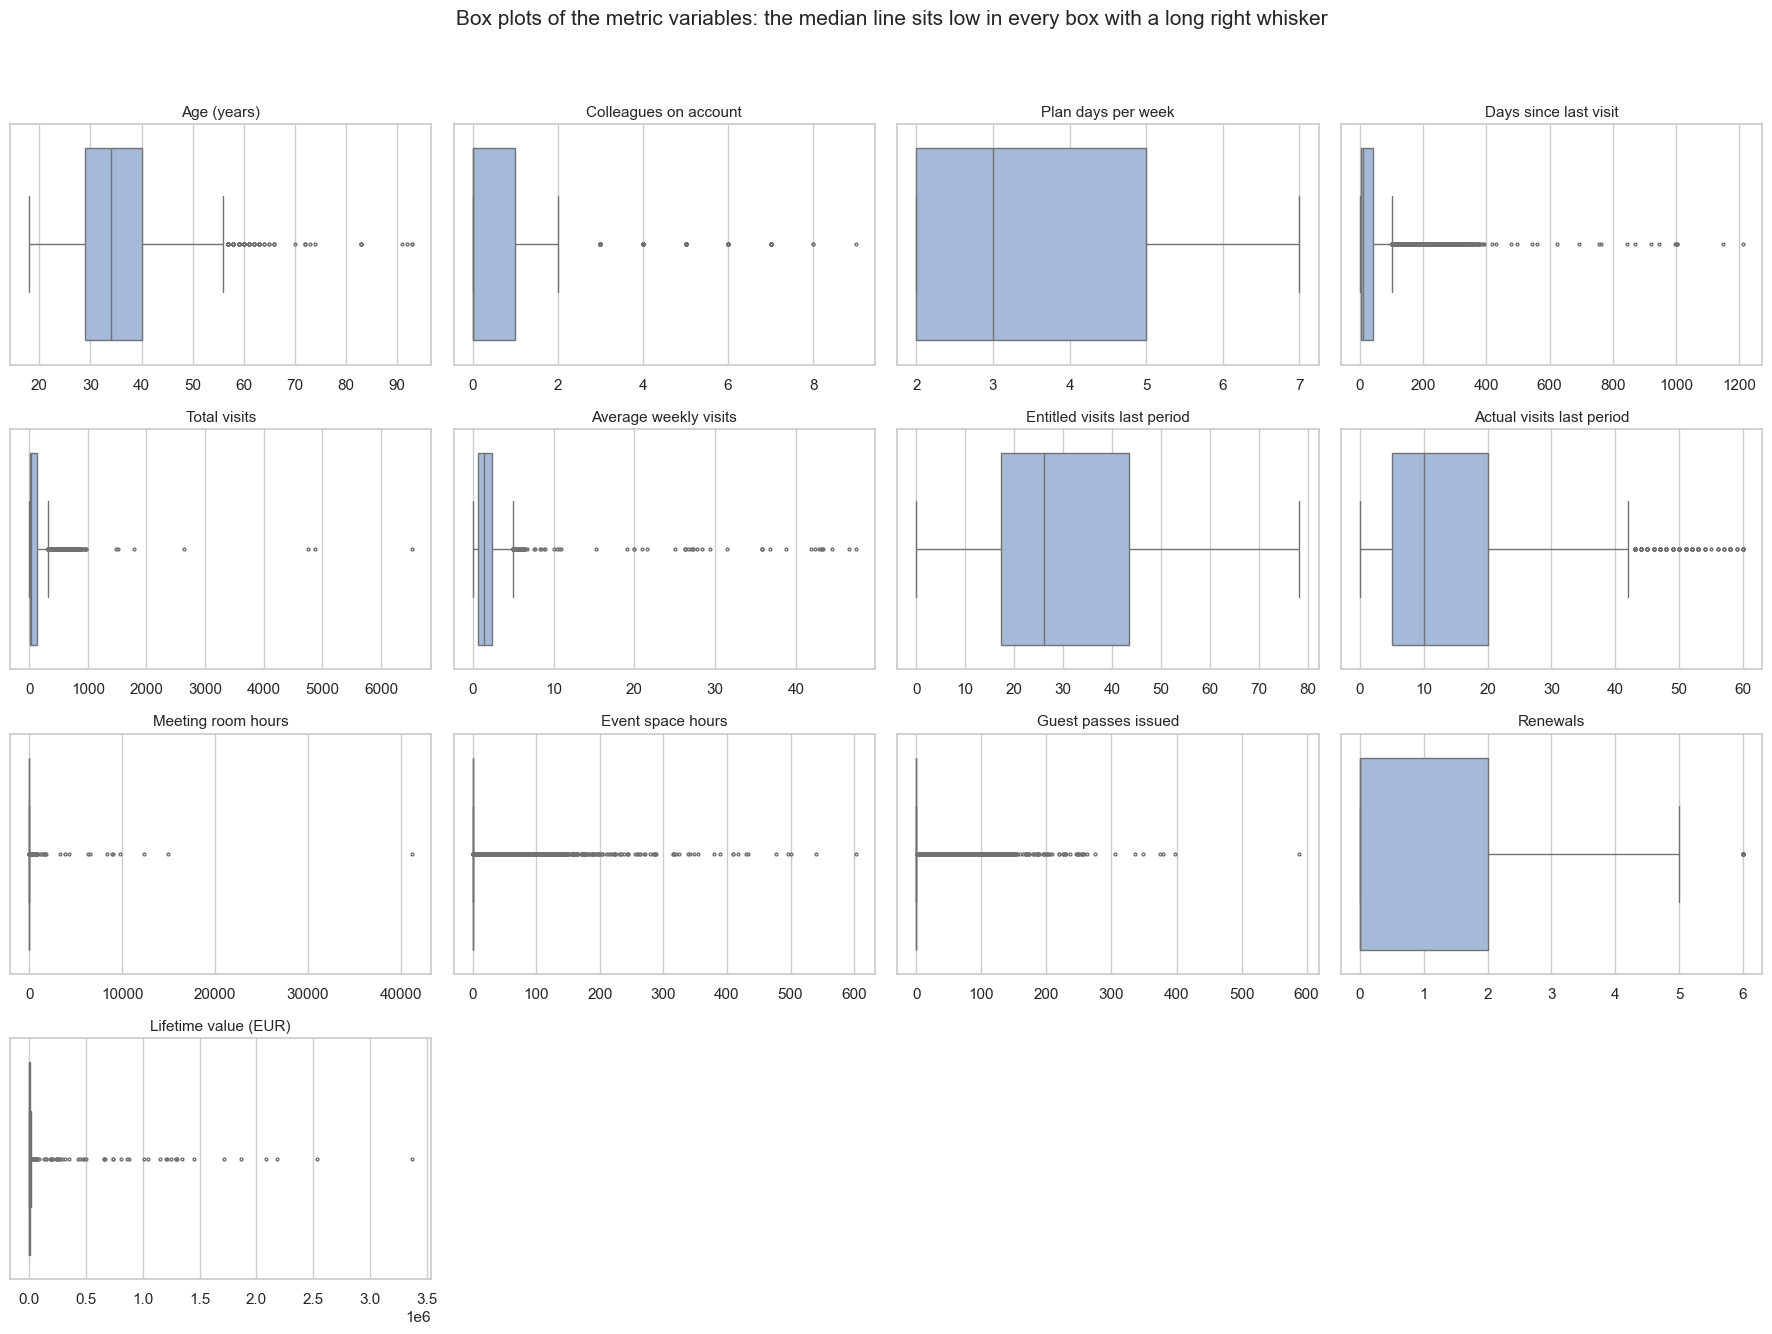

In [73]:
# Box plots of the same variables: the box makes the concentration near the median visible.
fig, axes = plt.subplots(n_rows, columns_per_row, figsize=(18, 3.4 * n_rows))
for ax, feature in zip(axes.flatten(), metric_features):
    sns.boxplot(x=analysis_data[feature], ax=ax, color=LIGHT_BLUE, fliersize=2)
    ax.set_title(FEATURE_LABELS[feature], fontsize=11)
    ax.set_xlabel("")
for ax in axes.flatten()[len(metric_features):]:
    ax.set_visible(False)
fig.suptitle("Box plots of the metric variables: the median line sits low in every box with a long right whisker",
             fontsize=15)
fig.tight_layout(rect=(0, 0, 1, 0.95))
plt.show()

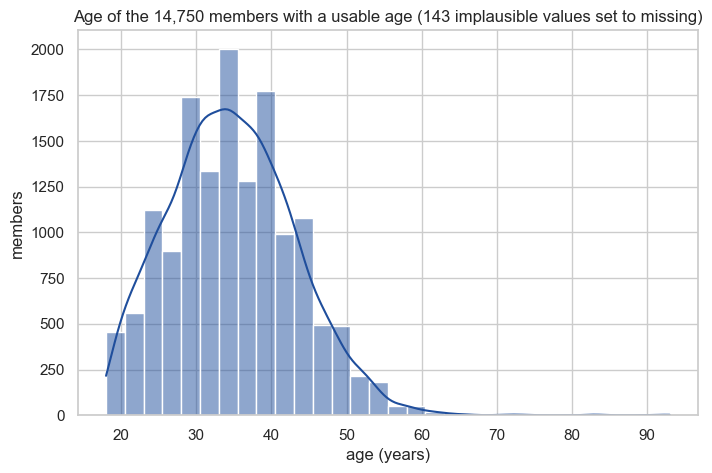

median age = 34 | interquartile range 29-40 | skew 0.44


In [74]:
# Age, the one variable whose shape is roughly symmetric, with its unusable values already removed.
fig, ax = plt.subplots(figsize=(8, 5))
sns.histplot(analysis_data["age"], bins=30, kde=True, color=BLUE, ax=ax)
ax.set(title=f"Age of the {int(analysis_data['age'].notna().sum()):,} members with a usable age "
            f"({int(analysis_data['flag_age_invalid'].sum())} implausible values set to missing)",
       xlabel="age (years)", ylabel="members")
plt.show()
print(f"median age = {analysis_data['age'].median():.0f} | interquartile range "
      f"{analysis_data['age'].quantile(0.25):.0f}-{analysis_data['age'].quantile(0.75):.0f} | "
      f"skew {analysis_data['age'].skew():.2f}")

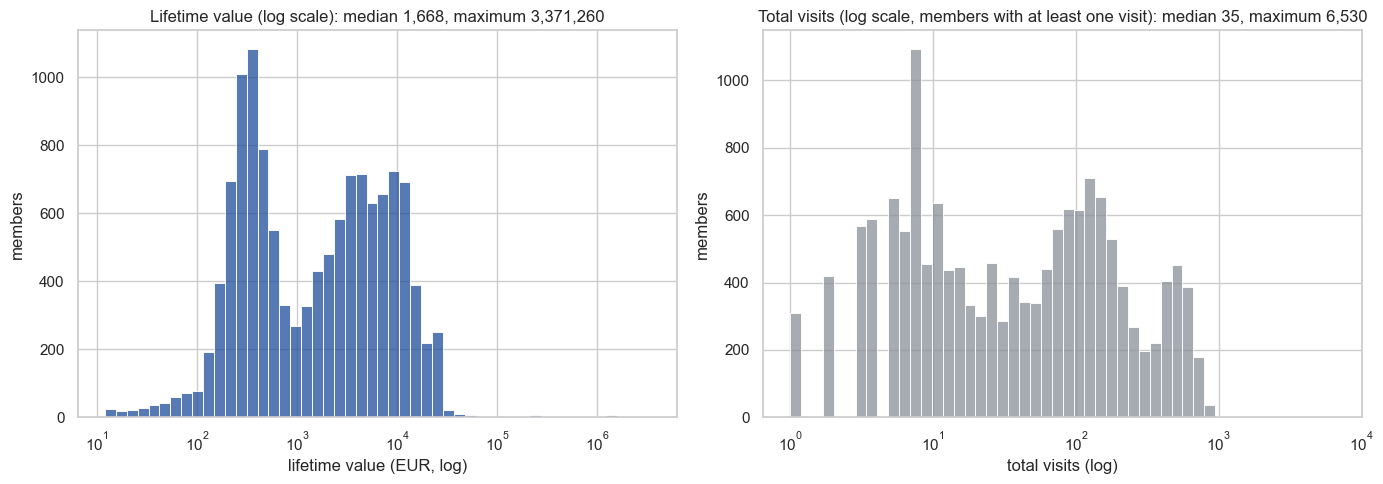

skew on the natural scale: lifetime_value 28.8, total_visits 6.8
The natural scale is what ACDC reads in a report; the log scale is what shows that the bulk of the members
sit in a narrow band and only a thin tail runs far to the right.


In [75]:
# The heavy-tailed variables on a log scale, where the shape of the bulk can still be seen.
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(analysis_data["lifetime_value"].dropna(), bins=50, log_scale=True, color=BLUE, ax=axes[0])
axes[0].set(title=f"Lifetime value (log scale): median {analysis_data['lifetime_value'].median():,.0f}, "
                  f"maximum {analysis_data['lifetime_value'].max():,.0f}",
            xlabel="lifetime value (EUR, log)", ylabel="members")
visit_users = analysis_data.loc[analysis_data["total_visits"] > 0, "total_visits"]
sns.histplot(visit_users, bins=50, log_scale=True, color=GRAY, ax=axes[1])
axes[1].set(title=f"Total visits (log scale, members with at least one visit): median {visit_users.median():.0f}, "
                  f"maximum {visit_users.max():,.0f}",
            xlabel="total visits (log)", ylabel="members")
fig.tight_layout()
plt.show()
print(f"skew on the natural scale: lifetime_value {analysis_data['lifetime_value'].skew():.1f}, "
      f"total_visits {analysis_data['total_visits'].skew():.1f}")
print("The natural scale is what ACDC reads in a report; the log scale is what shows that the bulk of the members")
print("sit in a narrow band and only a thin tail runs far to the right.")

### Spread and fences on the variables that are spread
The fence rule is applied only to the metric variables whose values are spread across their range. The three
zero-inflated usage columns are described by their own table instead, because a fence there would answer "did you use
the service at all" rather than "did you use it unusually much".

In [76]:
# The three zero-inflated usage columns: most members have never used the service.
zero_inflated_features = ["meeting_room_hours", "event_space_hours", "guest_passes_issued"]
usage_rows = []
for column in zero_inflated_features:
    users = analysis_data.loc[analysis_data[column] > 0, column]
    usage_rows.append({"feature": FEATURE_LABELS[column],
                       "members": int(analysis_data[column].notna().sum()),
                       "pct_zero": round(float((analysis_data[column] == 0).mean() * 100), 2),
                       "pct_used": round(float((analysis_data[column] > 0).mean() * 100), 2),
                       "median_among_users": round(float(users.median()), 2) if len(users) else None,
                       "p90_among_users": round(float(users.quantile(0.9)), 2) if len(users) else None,
                       "max_among_users": round(float(analysis_data[column].max()), 1)})
usage_profile = pd.DataFrame(usage_rows).set_index("feature")
print(usage_profile.to_string())
print("\nBecause most members sit on an exact zero, the middle half of these columns is zero, so a fence would call")
print("every single user an outlier. The honest description is in two parts: whether the member used the service at")
print("all, and how much the users used it. Those are the two numbers in the table, and they are what a later")
print("grouping should see.")

                     members  pct_zero  pct_used  median_among_users  p90_among_users  max_among_users
feature                                                                                               
Meeting room hours     14139     59.82     31.70                32.5           181.74          41220.0
Event space hours      15442     88.56     11.39                23.2           115.48            602.8
Guest passes issued    14174     75.71     16.03                20.0            88.00            589.0

Because most members sit on an exact zero, the middle half of these columns is zero, so a fence would call
every single user an outlier. The honest description is in two parts: whether the member used the service at
all, and how much the users used it. Those are the two numbers in the table, and they are what a later
grouping should see.


In [77]:
# Fences for the variables that are genuinely spread; the zero-inflated trio is left to the table above.
fence_features = [c for c in metric_features if c not in zero_inflated_features]
fence_rows = []
for feature in fence_features:
    series = analysis_data[feature].dropna()
    q1, q3 = series.quantile(0.25), series.quantile(0.75)
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    below, above = (analysis_data[feature] < lower).fillna(False), (analysis_data[feature] > upper).fillna(False)
    analysis_data[f"flag_iqr_low_{feature}"] = below
    analysis_data[f"flag_iqr_high_{feature}"] = above
    fence_rows.append({"feature": feature, "Q1": round(q1, 2), "median": round(series.median(), 2),
                       "Q3": round(q3, 2), "IQR": round(iqr, 2), "lower_fence": round(lower, 2),
                       "upper_fence": round(upper, 2), "n_below": int(below.sum()), "n_above": int(above.sum()),
                       "pct_outside": round(float((below | above).sum()) / len(series) * 100, 2)})
fences = pd.DataFrame(fence_rows).set_index("feature")
print(fences.sort_values("pct_outside", ascending=False).to_string())

                                 Q1   median       Q3      IQR  lower_fence  upper_fence  n_below  n_above  pct_outside
feature                                                                                                                
total_visits                   8.00    35.00   132.00   124.00      -178.00       318.00        0     1730        11.23
days_since_last_visit          3.00    10.00    42.00    39.00       -55.50       100.50        0     1336         9.48
n_colleagues_on_account        0.00     0.00     1.00     1.00        -1.50         2.50        0     1323         8.65
lifetime_value               349.78  1667.76  6094.39  5744.61     -8267.13     14711.30        0      784         6.23
actual_visits_last_period      5.00    10.00    20.00    15.00       -17.50        42.50        0      380         2.46
avg_weekly_visits              0.71     1.42     2.41     1.70        -1.84         4.96        0      312         2.02
n_renewals                     0.00     

In [78]:
# How many members each fence rule flags, and the count that section 10 reuses.
fence_flag_columns = [f"flag_iqr_low_{f}" for f in fence_features] + [f"flag_iqr_high_{f}" for f in fence_features]
analysis_data["n_iqr_fences"] = analysis_data[fence_flag_columns].sum(axis=1)
n_no_fence = int((analysis_data["n_iqr_fences"] == 0).sum())
print(f"{len(fence_features)} variables enter the fence rule, {len(fence_flag_columns)} fence flags written")
print(f"members violating no fence at all: {n_no_fence:,} of {len(analysis_data):,} ({n_no_fence / len(analysis_data):.1%})")
print(f"most outlying variable: {fences['pct_outside'].idxmax()} ({fences['pct_outside'].max():.1f}% outside)")
print("The fence count summarises how spread a column is, so it is kept out of the behavioural ranking in section 12")
print("and used only as the anomaly diagnostic in section 10.")

10 variables enter the fence rule, 20 fence flags written
members violating no fence at all: 10,771 of 15,450 (69.7%)
most outlying variable: total_visits (11.2% outside)
The fence count summarises how spread a column is, so it is kept out of the behavioural ranking in section 12
and used only as the anomaly diagnostic in section 10.


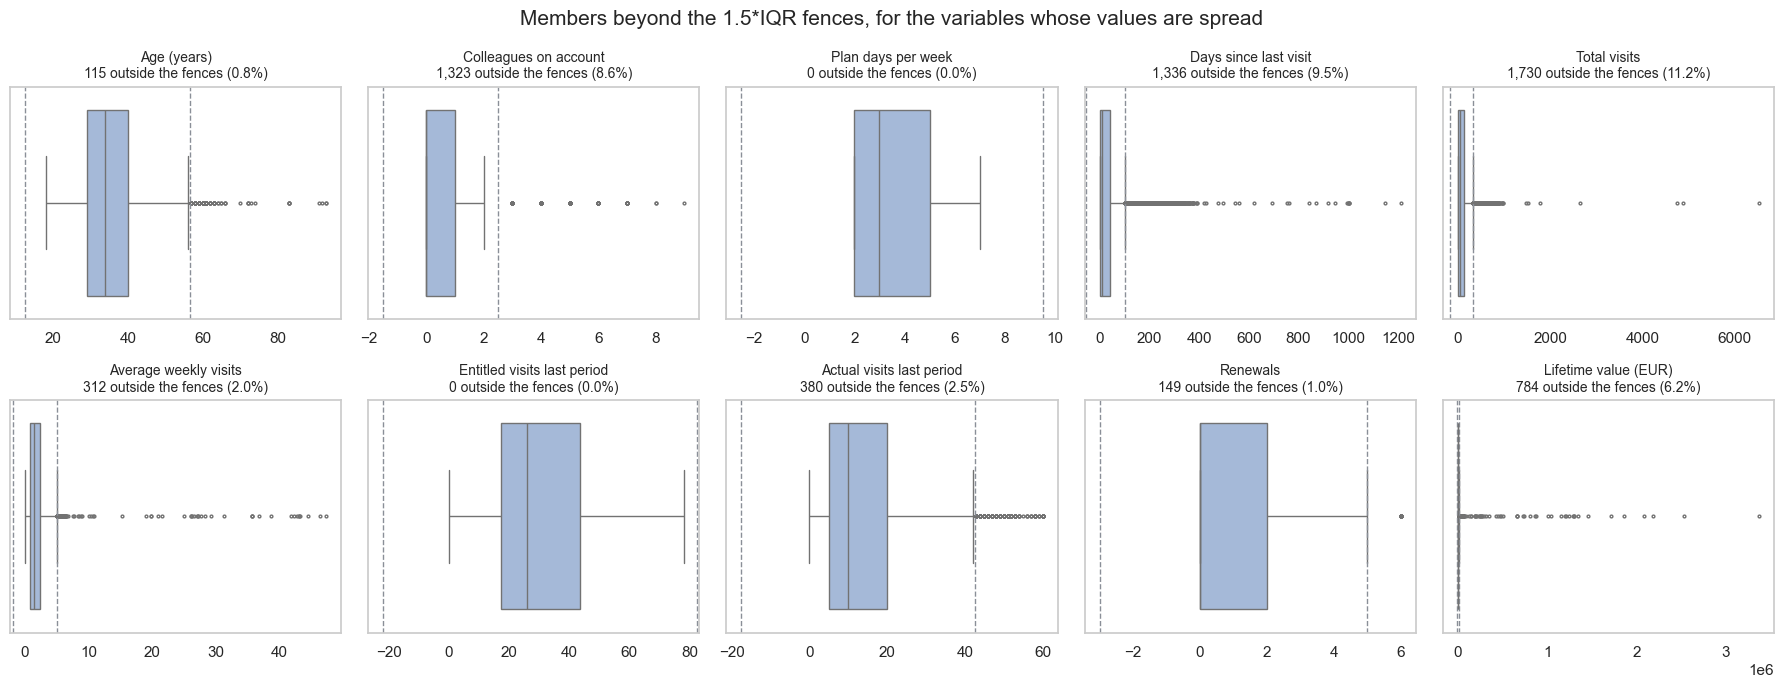

In [79]:
# Box plots with the fences drawn as dashed lines, so the size of the outside group is visible per variable.
fig, axes = plt.subplots(2, 5, figsize=(18, 7))
for ax, feature in zip(axes.flatten(), fence_features):
    series = analysis_data[feature].dropna()
    sns.boxplot(x=series, ax=ax, color=LIGHT_BLUE, whis=1.5, fliersize=2)
    ax.axvline(fences.loc[feature, "lower_fence"], color=GRAY, linestyle="--", linewidth=1)
    ax.axvline(fences.loc[feature, "upper_fence"], color=GRAY, linestyle="--", linewidth=1)
    n_out = int(fences.loc[feature, "n_below"] + fences.loc[feature, "n_above"])
    ax.set_title(f"{FEATURE_LABELS[feature]}\n{n_out:,} outside the fences ({n_out / len(series):.1%})", fontsize=10)
    ax.set_xlabel("")
    ax.grid(False)
for ax in axes.flatten()[len(fence_features):]:
    ax.set_visible(False)
fig.suptitle("Members beyond the 1.5*IQR fences, for the variables whose values are spread", fontsize=15)
fig.tight_layout()
plt.show()

### Non-metric variables
We show the frequency of each category, ordered from most to least common. The add-on flags are included because
using or not using a service is itself a category.

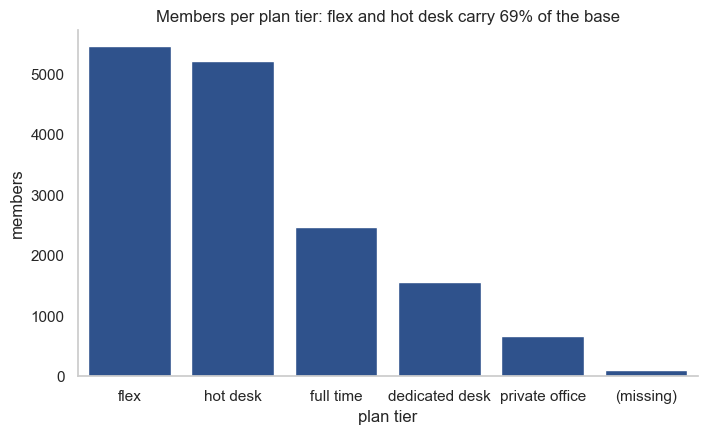

In [80]:
# Which plan do members actually buy? One panel, ordered by frequency, with the missing level kept visible.
tier_series = label_missing(analysis_data["plan_tier"])
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.countplot(x=tier_series, color=BLUE, order=tier_series.value_counts().index, ax=ax)
ax.set(title=f"Members per plan tier: {tier_series.value_counts().index[0].replace('_', ' ')} and "
             f"{tier_series.value_counts().index[1].replace('_', ' ')} carry "
             f"{(tier_series.value_counts().head(2).sum() / len(analysis_data) * 100):.0f}% of the base",
       xlabel="plan tier", ylabel="members")
ax.set_xticks(ax.get_xticks())
ax.set_xticklabels([t.get_text().replace("_", " ") for t in ax.get_xticklabels()])
ax.grid(False)
sns.despine()
plt.show()

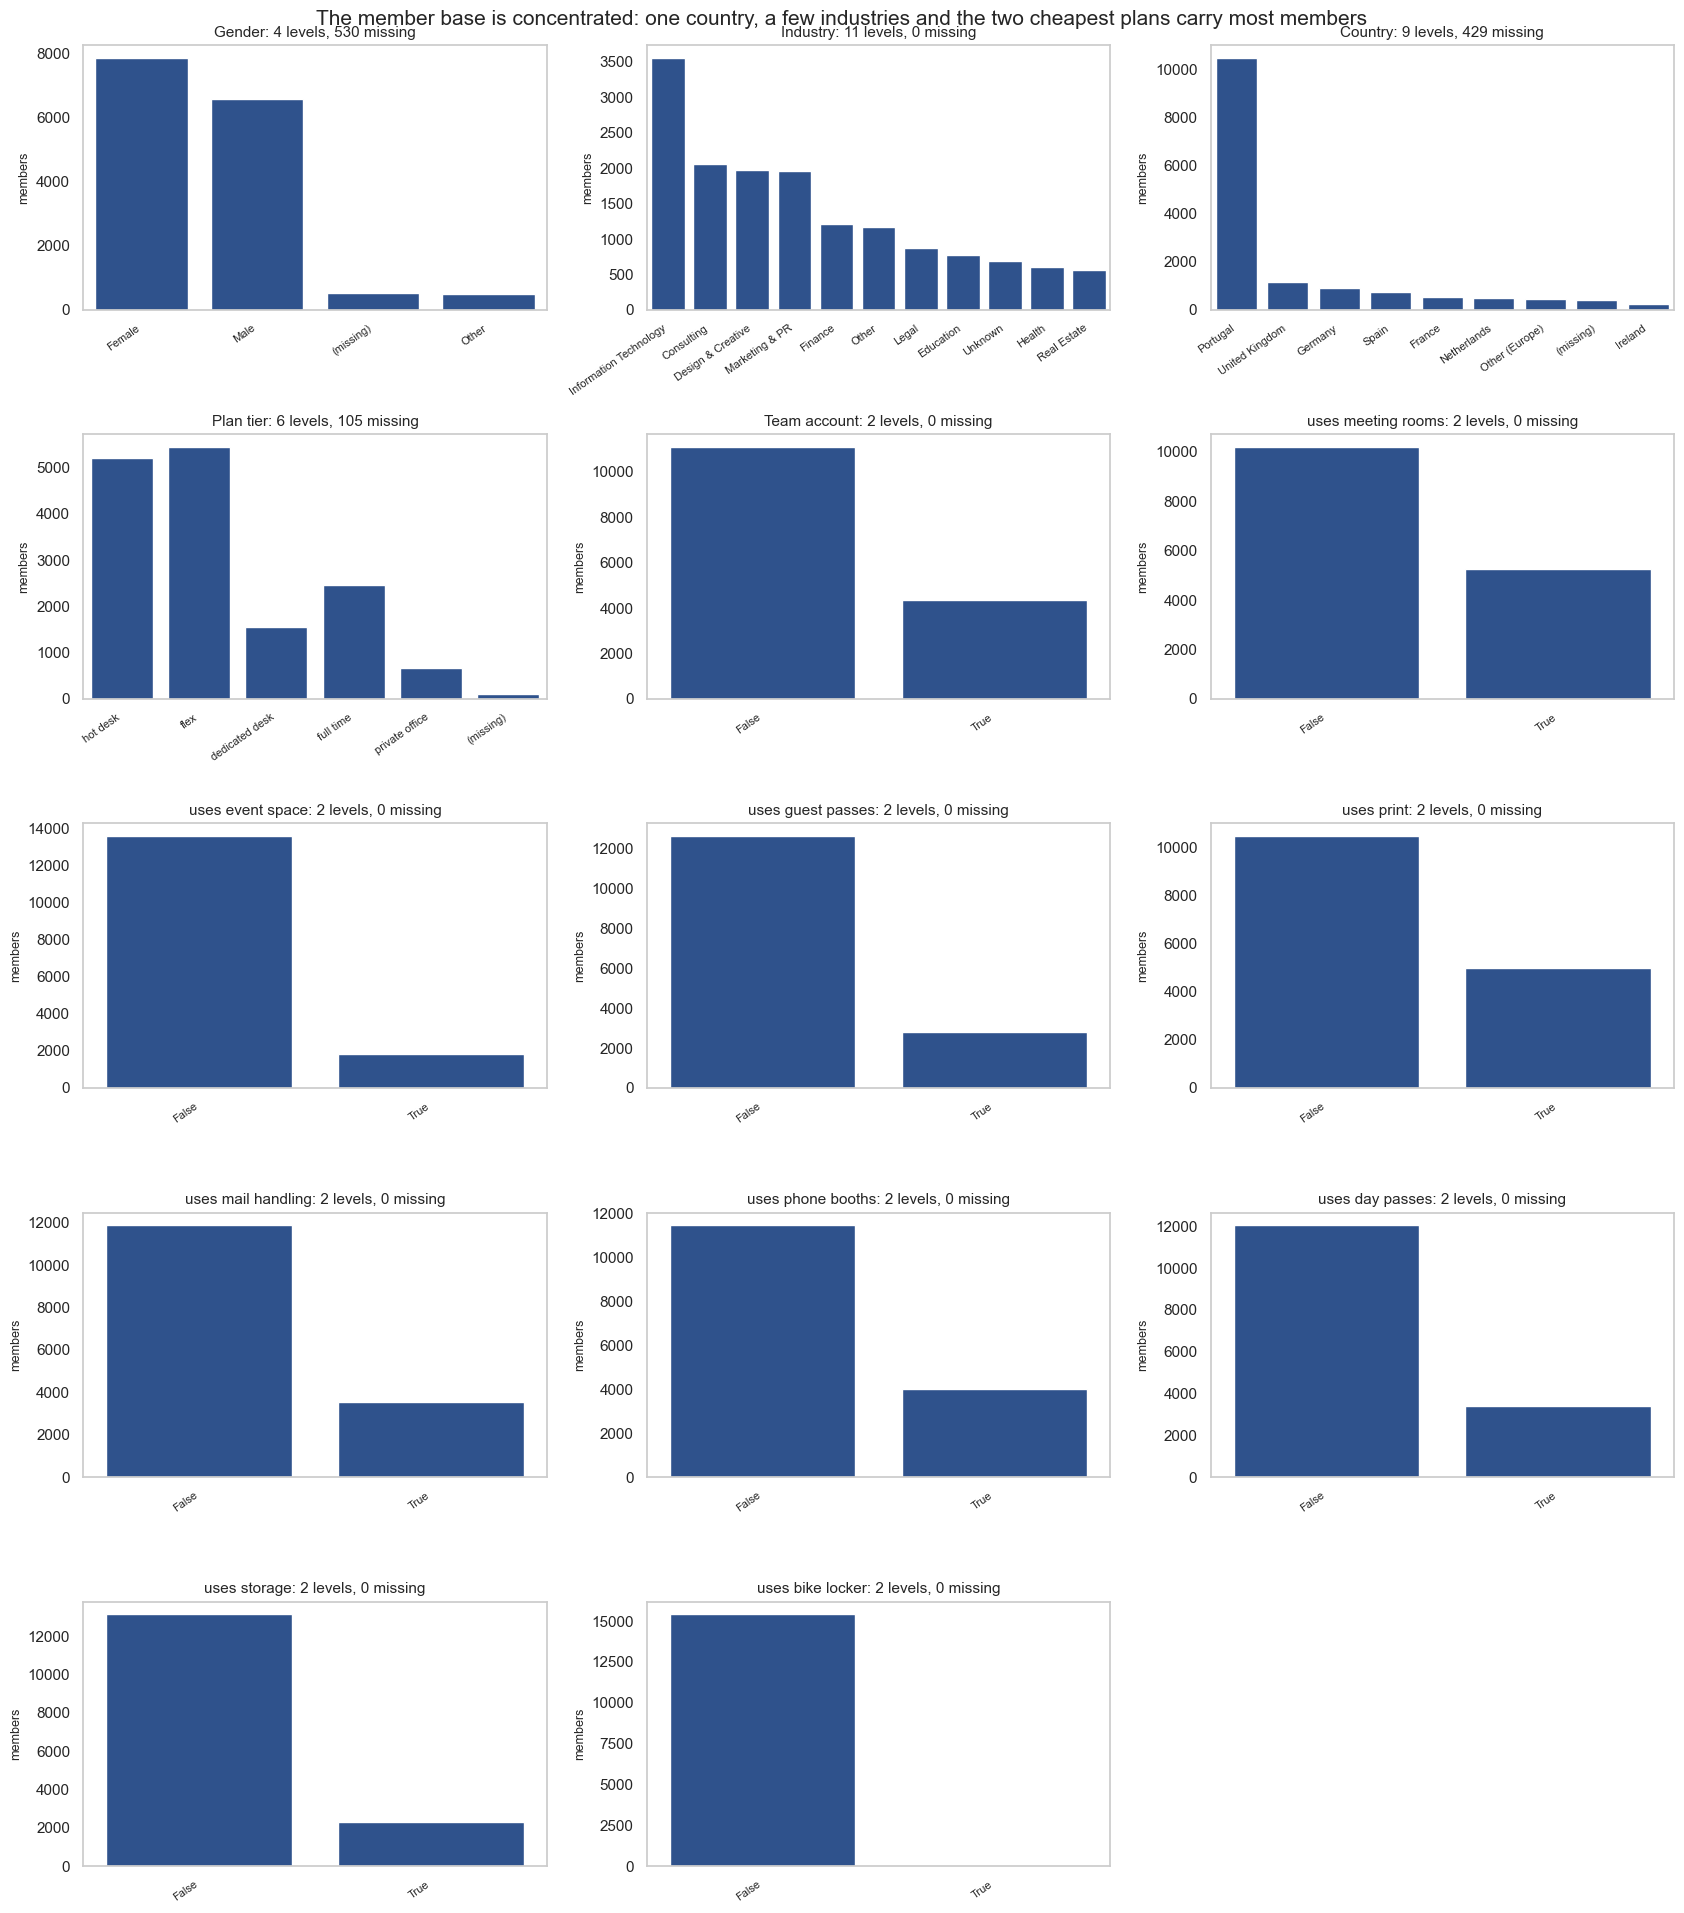

In [81]:
# Count plot for every non-metric variable, each panel titled with its level count and its missing count.
count_columns = categorical_features + binary_features
n_count_rows = int(ceil(len(count_columns) / 3))
fig, axes = plt.subplots(n_count_rows, 3, figsize=(17, 3.9 * n_count_rows))
for ax, column in zip(axes.flatten(), count_columns):
    series = label_missing(analysis_data[column])
    order = [o for o in tier_order + ["(missing)"] if o in set(series)] if column == "plan_tier" else series.value_counts().index
    sns.countplot(x=series, color=BLUE, order=order, ax=ax)
    ax.set_title(f"{FEATURE_LABELS.get(column, column.replace('_', ' '))}: {series.nunique()} levels, "
                 f"{int(analysis_data[column].isna().sum()):,} missing", fontsize=11)
    ax.set_xlabel("")
    ax.set_ylabel("members", fontsize=9)
    ax.set_xticks(ax.get_xticks())
    ax.set_xticklabels([t.get_text().replace("_", " ") for t in ax.get_xticklabels()], rotation=35, ha="right", fontsize=8)
    ax.grid(False)
for ax in axes.flatten()[len(count_columns):]:
    ax.set_visible(False)
fig.suptitle("The member base is concentrated: one country, a few industries and the two cheapest plans carry most members",
             fontsize=15)
fig.tight_layout()
plt.show()

In [82]:
# Class balance of every non-metric variable: a variable that is almost one value carries no usable contrast.
balance_columns = categorical_features + binary_features + ["status"]
balance_rows = []
for column in balance_columns:
    counts = analysis_data[column].value_counts(normalize=True)
    balance_rows.append({"variable": column, "n_levels": int(analysis_data[column].nunique()),
                         "majority_level": str(counts.index[0]), "majority_pct": round(float(counts.iloc[0] * 100), 1),
                         "minority_level": str(counts.index[-1]), "minority_pct": round(float(counts.iloc[-1] * 100), 1)})
balance = pd.DataFrame(balance_rows).set_index("variable").sort_values("majority_pct")
most_imbalanced = str(balance["majority_pct"].idxmax())
print(balance.to_string())

                    n_levels          majority_level  majority_pct  minority_level  minority_pct
variable                                                                                        
industry                  11  Information Technology          23.0     Real Estate           3.6
plan_tier                  5                    flex          35.5  private_office           4.3
gender                     3                  Female          52.7           Other           3.3
uses_meeting_rooms         2                   False          66.0            True          34.0
uses_print                 2                   False          67.7            True          32.3
country                    8                Portugal          69.9         Ireland           1.6
is_team_account            2                   False          71.8            True          28.2
uses_phone_booths          2                   False          74.2            True          25.8
status                     2  

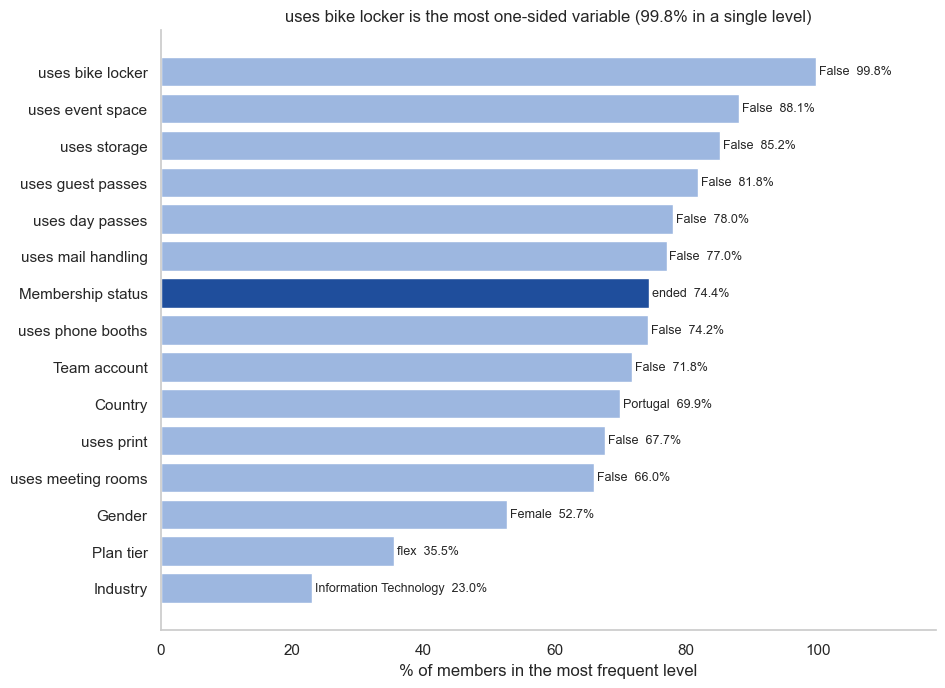

In [83]:
# The same table as a chart, so the one-sided variables are visible at a glance.
fig, ax = plt.subplots(figsize=(10, 0.42 * len(balance) + 1.5))
bars = ax.barh(range(len(balance)), balance["majority_pct"], color=[BLUE if c == "status" else LIGHT_BLUE for c in balance.index])
ax.set_yticks(range(len(balance)), [chart_label(c) for c in balance.index])
ax.bar_label(bars, labels=[f"{level}  {v:.1f}%" for level, v in zip(balance["majority_level"], balance["majority_pct"])],
             fontsize=9, padding=2)
ax.set(xlabel="% of members in the most frequent level", xlim=(0, 118),
       title=f"{chart_label(most_imbalanced)} is the most one-sided variable "
             f"({balance['majority_pct'].max():.1f}% in a single level)")
ax.grid(False)
sns.despine()
plt.show()

In [84]:
# The univariate findings, printed from the values computed above rather than typed from memory.
ltv_now = analysis_data["lifetime_value"]
addon_flags = [c for c in binary_features if c != "is_team_account"]
takeup = analysis_data[addon_flags].mean() * 100
print(f"Insight 1 - median lifetime value is {ltv_now.median():,.0f} EUR against a mean of {ltv_now.mean():,.0f}: "
      f"a small number of members dominate revenue.")
print(f"Insight 2 - median total visits is {analysis_data['total_visits'].median():.0f} against a maximum of "
      f"{analysis_data['total_visits'].max():,.0f}, and {int((analysis_data['total_visits'] == 0).sum()):,} members have "
      "no recorded visit at all.")
print(f"Insight 3 - {top_country} holds {n_portugal / len(analysis_data):.1%} of members; the two cheapest plans hold "
      f"{(analysis_data['plan_tier'].isin(['hot_desk', 'flex']).sum() / len(analysis_data)):.1%} of the base.")
print(f"Insight 4 - {pct_ended:.1f}% of members have ended inside the {window_years:.0f}-year window "
      f"({pct_active:.1f}% active): a cumulative share, not an annual churn rate.")
print(f"Insight 5 - add-on take-up ranges from {takeup.max():.1f}% ({takeup.idxmax()}) to "
      f"{takeup.min():.1f}% ({takeup.idxmin()}).")

Insight 1 - median lifetime value is 1,668 EUR against a mean of 7,340: a small number of members dominate revenue.
Insight 2 - median total visits is 35 against a maximum of 6,530, and 109 members have no recorded visit at all.
Insight 3 - Portugal holds 68.0% of members; the two cheapest plans hold 69.0% of the base.
Insight 4 - 74.4% of members have ended inside the 3-year window (25.6% active): a cumulative share, not an annual churn rate.
Insight 5 - add-on take-up ranges from 34.0% (uses_meeting_rooms) to 0.2% (uses_bike_locker).


So what: the base is concentrated and every metric column has a long right tail, so a grouping built on raw values
and raw categories would mostly restate the plan price list and the handful of members at the top.

# 6. Relationships
We compare value with usage, plan with membership status, and recompute the links inside relevant groups instead of
reading only the pooled figure. A pooled number describes a mixture of populations; it does not describe any of them.

### Pearson and Spearman, in plain words
**Pearson** r measures how closely two columns follow one straight line, and it is pulled about by extreme values.
**Spearman** rho first replaces each column by its rank, then measures the straight line between the ranks: it answers
"when one value grows, does the other usually grow too?" and it ignores how far apart the values are. For a column
with a long tail, Spearman is the honest one to read.

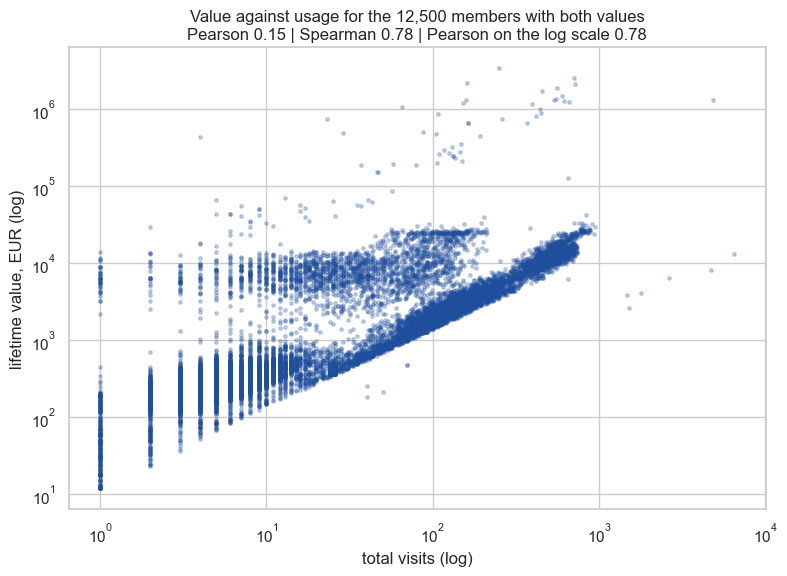

members with both a visit count and a value: 12,500 of 15,450


In [85]:
# Value against usage on log-log axes: one scatter, no density trick, and the three readings printed below.
xy = analysis_data[["total_visits", "lifetime_value"]].dropna()
xy = xy[(xy["total_visits"] > 0) & (xy["lifetime_value"] > 0)]
pearson_now = float(xy.corr().iloc[0, 1])
spearman_now = float(xy.corr(method="spearman").iloc[0, 1])
log_pearson_now = float(np.log(xy).corr().iloc[0, 1])
fig, ax = plt.subplots(figsize=(9, 6))
ax.scatter(xy["total_visits"], xy["lifetime_value"], s=6, alpha=0.25, color=BLUE)
ax.set(xscale="log", yscale="log", xlabel="total visits (log)", ylabel="lifetime value, EUR (log)",
       title=f"Value against usage for the {len(xy):,} members with both values\n"
             f"Pearson {pearson_now:.2f} | Spearman {spearman_now:.2f} | Pearson on the log scale {log_pearson_now:.2f}")
plt.show()
print(f"members with both a visit count and a value: {len(xy):,} of {len(analysis_data):,}")

In [86]:
# Does value really rise with usage? Cut the members into ten groups by visit count and look inside each group.
usage_frame = analysis_data.loc[xy.index, ["total_visits", "lifetime_value", "entitled_visits_last_period"]]
visit_deciles = pd.qcut(usage_frame["total_visits"], 10, labels=False, duplicates="drop") + 1
by_decile = usage_frame.groupby(visit_deciles).agg(members=("lifetime_value", "size"),
                                                   visits_from=("total_visits", "min"),
                                                   visits_to=("total_visits", "max"),
                                                   median_value=("lifetime_value", "median"),
                                                   median_entitlement=("entitled_visits_last_period", "median"))
print(by_decile.round(1).to_string())
print(f"\nthe median value runs from {by_decile['median_value'].iloc[0]:,.0f} EUR in the quietest group to "
      f"{by_decile['median_value'].iloc[-1]:,.0f} EUR in the busiest")
print(f"and the plan entitlement from {by_decile['median_entitlement'].iloc[0]:.0f} to "
      f"{by_decile['median_entitlement'].iloc[-1]:.0f} visits, so the busiest members are also the ones on the "
      "dearer plans")
print("Reading: value rises with usage, but not in proportion. A member who comes ten times more often does not")
print("pay ten times more, which is why one straight-line figure understates the link on the raw scale.")

              members  visits_from  visits_to  median_value  median_entitlement
total_visits                                                                   
1                1611          1.0        4.0         209.3                13.4
2                1018          5.0        6.0         281.7                17.4
3                1240          7.0        9.0         324.9                17.4
4                1151         10.0       15.0         456.3                26.1
5                1251         16.0       34.0         797.2                26.1
6                1251         35.0       69.0        1365.7                26.1
7                1248         70.0      108.0        2039.8                26.1
8                1239        109.0      162.0        3045.8                26.1
9                1247        163.0      365.0        4477.8                26.1
10               1244        366.0     6530.0       12316.2                43.5

the median value runs from 209 EUR in t

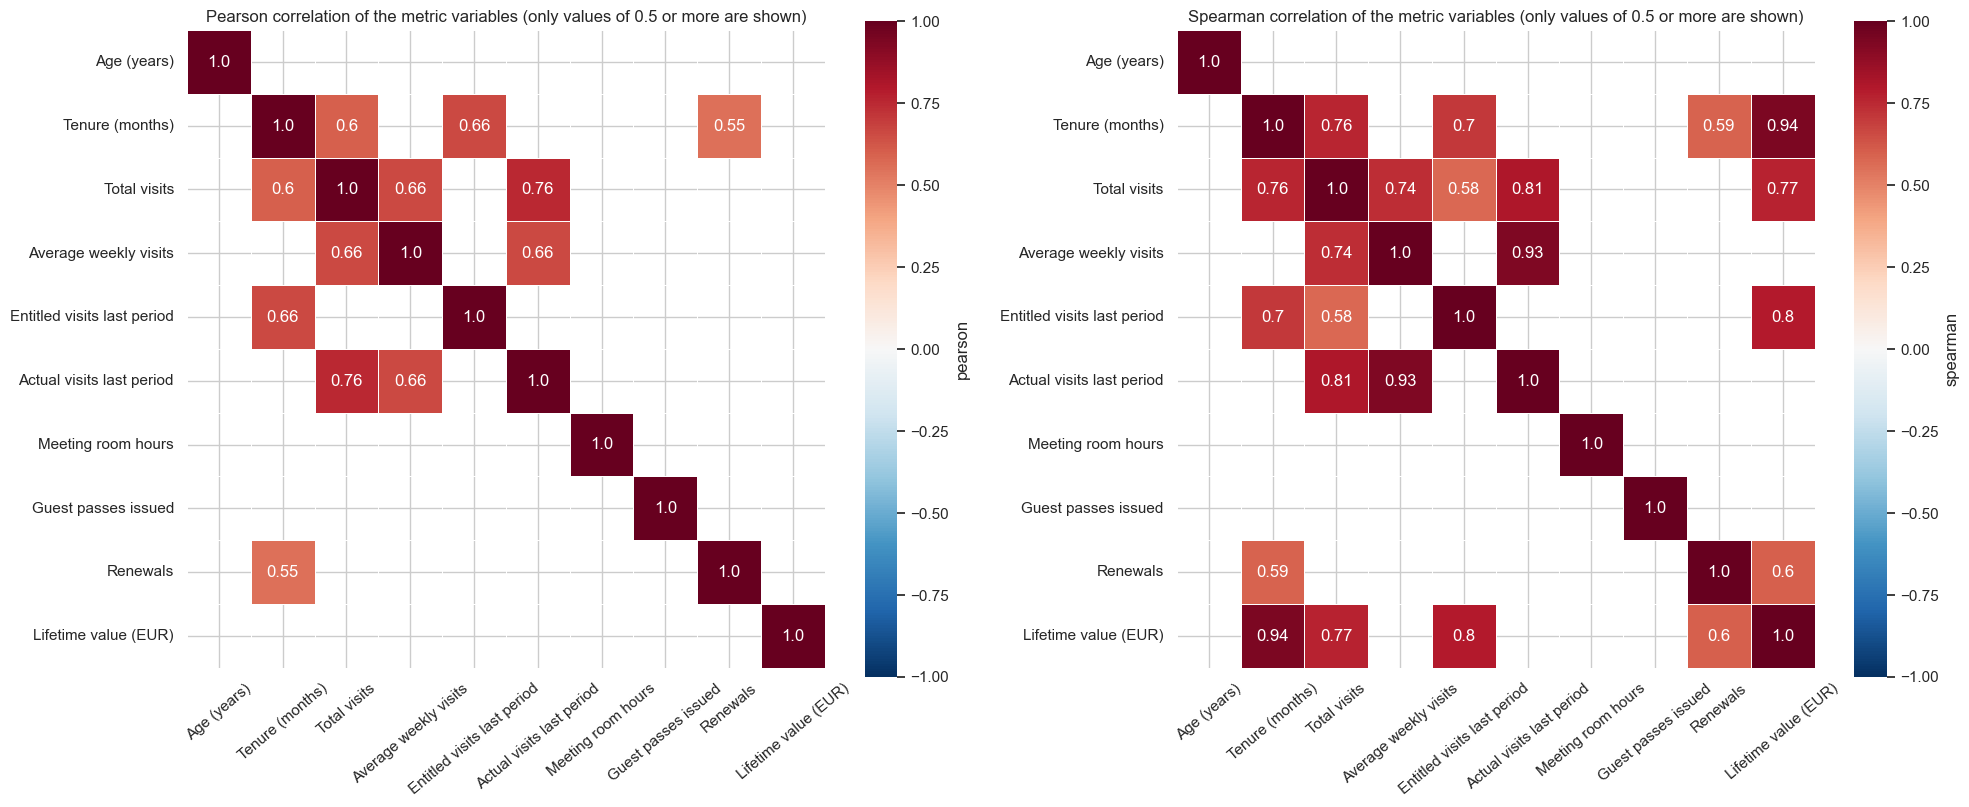

In [87]:
# Correlation heatmaps of the metric variables, Pearson and Spearman side by side. Values below 0.5 in absolute
# terms are masked out, so the eye lands on the pairs that actually move together.
corr_features = ["age", "tenure_months", "total_visits", "avg_weekly_visits", "entitled_visits_last_period",
                 "actual_visits_last_period", "meeting_room_hours", "guest_passes_issued", "n_renewals", "lifetime_value"]
fig, axes = plt.subplots(1, 2, figsize=(20, 8))
for ax, method in zip(axes, ["pearson", "spearman"]):
    corr_matrix = analysis_data[corr_features].corr(method=method)
    corr_matrix.index = [chart_label(c) for c in corr_matrix.index]
    corr_matrix.columns = [chart_label(c) for c in corr_matrix.columns]
    weak_pairs = corr_matrix.abs() < 0.5
    sns.heatmap(corr_matrix, mask=weak_pairs, annot=corr_matrix.round(2), fmt="", vmin=-1, vmax=1, center=0,
                square=True, linewidths=0.5, cmap=CORR_CMAP, ax=ax, cbar_kws={"label": f"{method}"})
    ax.set_title(f"{method.capitalize()} correlation of the metric variables (only values of 0.5 or more are shown)")
    ax.tick_params(axis="x", rotation=40)
    ax.tick_params(axis="y", rotation=0)
fig.tight_layout()
plt.show()

In [88]:
# Which metric pairs are strongest on each measure.
strong_pairs = []
for method in ["pearson", "spearman"]:
    corr_matrix = analysis_data[corr_features].corr(method=method)
    for i, first in enumerate(corr_features):
        for second in corr_features[i + 1:]:
            value = float(corr_matrix.loc[first, second])
            if abs(value) >= 0.5:
                strong_pairs.append({"method": method, "pair": f"{chart_label(first)} ~ {chart_label(second)}",
                                     "r": round(value, 2)})
strong = pd.DataFrame(strong_pairs).sort_values(["method", "r"], ascending=[True, False])
print(strong.to_string(index=False))
print("\nTwo pairs stand out on both measures, and they are pairs that measure the same thing twice: the visits the")
print("member made and the visits the plan entitled, and the hours booked against the flag that says they booked.")

  method                                               pair    r
 pearson           Total visits ~ Actual visits last period 0.76
 pearson      Tenure (months) ~ Entitled visits last period 0.66
 pearson               Total visits ~ Average weekly visits 0.66
 pearson  Average weekly visits ~ Actual visits last period 0.66
 pearson                     Tenure (months) ~ Total visits 0.60
 pearson                         Tenure (months) ~ Renewals 0.55
spearman             Tenure (months) ~ Lifetime value (EUR) 0.94
spearman  Average weekly visits ~ Actual visits last period 0.93
spearman           Total visits ~ Actual visits last period 0.81
spearman Entitled visits last period ~ Lifetime value (EUR) 0.80
spearman                Total visits ~ Lifetime value (EUR) 0.77
spearman                     Tenure (months) ~ Total visits 0.76
spearman               Total visits ~ Average weekly visits 0.74
spearman      Tenure (months) ~ Entitled visits last period 0.70
spearman                 

In [89]:
# Raw-versus-raw redundancy: which of the 31 columns restate each other before anything is engineered.
raw_pairs = [("total_visits", "avg_weekly_visits"), ("entitled_visits_last_period", "actual_visits_last_period"),
             ("plan_days_per_week", "entitled_visits_last_period"), ("meeting_room_hours", "uses_meeting_rooms"),
             ("event_space_hours", "uses_event_space"), ("guest_passes_issued", "uses_guest_passes"),
             ("n_colleagues_on_account", "is_team_account")]
redundancy_rows = []
for first, second in raw_pairs:
    pair = analysis_data[[first, second]].dropna()
    rho = float(pair.corr(method="spearman").iloc[0, 1]) if len(pair) >= 30 else np.nan
    redundancy_rows.append({"pair": f"{first} ~ {second}", "n": len(pair), "spearman": round(rho, 3)})
raw_redundancy = pd.DataFrame(redundancy_rows).sort_values("spearman", ascending=False)
print(raw_redundancy.to_string(index=False))
high_rho = raw_redundancy.loc[raw_redundancy["spearman"] >= 0.95, "pair"].tolist()
print(f"\n{len(high_rho)} pairs sit at 0.95 or above: {', '.join(high_rho)}")
print("Reading: a usage flag and its own hours or passes column carry one dimension, not two, because the flag means")
print("only 'more than zero'. plan_days_per_week and the entitlement re-encode the plan (section 4.7). Total visits")
print("and average weekly visits are related but not interchangeable, since one is a count and one is a rate.")

                                                   pair     n  spearman
              n_colleagues_on_account ~ is_team_account 15297     0.985
                   event_space_hours ~ uses_event_space 15442     0.975
                guest_passes_issued ~ uses_guest_passes 14174     0.965
                meeting_room_hours ~ uses_meeting_rooms 14139     0.964
       plan_days_per_week ~ entitled_visits_last_period 15353     0.885
                       total_visits ~ avg_weekly_visits 15408     0.735
entitled_visits_last_period ~ actual_visits_last_period 15450     0.373

4 pairs sit at 0.95 or above: n_colleagues_on_account ~ is_team_account, event_space_hours ~ uses_event_space, guest_passes_issued ~ uses_guest_passes, meeting_room_hours ~ uses_meeting_rooms
Reading: a usage flag and its own hours or passes column carry one dimension, not two, because the flag means
only 'more than zero'. plan_days_per_week and the entitlement re-encode the plan (section 4.7). Total visits
and average 

In [90]:
# Lifetime value across the plan tiers: the documented ladder against the realised money.
ltv_by_tier = analysis_data.groupby("plan_tier")["lifetime_value"].agg(["count", "median", "mean"]).round(0)
ltv_by_tier = ltv_by_tier.sort_values("median")
order_by_median = ltv_by_tier.index.tolist()
print(ltv_by_tier.to_string())

                count   median     mean
plan_tier                              
hot_desk         4408    356.0   2215.0
flex             4454   1855.0   4114.0
full_time        1946   5840.0  11626.0
dedicated_desk   1208  11026.0  15949.0
private_office    508  21464.0  35168.0


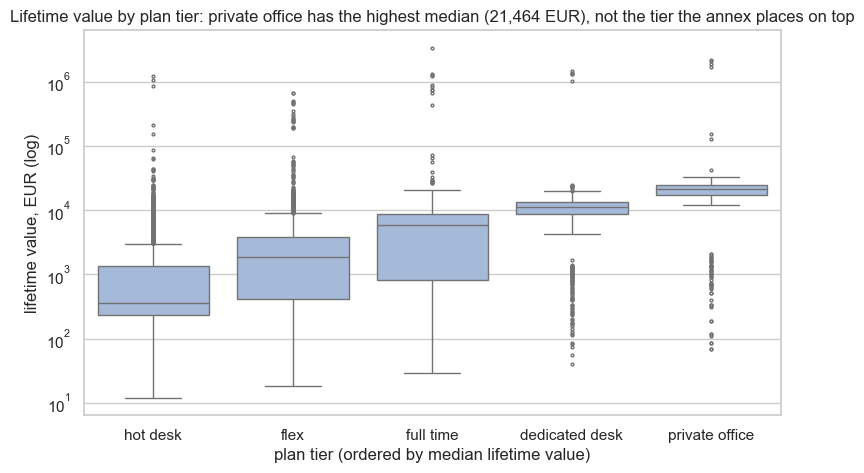

In [91]:
# The same table drawn as box plots, ordered by the median rather than by the documented ladder.
fig, ax = plt.subplots(figsize=(9, 5))
sns.boxplot(data=analysis_data, x="plan_tier", y="lifetime_value", order=order_by_median, color=LIGHT_BLUE,
            fliersize=2, ax=ax)
ax.set(yscale="log", xlabel="plan tier (ordered by median lifetime value)", ylabel="lifetime value, EUR (log)",
       title=f"Lifetime value by plan tier: {order_by_median[-1].replace('_', ' ')} has the highest median "
             f"({ltv_by_tier['median'].iloc[-1]:,.0f} EUR), not the tier the annex places on top")
ax.set_xticks(range(len(order_by_median)), [tier.replace("_", " ") for tier in order_by_median])
plt.show()

In [92]:
# Active against ended members: where the lifecycle split actually bites.
status_medians = analysis_data.groupby("status")[["tenure_months", "total_visits", "lifetime_value",
                                             "actual_visits_last_period", "n_renewals"]].median().round(2)
print("median behaviour by status:")
print(status_medians.to_string())
active_share_by_tier = (analysis_data.groupby(label_missing(analysis_data["plan_tier"]))["is_active"].mean() * 100)
active_share_by_tier = active_share_by_tier.reindex(tier_order + ["(missing)"])
print("\nshare of active members per plan tier (%):")
print(active_share_by_tier.round(1).to_string())
print(f"\nmost retained tier: {active_share_by_tier.idxmax().replace('_', ' ')} ({active_share_by_tier.max():.1f}% active) | "
      f"least retained: {active_share_by_tier.idxmin().replace('_', ' ')} ({active_share_by_tier.min():.1f}% active)")

median behaviour by status:
        tenure_months  total_visits  lifetime_value  actual_visits_last_period  n_renewals
status                                                                                    
active          19.12          17.0         4594.06                        4.0         1.0
ended            8.18          59.0         1452.22                       13.0         0.0

share of active members per plan tier (%):
plan_tier
hot_desk          13.4
flex              20.3
dedicated_desk    56.6
full_time         37.6
private_office    45.0
(missing)         46.7

most retained tier: dedicated desk (56.6% active) | least retained: hot desk (13.4% active)


In [93]:
# The plan tier against membership status, as counts and as the composition of each tier.
tier_labels = label_missing(analysis_data["plan_tier"])
absolute_cross = pd.crosstab(tier_labels, analysis_data["status"]).reindex(tier_order + ["(missing)"])
relative_cross = pd.crosstab(tier_labels, analysis_data["status"], normalize="index").reindex(tier_order + ["(missing)"])
print("counts:")
print(absolute_cross.to_string())
print("\nshare within each tier:")
print((relative_cross * 100).round(1).to_string())

counts:
status          active  ended
plan_tier                    
hot_desk           696   4516
flex              1104   4345
dedicated_desk     876    673
full_time          930   1541
private_office     299    365
(missing)           49     56

share within each tier:
status          active  ended
plan_tier                    
hot_desk          13.4   86.6
flex              20.3   79.7
dedicated_desk    56.6   43.4
full_time         37.6   62.4
private_office    45.0   55.0
(missing)         46.7   53.3


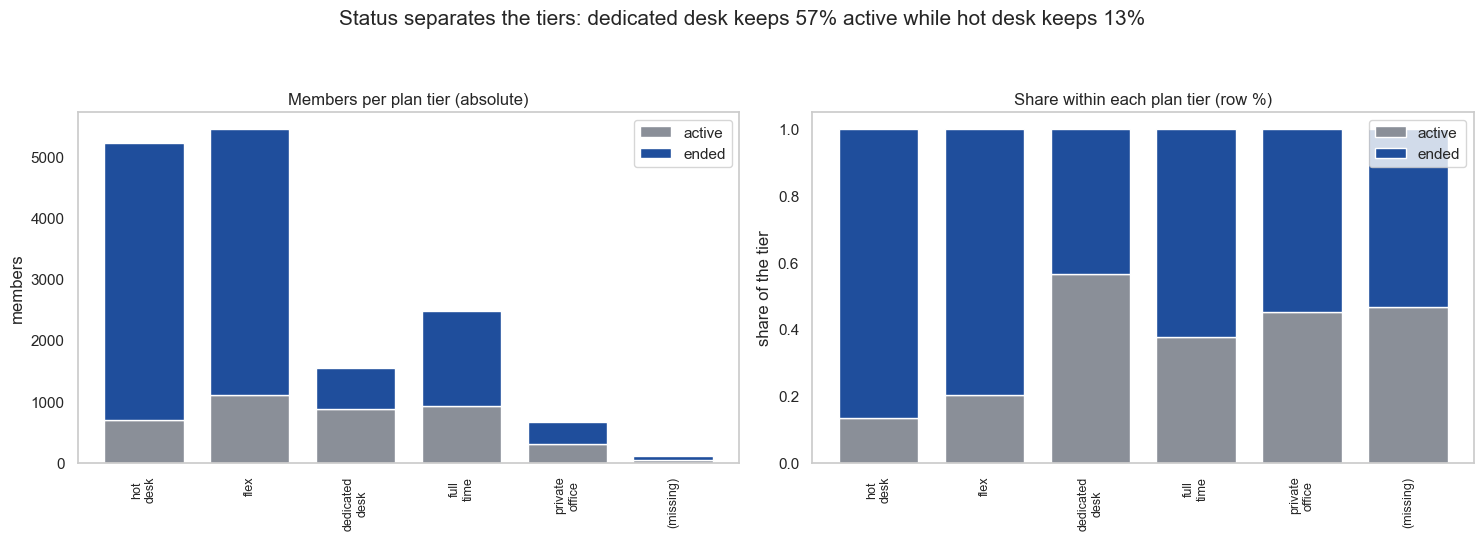

In [94]:
# The same cross as a stacked chart, absolute on the left and as shares on the right.
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), sharex=True)
absolute_cross.plot.bar(stacked=True, ax=axes[0], color=[GRAY, BLUE], edgecolor="white", width=0.75)
axes[0].set(title="Members per plan tier (absolute)", ylabel="members", xlabel="")
relative_cross.plot.bar(stacked=True, ax=axes[1], color=[GRAY, BLUE], edgecolor="white", width=0.75)
axes[1].set(title="Share within each plan tier (row %)", ylabel="share of the tier", xlabel="")
for ax in axes:
    ax.set_xticklabels([t.get_text().replace("_", "\n") for t in ax.get_xticklabels()], fontsize=9)
    ax.grid(False)
    ax.legend(title="", loc="upper right")
fig.suptitle(f"Status separates the tiers: {active_share_by_tier.idxmax().replace('_', ' ')} keeps "
             f"{active_share_by_tier.max():.0f}% active while {active_share_by_tier.idxmin().replace('_', ' ')} keeps "
             f"{active_share_by_tier.min():.0f}%", fontsize=15)
fig.tight_layout(rect=(0, 0, 1, 0.93))
plt.show()

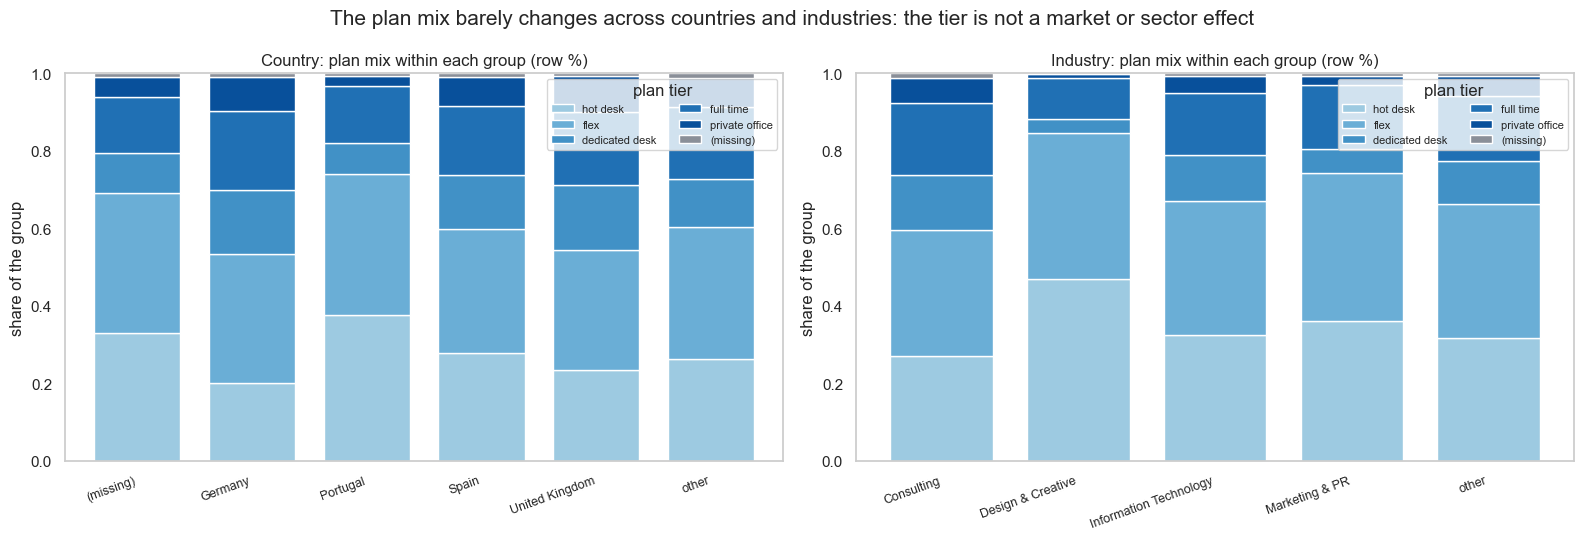

In [95]:
# Country and industry against plan tier: does the market or the sector change what people buy?
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
for ax, column in zip(axes, ["country", "industry"]):
    series = label_missing(analysis_data[column])
    share = series.value_counts(normalize=True) * 100
    top_levels = list(share.index[:4])
    if "(missing)" not in top_levels:
        top_levels.append("(missing)")
    grouped = series.where(series.isin(top_levels), "other")
    tier_levels = [t for t in tier_order + ["(missing)"] if t in set(label_missing(analysis_data["plan_tier"]))]
    mix = pd.crosstab(grouped, tier_labels, normalize="index")[tier_levels]
    mix.plot.bar(stacked=True, ax=ax, color=[TIER_COLORS.get(t, GRAY) for t in tier_levels],
                 edgecolor="white", width=0.75)
    ax.set(title=f"{FEATURE_LABELS[column]}: plan mix within each group (row %)", xlabel="",
           ylabel="share of the group", ylim=(0, 1))
    ax.set_xticklabels([t.get_text() for t in ax.get_xticklabels()], rotation=20, ha="right", fontsize=9)
    ax.grid(False)
    handles, labels = ax.get_legend_handles_labels()
    ax.legend(handles, [l.replace("_", " ") for l in labels], title="plan tier", fontsize=8, ncol=2, loc="upper right")
fig.suptitle("The plan mix barely changes across countries and industries: the tier is not a market or sector effect",
             fontsize=15)
fig.tight_layout()
plt.show()

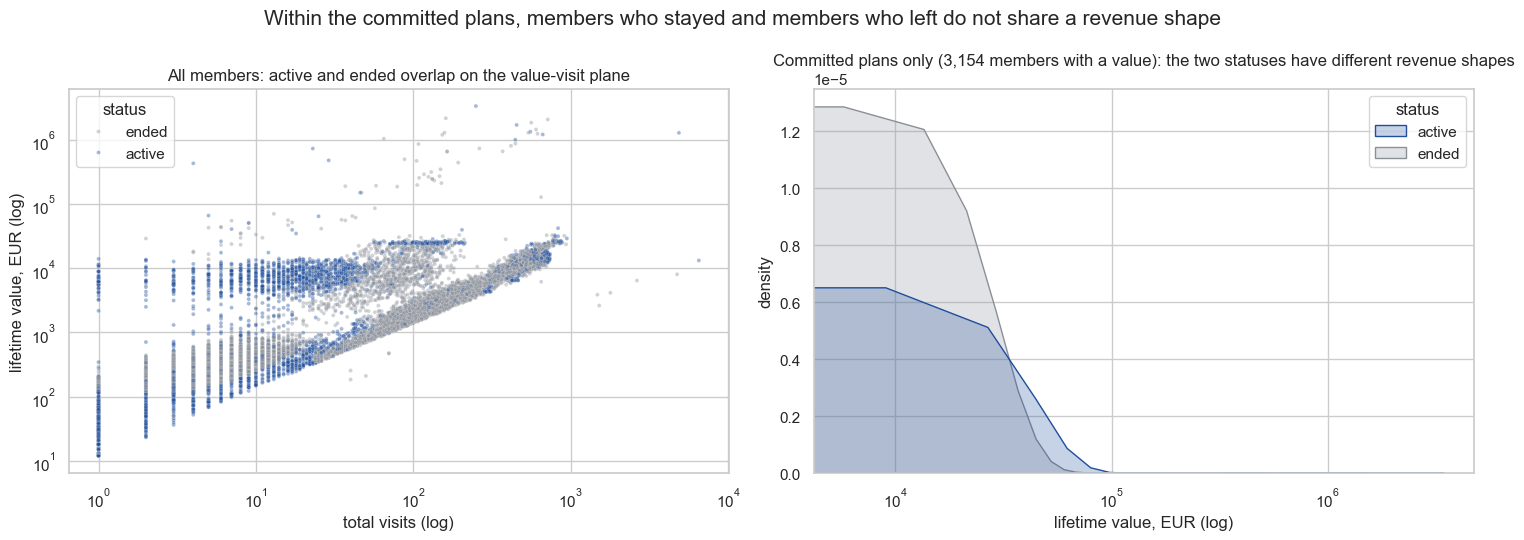

In [96]:
# Do the two populations share one revenue shape? A scatter coloured by status, then a density per status.
commitment_tiers = ["dedicated_desk", "full_time"]
overlay_frame = analysis_data[["total_visits", "lifetime_value", "status", "plan_tier"]].dropna()
overlay_frame = overlay_frame[(overlay_frame["lifetime_value"] > 0) & (overlay_frame["total_visits"] > 0)]
committed = analysis_data[analysis_data["plan_tier"].isin(commitment_tiers)][["lifetime_value", "status"]].dropna()
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
sns.scatterplot(data=overlay_frame, x="total_visits", y="lifetime_value", hue="status",
                palette={"active": BLUE, "ended": GRAY}, s=8, alpha=0.4, ax=axes[0])
axes[0].set(xscale="log", yscale="log", xlabel="total visits (log)", ylabel="lifetime value, EUR (log)",
            title="All members: active and ended overlap on the value-visit plane")
sns.kdeplot(data=committed, x="lifetime_value", hue="status", fill=True, ax=axes[1],
            palette={"active": BLUE, "ended": GRAY})
axes[1].set(xscale="log", xlabel="lifetime value, EUR (log)", ylabel="density",
            title=f"Committed plans only ({len(committed):,} members with a value): the two statuses have "
                  "different revenue shapes")
fig.suptitle("Within the committed plans, members who stayed and members who left do not share a revenue shape",
             fontsize=15)
fig.tight_layout()
plt.show()

### Correlation within groups
We recompute the value-visit relationship separately for active members, ended members and each plan tier. This shows
whether a pooled correlation hides different behaviour in the underlying groups.

In [97]:
# Build the list of populations to compare: the whole base, the two status groups and the five plan tiers.
populations = [("all members", pd.Series(True, index=analysis_data.index)),
               ("active only", analysis_data["is_active"]),
               ("ended only", ~analysis_data["is_active"])]
for tier in tier_order:
    populations.append((f"tier {tier}", analysis_data["plan_tier"] == tier))
print(f"{len(populations)} populations measured:", ", ".join(label for label, _ in populations))

8 populations measured: all members, active only, ended only, tier hot_desk, tier flex, tier dedicated_desk, tier full_time, tier private_office


In [98]:
# Recompute the value-visit correlation inside each of them.
group_rows = []
for label, mask in populations:
    subset = analysis_data.loc[mask, ["lifetime_value", "total_visits"]].dropna()
    subset = subset[(subset > 0).all(axis=1)]
    if len(subset) < 30:
        print(f"skipped {label}: only {len(subset)} members with both values")
        continue
    group_rows.append({"population": label, "n": len(subset),
                       "pearson": round(float(subset.corr().iloc[0, 1]), 3),
                       "spearman": round(float(subset.corr(method="spearman").iloc[0, 1]), 3),
                       "log_pearson": round(float(np.log(subset).corr().iloc[0, 1]), 3)})
within_group = pd.DataFrame(group_rows).set_index("population")
print(within_group.to_string())

                         n  pearson  spearman  log_pearson
population                                                
all members          12500    0.146     0.776        0.775
active only           3175    0.182     0.707        0.678
ended only            9325    0.125     0.878        0.869
tier hot_desk         4373    0.079     0.872        0.833
tier flex             4427    0.076     0.737        0.760
tier dedicated_desk   1203    0.234     0.716        0.450
tier full_time        1934    0.068     0.605        0.618
tier private_office    501    0.074     0.395        0.703


In [99]:
# Does separating the groups change the reading?
within_min, within_max = float(within_group["spearman"].min()), float(within_group["spearman"].max())
print(f"pooled Spearman {spearman_now:.2f} against within-population Spearman from {within_min:.2f} to {within_max:.2f}")
print(f"does the pooled value fall inside the within-group range? {within_min <= spearman_now <= within_max}")
print("Reading: no sign reverses when the groups are separated, since every population shows a positive rank link.")
print("The finding is that the pooled figure sits inside the range rather than hiding a contradiction.")
print("For Deliverable 2 this means a distance on the raw scale is dominated by the value axis, so a rank or log")
print("view, or a separate reading for active and ended members, keeps the other axes visible.")

pooled Spearman 0.78 against within-population Spearman from 0.40 to 0.88
does the pooled value fall inside the within-group range? True
Reading: no sign reverses when the groups are separated, since every population shows a positive rank link.
The finding is that the pooled figure sits inside the range rather than hiding a contradiction.
For Deliverable 2 this means a distance on the raw scale is dominated by the value axis, so a rank or log
view, or a separate reading for active and ended members, keeps the other axes visible.


**What the relationships show.** Plan tier is linked to both value and membership status, and the documented
commitment order does not match the realised revenue order: `full_time` earns less per month than `dedicated_desk`
(section 12 prints both medians), so the annex ladder measures access, not price. The value-visit link rises together
but not in a straight line, which is why the rank and log views carry more information than one pooled linear figure.
Three add-on flags restate their own usage column, and the plan entitlement restates the plan days.

So what: the tier tells us what a member bought, usage and status tell us what the member does, and a segmentation
has to be built on the second set or it will only rediscover the price list.

# 7. Time trends and add-on usage
Two blocks of the file describe behaviour over time and behaviour around the desk: the lifecycle dates and the nine
add-on flags. Both are easy to under-read, so they get their own section: the trends put the ended share in its
proper context, and the add-on fields are the cheapest source of behavioural contrast the extract carries.

In [100]:
# Joins and leaves by month and by year: is the base growing, and does leaving follow a season?
joins_by_month = analysis_data["membership_start"].dt.month.value_counts().sort_index()
leaves_by_month = analysis_data.loc[~analysis_data["is_active"], "membership_end"].dt.month.value_counts().sort_index()
joins_by_year = analysis_data["membership_start"].dt.year.value_counts().sort_index()
leaves_by_year = analysis_data.loc[~analysis_data["is_active"], "membership_end"].dt.year.value_counts().sort_index()
seasonal = pd.DataFrame({"joins": joins_by_month, "leaves": leaves_by_month}).reindex(range(1, 13)).fillna(0).astype(int)
seasonal["net"] = seasonal["joins"] - seasonal["leaves"]
print(seasonal.to_string())
print("\njoins by year:", {int(k): int(v) for k, v in joins_by_year.items()})
print("leaves by year:", {int(k): int(v) for k, v in leaves_by_year.items()})

    joins  leaves   net
1    2115     690  1425
2    1252     654   598
3    1336     780   556
4    1162     848   314
5    1181     920   261
6    1055     864   191
7    1055     998    57
8    1031     999    32
9    1041    1017    24
10   1335    1191   144
11   1344    1180   164
12   1543    1355   188

joins by year: {2021: 7626, 2022: 4449, 2023: 3375}
leaves by year: {2020: 15, 2021: 1677, 2022: 3658, 2023: 6071, 2024: 75}


In [101]:
# The same two tables as charts: months pooled over the window, then the years side by side.
year_index = sorted(set(joins_by_year.index) | set(leaves_by_year.index))
last_year_in_file = int(max(year_index))
full_years = [y for y in year_index if y != last_year_in_file]
print(f"the window ends {reference_date.date()}, so {last_year_in_file} is a partial year and is left out of the comparison")
print(f"starts: {full_years[0]} = {int(joins_by_year.get(full_years[0], 0)):,} | "
      f"last full year {full_years[-1]} = {int(joins_by_year.get(full_years[-1], 0)):,}")
print(f"leaves: {full_years[0]} = {int(leaves_by_year.get(full_years[0], 0)):,} | "
      f"last full year {full_years[-1]} = {int(leaves_by_year.get(full_years[-1], 0)):,}")

the window ends 2024-01-01, so 2024 is a partial year and is left out of the comparison
starts: 2020 = 0 | last full year 2023 = 3,375
leaves: 2020 = 15 | last full year 2023 = 6,071


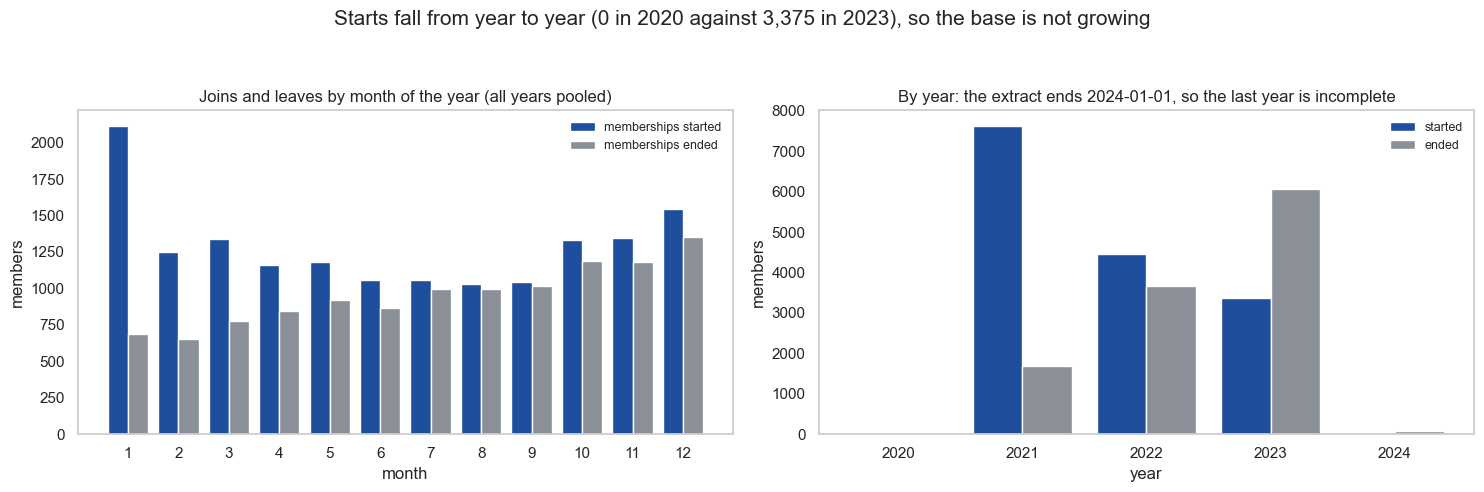

In [102]:
# The two panels: month of the year on the left, calendar year on the right.
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
month_positions = np.arange(12) + 1
axes[0].bar(month_positions - 0.2, seasonal["joins"], width=0.4, color=BLUE, label="memberships started")
axes[0].bar(month_positions + 0.2, seasonal["leaves"], width=0.4, color=GRAY, label="memberships ended")
axes[0].set(title="Joins and leaves by month of the year (all years pooled)", xlabel="month",
            ylabel="members", xticks=month_positions, xticklabels=seasonal.index.tolist())
axes[0].legend(frameon=False, fontsize=9)
axes[0].grid(False)
year_positions = np.arange(len(year_index))
axes[1].bar(year_positions - 0.2, [joins_by_year.get(y, 0) for y in year_index], width=0.4, color=BLUE, label="started")
axes[1].bar(year_positions + 0.2, [leaves_by_year.get(y, 0) for y in year_index], width=0.4, color=GRAY, label="ended")
axes[1].set(title=f"By year: the extract ends {reference_date.date()}, so the last year is incomplete",
            xlabel="year", ylabel="members", xticks=year_positions, xticklabels=[str(y) for y in year_index])
axes[1].legend(frameon=False, fontsize=9)
axes[1].grid(False)
fig.suptitle(f"Starts fall from year to year ({int(joins_by_year.get(full_years[0], 0)):,} in {full_years[0]} against "
             f"{int(joins_by_year.get(full_years[-1], 0)):,} in {full_years[-1]}), so the base is not growing", fontsize=15)
fig.tight_layout(rect=(0, 0, 1, 0.93))
plt.show()

### Churn by start-year cohort
A **cohort** is the group of members who joined in the same year. Splitting the ended share by cohort matters because
a three-year window gives the 2021 joiners years to leave and the last joiners only months, so a single pooled ended
share mixes the two.

In [103]:
# The cohort table, built one cohort at a time.
cohort_years = sorted(analysis_data["membership_start"].dt.year.unique())
cohort_rows = []
for year in cohort_years:
    in_year = analysis_data["membership_start"].dt.year == year
    cohort_rows.append({"cohort": int(year),
                        "members": int(in_year.sum()),
                        "pct_ended": round(float((~analysis_data.loc[in_year, "is_active"]).mean() * 100), 1),
                        "median_tenure_months": round(float(analysis_data.loc[in_year, "tenure_months"].median()), 1),
                        "median_lifetime_value": round(float(analysis_data.loc[in_year, "lifetime_value"].median()), 0)})
cohort = pd.DataFrame(cohort_rows).set_index("cohort")
print(cohort.to_string())

        members  pct_ended  median_tenure_months  median_lifetime_value
cohort                                                                 
2021       7626       79.6                  19.2                 4626.0
2022       4449       83.1                   9.1                 1613.0
2023       3375       51.2                   1.8                  314.0


A later cohort has been observed for less time, so part of the gap between the bars is only how long each
group had a chance to leave. Where the order is not monotone, a real difference between the cohorts is sitting
on top of that difference in exposure, and the pooled ended share is a mixture of the two.


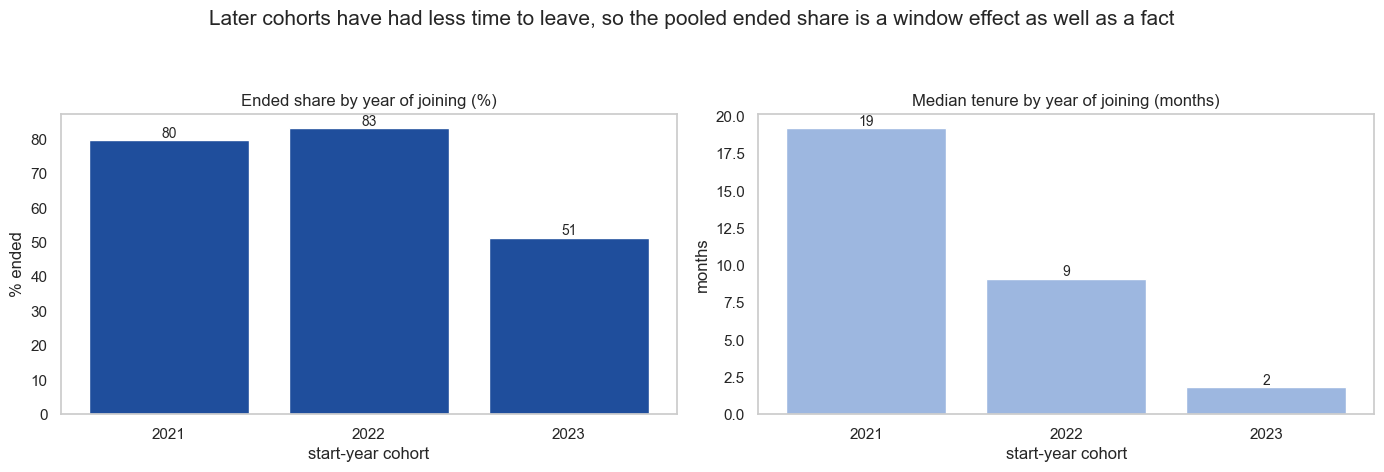

In [104]:
print("A later cohort has been observed for less time, so part of the gap between the bars is only how long each")
print("group had a chance to leave. Where the order is not monotone, a real difference between the cohorts is sitting")
print("on top of that difference in exposure, and the pooled ended share is a mixture of the two.")
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
axes[0].bar([str(y) for y in cohort.index], cohort["pct_ended"], color=BLUE)
axes[0].set(title="Ended share by year of joining (%)", xlabel="start-year cohort", ylabel="% ended")
axes[1].bar([str(y) for y in cohort.index], cohort["median_tenure_months"], color=LIGHT_BLUE)
axes[1].set(title="Median tenure by year of joining (months)", xlabel="start-year cohort", ylabel="months")
for ax in axes:
    ax.bar_label(ax.containers[0], fmt="%.0f", fontsize=10)
    ax.grid(False)
fig.suptitle("Later cohorts have had less time to leave, so the pooled ended share is a window effect as well as a fact",
             fontsize=15)
fig.tight_layout(rect=(0, 0, 1, 0.92))
plt.show()

In [105]:
# Are the uses_* flags consistent with the quantities they claim to flag? A flag with no hours behind it, or hours
# behind no flag, tells us the two fields are written by different processes.
consistency_rows = []
for flag, quantity in [("uses_meeting_rooms", "meeting_room_hours"), ("uses_event_space", "event_space_hours"),
                       ("uses_guest_passes", "guest_passes_issued")]:
    used = analysis_data[flag].astype(bool)
    has_quantity = analysis_data[quantity] > 0
    consistency_rows.append({"flag": flag, "flag_true": int(used.sum()),
                             "flag_and_quantity_above_zero": int((used & has_quantity).sum()),
                             "flag_but_no_quantity": int((used & ~has_quantity).sum()),
                             "quantity_but_no_flag": int((~used & has_quantity).sum())})
flag_consistency = pd.DataFrame(consistency_rows)
print(flag_consistency.to_string(index=False))
n_inconsistent = int(flag_consistency[["flag_but_no_quantity", "quantity_but_no_flag"]].sum().sum())
print(f"\n{n_inconsistent:,} flag/quantity disagreements in total")
print("The quantity columns carry more information than the flags, since a flag says only 'ever'. The flags are used")
print("as the presence indicator and the quantities as the intensity, and the disagreements are reported to ACDC.")

              flag  flag_true  flag_and_quantity_above_zero  flag_but_no_quantity  quantity_but_no_flag
uses_meeting_rooms       5258                          4842                   416                    55
  uses_event_space       1838                          1759                    79                     0
 uses_guest_passes       2811                          2477                   334                     0

884 flag/quantity disagreements in total
The quantity columns carry more information than the flags, since a flag says only 'ever'. The flags are used
as the presence indicator and the quantities as the intensity, and the disagreements are reported to ACDC.


In [106]:
# Add-on take-up: how many members use each service at all?
addon_columns = [c for c in binary_features if c != "is_team_account"]
takeup = (analysis_data[addon_columns].mean() * 100).round(1).sort_values(ascending=False)
print("add-on take-up (% of members):")
print(takeup.to_string())
print(f"\nmost used: {takeup.index[0]} ({takeup.iloc[0]:.1f}%) | rarest: {takeup.index[-1]} ({takeup.iloc[-1]:.1f}%)")
print(f"the rarest one is used by {int(analysis_data[takeup.index[-1]].sum())} of {len(analysis_data):,} members, "
      f"which is {analysis_data[takeup.index[-1]].mean():.2%} of the base")
print("A flag that takes the same value for almost the whole base carries no contrast; section 9 screens every")
print("candidate for this formally before any feature set is proposed.")

add-on take-up (% of members):
uses_meeting_rooms    34.0
uses_print            32.3
uses_phone_booths     25.8
uses_mail_handling    23.0
uses_day_passes       22.0
uses_guest_passes     18.2
uses_storage          14.8
uses_event_space      11.9
uses_bike_locker       0.2

most used: uses_meeting_rooms (34.0%) | rarest: uses_bike_locker (0.2%)
the rarest one is used by 26 of 15,450 members, which is 0.17% of the base
A flag that takes the same value for almost the whole base carries no contrast; section 9 screens every
candidate for this formally before any feature set is proposed.


In [107]:
# Co-usage: for every pair of services, how many members use both? Counted with a plain loop over the pairs.
co_usage_rows = {}
for first in addon_columns:
    row = {}
    for second in addon_columns:
        both = (analysis_data[first].astype(bool) & analysis_data[second].astype(bool)).sum()
        row[second.replace("uses_", "").replace("_", " ")] = round(float(both) / len(analysis_data) * 100, 1)
    co_usage_rows[first.replace("uses_", "").replace("_", " ")] = row
co_usage = pd.DataFrame(co_usage_rows).T
print(co_usage.to_string())

               meeting rooms  event space  guest passes  print  mail handling  phone booths  day passes  storage  bike locker
meeting rooms           34.0          7.9          10.9   15.0           10.0          11.5         8.5      7.6          0.1
event space              7.9         11.9           4.7    5.4            3.1           3.9         3.5      2.1          0.0
guest passes            10.9          4.7          18.2    8.0            5.2           6.2         4.7      3.9          0.0
print                   15.0          5.4           8.0   32.3            9.3          11.3         6.9      6.9          0.0
mail handling           10.0          3.1           5.2    9.3           23.0           8.5         3.1      7.0          0.0
phone booths            11.5          3.9           6.2   11.3            8.5          25.8         5.1      5.7          0.1
day passes               8.5          3.5           4.7    6.9            3.1           5.1        22.0      1.8      

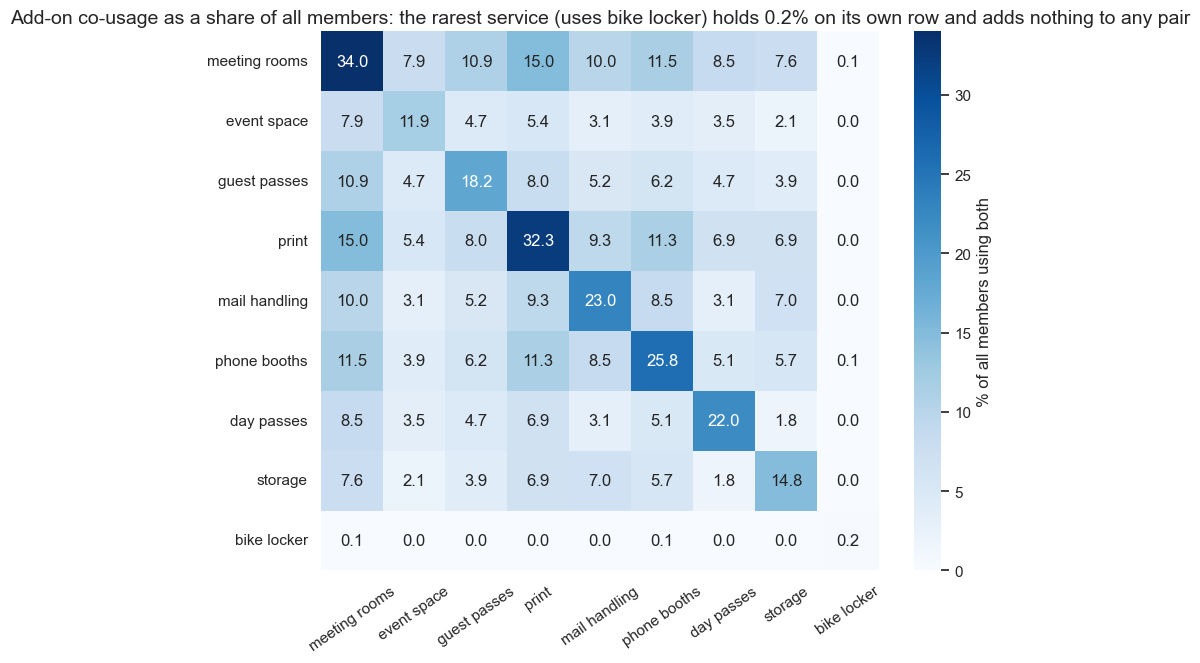

In [108]:
# The same table as a heatmap: the diagonal is each service on its own, so it holds that service's take-up.
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(co_usage, annot=True, fmt=".1f", cmap="Blues", cbar_kws={"label": "% of all members using both"}, ax=ax)
ax.set_title(f"Add-on co-usage as a share of all members: the rarest service ({takeup.index[-1].replace('_', ' ')}) "
             f"holds {takeup.iloc[-1]:.1f}% on its own row and adds nothing to any pair", fontsize=14)
ax.tick_params(axis="x", rotation=35)
ax.tick_params(axis="y", rotation=0)
plt.show()

In [109]:
# Missingness is not uniform: does the chance of a gap depend on the plan or on the membership status?
status_missing_rows = {}
for group_value in ["active", "ended"]:
    in_group = analysis_data["status"] == group_value
    status_missing_rows[group_value] = {c: round(float(analysis_data.loc[in_group, c].isna().mean() * 100), 1)
                                        for c in metric_features}
status_missing = pd.DataFrame(status_missing_rows).T
print("missing % by membership status (rows = status, columns = variable):")
print(status_missing.to_string())

missing % by membership status (rows = status, columns = variable):
        age  n_colleagues_on_account  plan_days_per_week  days_since_last_visit  total_visits  avg_weekly_visits  entitled_visits_last_period  actual_visits_last_period  meeting_room_hours  event_space_hours  guest_passes_issued  n_renewals  lifetime_value
active  4.9                      0.8                 0.8                    9.6           0.3                0.0                          0.0                        0.0                 6.8                0.0                  6.6         0.4            19.3
ended   4.4                      1.1                 0.6                    8.5           0.3                0.0                          0.0                        0.0                 9.1                0.1                  8.8         0.5            18.3


In [110]:
# The same measure taken plan tier by plan tier.
tier_missing_rows = {}
for tier in tier_order:
    in_tier = analysis_data["plan_tier"] == tier
    tier_missing_rows[tier] = {c: round(float(analysis_data.loc[in_tier, c].isna().mean() * 100), 1)
                               for c in metric_features}
tier_missing = pd.DataFrame(tier_missing_rows).T
print("missing % by plan tier (rows = tier, columns = variable):")
print(tier_missing.to_string())
worst_tier = str(tier_missing.mean(axis=1).idxmax())
print(f"\ntier with the most missing values overall: {worst_tier} "
      f"({tier_missing.mean(axis=1).max():.1f}% of its rows missing on the metric variables)")
print(f"the ended population is missing {status_missing.loc['ended'].mean():.1f}% of its metric cells against "
      f"{status_missing.loc['active'].mean():.1f}% for the active one")

missing % by plan tier (rows = tier, columns = variable):
                age  n_colleagues_on_account  plan_days_per_week  days_since_last_visit  total_visits  avg_weekly_visits  entitled_visits_last_period  actual_visits_last_period  meeting_room_hours  event_space_hours  guest_passes_issued  n_renewals  lifetime_value
hot_desk        4.3                      0.9                 0.6                    8.4           0.2                0.0                          0.0                        0.0                11.8                0.0                 10.8         0.3            15.4
flex            4.4                      1.2                 0.8                    8.8           0.3                0.0                          0.0                        0.0                 8.8                0.1                  8.8         0.4            18.3
dedicated_desk  4.9                      0.7                 0.6                    7.9           0.2                0.0                          0

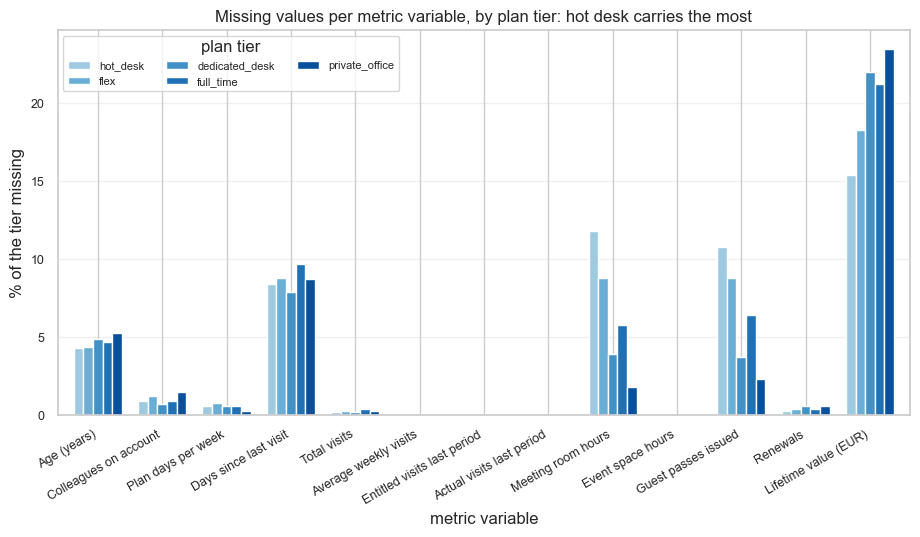

Missingness follows the same two axes a grouping would use, the plan and the status, which is why section 11
registers it as a risk to a later grouping rather than leaving it as a footnote.


In [111]:
# The tier view as a chart: each variable shown once per tier.
fig, ax = plt.subplots(figsize=(11, 5))
tier_missing.T.plot.bar(ax=ax, color=[TIER_COLORS.get(t, GRAY) for t in tier_missing.index], width=0.75)
ax.set(title=f"Missing values per metric variable, by plan tier: {worst_tier.replace('_', ' ')} carries the most",
       xlabel="metric variable", ylabel="% of the tier missing")
ax.set_xticks(range(len(tier_missing.T)), [chart_label(c) for c in tier_missing.columns], rotation=30, ha="right", fontsize=9)
ax.tick_params(axis="y", labelsize=9)
ax.legend(title="plan tier", fontsize=8, ncol=3, loc="upper left")
ax.grid(axis="y", alpha=0.3)
plt.show()
print("Missingness follows the same two axes a grouping would use, the plan and the status, which is why section 11")
print("registers it as a risk to a later grouping rather than leaving it as a footnote.")

In [112]:
# Do the demographic variables say anything about value or status? If not, they stay out of the feature set.
demo_columns = ["gender", "country", "industry"]
profile_rows = []
for column in demo_columns:
    grouped = analysis_data.groupby(label_missing(analysis_data[column]))
    level_rows = pd.DataFrame({"members": grouped.size(),
                               "median_ltv": grouped["lifetime_value"].median(),
                               "pct_active": grouped["is_active"].mean() * 100,
                               "median_visits": grouped["total_visits"].median()})
    big = level_rows.loc[level_rows["members"] >= 100]
    spread = float((big["median_ltv"].max() - big["median_ltv"].min()) / analysis_data["lifetime_value"].median() * 100)
    active_spread = float(big["pct_active"].max() - big["pct_active"].min())
    profile_rows.append({"variable": column, "levels_with_100_plus_members": int(len(big)),
                         "ltv_spread_pct_of_median": round(spread, 1), "active_share_spread_pp": round(active_spread, 1)})
    print(f"--- {column}")
    print(level_rows.round(1).to_string())
    print()
demographic_value = pd.DataFrame(profile_rows).set_index("variable")
print(demographic_value.to_string())

--- gender
           members  median_ltv  pct_active  median_visits
gender                                                   
(missing)      530      1789.2        25.5           43.0
Female        7858      1608.3        25.8           34.0
Male          6565      1728.9        25.3           34.0
Other          497      1628.3        25.6           37.0

--- country
                members  median_ltv  pct_active  median_visits
country                                                       
(missing)           429      1266.6        25.2           35.0
France              533      3425.0        30.4           65.5
Germany             901      4697.0        34.3           68.0
Ireland             244      3648.0        32.8           82.5
Netherlands         487      4198.1        29.2           60.0
Other (Europe)      451      2306.6        24.8           38.0
Portugal          10499      1027.1        23.4           26.0
Spain               741      3189.2        27.8           54.

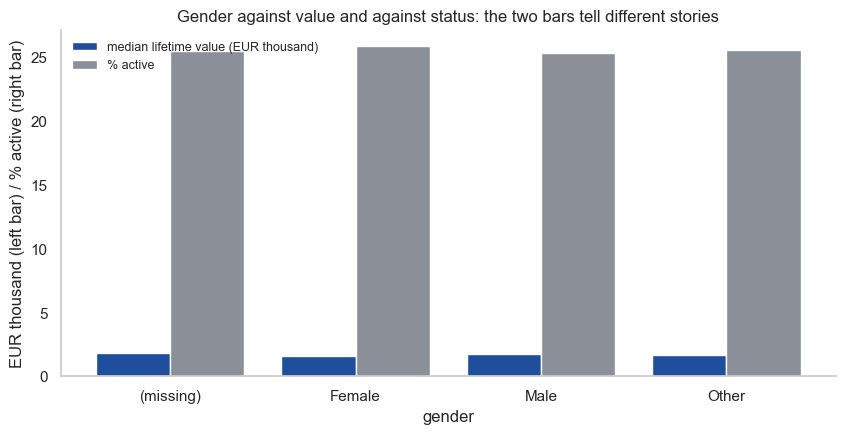

the median lifetime value moves across the gender levels by 10.8% of the overall median, and the active share by 0.5 percentage points


In [113]:
# Gender against value and against status, since the two can point in different directions.
gender_median_ltv = analysis_data.groupby(label_missing(analysis_data["gender"]))["lifetime_value"].median()
gender_pct_active = analysis_data.groupby(label_missing(analysis_data["gender"]))["is_active"].mean() * 100
x = np.arange(len(gender_median_ltv))
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.bar(x - 0.2, gender_median_ltv.values / 1000, width=0.4, color=BLUE, label="median lifetime value (EUR thousand)")
ax.bar(x + 0.2, gender_pct_active.values, width=0.4, color=GRAY, label="% active")
ax.set_xticks(x, gender_median_ltv.index)
ax.set(title="Gender against value and against status: the two bars tell different stories",
       xlabel="gender", ylabel="EUR thousand (left bar) / % active (right bar)")
ax.legend(frameon=False, fontsize=9)
ax.grid(False)
sns.despine()
plt.show()
print(f"the median lifetime value moves across the gender levels by {demographic_value.loc['gender', 'ltv_spread_pct_of_median']:.1f}% "
      f"of the overall median, and the active share by {demographic_value.loc['gender', 'active_share_spread_pp']:.1f} percentage points")

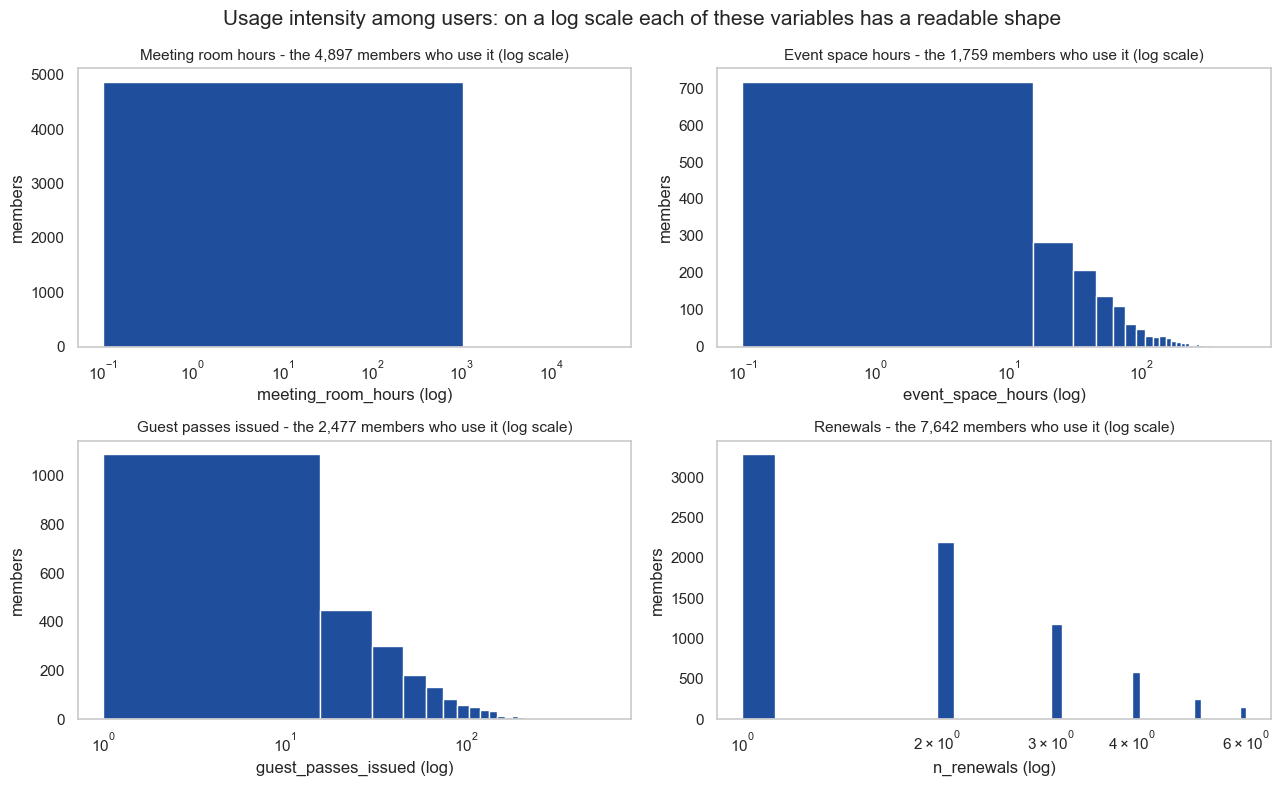

In [114]:
# Log-scale views of the four usage variables whose natural-scale histograms are unreadable.
log_columns = ["meeting_room_hours", "event_space_hours", "guest_passes_issued", "n_renewals"]
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for ax, column in zip(axes.flatten(), log_columns):
    users = analysis_data.loc[analysis_data[column] > 0, column]
    ax.hist(users, bins=40, color=BLUE)
    ax.set_xscale("log")
    ax.set_title(f"{FEATURE_LABELS[column]} - the {len(users):,} members who use it (log scale)", fontsize=11)
    ax.set_xlabel(f"{column} (log)")
    ax.set_ylabel("members")
    ax.grid(False)
fig.suptitle("Usage intensity among users: on a log scale each of these variables has a readable shape", fontsize=15)
fig.tight_layout()
plt.show()

### Which variables enter the analysis, and with what role
The role table below is the decision the brief asks for: what a variable is used for. It is built from the findings
of sections 3 to 7, and every column of it is justified by an output above rather than by preference.

In [115]:
# The variable-role table: what each of the 31 columns is used for, written from the findings above.
role_rows = []
for column in raw.columns:
    if column == "member_id":
        role, reason = "identifier", "the key of the table; never a feature"
    elif column in ("membership_start", "membership_end", "last_badge_swipe"):
        role, reason = "use, to derive tenure, status and recency", "the dates carry the lifecycle; the derived numbers carry it into the analysis"
    elif column == "plan_days_per_week":
        role, reason = "use", "the access level of the plan; the entitlement column re-encodes it (section 4.7)"
    elif column == "entitled_visits_last_period":
        role, reason = "use, as the denominator of allowance used", "it repeats the plan days but is the only entitlement figure the period holds"
    elif column in ("gender", "country", "industry"):
        role, reason = "profile only", "little or no spread in value or status across its levels (cells above)"
    elif column.startswith("uses_"):
        role, reason = "use, presence of the add-on", "the intensity lives in the matching quantity column, the presence here"
    elif column in ("meeting_room_hours", "event_space_hours", "guest_passes_issued"):
        role, reason = "use, intensity among users", "zero-inflated, so presence and intensity are reported separately (section 5)"
    elif column in ("lifetime_value", "total_visits", "n_renewals", "days_since_last_visit", "age",
                    "n_colleagues_on_account", "plan_tier", "is_team_account", "actual_visits_last_period"):
        role, reason = "use", "a direct measure of value, usage, loyalty, recency, profile or account structure"
    else:
        role, reason = "use", "carries information no other column repeats"
    role_rows.append({"variable": column, "role": role, "why": reason})
roles = pd.DataFrame(role_rows).set_index("variable")
print(roles["role"].value_counts().to_string())

role
use                                          11
use, presence of the add-on                   9
profile only                                  3
use, intensity among users                    3
use, to derive tenure, status and recency     3
identifier                                    1
use, as the denominator of allowance used     1


In [116]:
# The full role table, and the columns set aside because another column already carries the same information.
print(roles.to_string())
drop_because_redundant = ["avg_weekly_visits", "entitled_visits_last_period", "premium_hours_total"]
print(f"\nset aside as redundant: {', '.join(drop_because_redundant)}")
print("They stay in the frame for reporting; they are only kept out of any distance-based work, where a second copy")
print("of one dimension would double its own weight.")

                                                                  role                                                                               why
variable                                                                                                                                                
member_id                                                   identifier                                             the key of the table; never a feature
age                                                                use  a direct measure of value, usage, loyalty, recency, profile or account structure
gender                                                    profile only            little or no spread in value or status across its levels (cells above)
industry                                                  profile only            little or no spread in value or status across its levels (cells above)
country                                                   profile only            

So what: the dates, the plan, the usage quantities and the add-on flags earn a place in the analysis, the demographic
columns are profile only, and three columns are set aside because a neighbour already states the same thing.

# 8. Feature engineering
Features fall into two groups. **Base derivations** turn the raw columns into usable form: the membership status, the
tenure, the plan order and the standardised labels. **Engineered features**, or **ratio features**, divide one column
by another to state something no single column says: rate of use, value per unit of time, breadth of add-on use.
Every ratio is guarded by a minimum denominator, because dividing by a membership of a few days produces a monthly
figure nobody would pay.

### Numerical and categorical features, and how each one is treated later
A **numerical** feature is a number on a scale, such as monthly revenue or visits per month: it has an order and a
distance, so "twice as much" means something. A **categorical** feature is a name, such as plan tier or country: it
has levels but no distance between them, so "Portugal minus Spain" is meaningless. `plan_tier` is a special case, an
**ordinal** category, because its levels have a documented order even though the gaps between them are not equal.
This matters for a later grouping and nothing else: distance methods read numbers, so a category has to be turned into
numbers first, by one of the standard encodings, and a numerical feature with a long tail usually has to be put on a
comparable scale first. Both of those are modelling choices, so this notebook does not perform either. It only states
which of its candidate features are numerical, which are categorical and which are ordinal, so that Deliverable 2
knows what it has to decide on.

In [117]:
# Inventory of the base derivations written by sections 4 and 8, separated from the engineered features.
base_derived = ["status", "is_active", "tenure_months", "plan_tier_ordinal", "flag_date_format_dmy"]
flag_columns = [c for c in analysis_data.columns if c.startswith("flag_")]
standardised_labels = categorical_features
print("base derivations:", ", ".join(base_derived))
print("standardised label columns:", ", ".join(standardised_labels))
print(f"flag columns: {len(flag_columns)}")
print("\n".join(f"  {c}" for c in flag_columns))
print(f"\nanalysis_data now holds {analysis_data.shape[1]} columns: 31 raw + {analysis_data.shape[1] - 31} derived and flagged")

base derivations: status, is_active, tenure_months, plan_tier_ordinal, flag_date_format_dmy
standardised label columns: gender, industry, country, plan_tier
flag columns: 44
  flag_date_format_dmy
  flag_age_invalid
  flag_n_colleagues_placeholder
  flag_days_since_last_visit_invalid
  flag_total_visits_negative
  flag_n_renewals_negative
  flag_meeting_room_hours_negative
  flag_event_space_hours_negative
  flag_guest_passes_issued_negative
  flag_tenure_nonpositive
  flag_plan_days_invalid
  flag_ltv_negative
  flag_ltv_zero_as_missing
  flag_ltv_extreme
  flag_meeting_hours_above_capacity
  flag_visits_above_daily_max
  flag_end_before_start
  flag_swipe_before_start
  flag_swipe_after_end
  flag_swipe_after_reference
  flag_team_account_colleagues
  flag_renewals_exceed_tenure
  flag_visits_exceed_entitlement
  flag_no_entitlement_with_visits
  flag_iqr_low_age
  flag_iqr_high_age
  flag_iqr_low_n_colleagues_on_account
  flag_iqr_high_n_colleagues_on_account
  flag_iqr_low_plan_day

In [118]:
# Ordinal encoding of the plan tier, in the order the annex documents. This is a coding of an order, not a scaling.
plan_ordinal = {}
for position, tier in enumerate(tier_order):
    plan_ordinal[tier] = position + 1
analysis_data["plan_tier_ordinal"] = analysis_data["plan_tier"].map(plan_ordinal)
ordinal_rows = []
for code_value in sorted(analysis_data["plan_tier_ordinal"].dropna().unique()):
    in_code = analysis_data["plan_tier_ordinal"] == code_value
    ordinal_rows.append({"plan_tier_ordinal": int(code_value),
                         "tier": analysis_data.loc[in_code, "plan_tier"].iloc[0],
                         "members": int(in_code.sum()),
                         "median_days": float(analysis_data.loc[in_code, "plan_days_per_week"].median()),
                         "median_lifetime_value": round(float(analysis_data.loc[in_code, "lifetime_value"].median()), 0)})
ordinal_check = pd.DataFrame(ordinal_rows).set_index("plan_tier_ordinal")
print("ordinal encoding:", plan_ordinal)
print(ordinal_check.to_string())
print(f"rows with no tier left unencoded: {int(analysis_data['plan_tier_ordinal'].isna().sum()):,}")
print("How to read the code: it orders access, measured in days per week, not price. Section 12 shows that realised")
print("monthly revenue does not rise with it, so the ordinal code is kept as an access ladder and never used as a")
print("money axis.")

ordinal encoding: {'hot_desk': 1, 'flex': 2, 'dedicated_desk': 3, 'full_time': 4, 'private_office': 5}
                             tier  members  median_days  median_lifetime_value
plan_tier_ordinal                                                             
1                        hot_desk     5212          2.0                  356.0
2                            flex     5449          3.0                 1855.0
3                  dedicated_desk     1549          5.0                11026.0
4                       full_time     2471          5.0                 5840.0
5                  private_office      664          7.0                21464.0
rows with no tier left unencoded: 105
How to read the code: it orders access, measured in days per week, not price. Section 12 shows that realised
monthly revenue does not rise with it, so the ordinal code is kept as an access ladder and never used as a
money axis.


In [119]:
# The five ratio features, each guarded so a tiny denominator cannot produce a huge answer.
MIN_TENURE_MONTHS = 3.0
tenure_ok = analysis_data["tenure_months"] >= MIN_TENURE_MONTHS
print(f"the guard is a minimum tenure of {MIN_TENURE_MONTHS:.0f} months, one quarter and long enough to hold at "
      "least one billing cycle")
analysis_data["monthly_revenue"] = (analysis_data["lifetime_value"] / analysis_data["tenure_months"]).where(tenure_ok)
analysis_data["visit_rate"] = (analysis_data["total_visits"] / analysis_data["tenure_months"]).where(tenure_ok)
analysis_data["renewal_rate"] = (analysis_data["n_renewals"] / (analysis_data["tenure_months"] / 12)).where(tenure_ok)
analysis_data["value_per_visit"] = (analysis_data["lifetime_value"] / analysis_data["total_visits"]
                                    ).where(analysis_data["total_visits"] > 0)
analysis_data["utilization_rate"] = (analysis_data["actual_visits_last_period"] / analysis_data["entitled_visits_last_period"]
                                     ).where(analysis_data["entitled_visits_last_period"] > 0)
for feature in ["monthly_revenue", "visit_rate", "renewal_rate", "value_per_visit", "utilization_rate"]:
    values = analysis_data[feature].dropna()
    print(f"{feature:18s} defined for {len(values):,} members | median {values.median():>10,.2f} | "
          f"maximum {values.max():>14,.2f}")

the guard is a minimum tenure of 3 months, one quarter and long enough to hold at least one billing cycle
monthly_revenue    defined for 7,389 members | median     279.49 | maximum      93,717.95
visit_rate         defined for 9,237 members | median       8.49 | maximum         206.56
renewal_rate       defined for 9,224 members | median       0.86 | maximum          19.85
value_per_visit    defined for 12,500 members | median      31.71 | maximum     107,874.75
utilization_rate   defined for 15,440 members | median       0.52 | maximum           1.00


In [120]:
# What the guard actually changed: the same ratios computed on every positive tenure, with no minimum.
ratio_columns = ["monthly_revenue", "visit_rate", "renewal_rate"]
unguarded = pd.DataFrame({
    "monthly_revenue": (analysis_data["lifetime_value"] / analysis_data["tenure_months"]).where(analysis_data["tenure_months"] > 0),
    "visit_rate": (analysis_data["total_visits"] / analysis_data["tenure_months"]).where(analysis_data["tenure_months"] > 0),
    "renewal_rate": (analysis_data["n_renewals"] / (analysis_data["tenure_months"] / 12)).where(analysis_data["tenure_months"] > 0),
})
comparison_rows = []
for feature in ratio_columns:
    comparison_rows.append({"feature": feature,
                            "rows_before_guard": int(unguarded[feature].notna().sum()),
                            "max_before_guard": round(float(unguarded[feature].max()), 1),
                            "rows_after_guard": int(analysis_data[feature].notna().sum()),
                            "max_after_guard": round(float(analysis_data[feature].max()), 1),
                            "p99_after_guard": round(float(analysis_data[feature].quantile(0.99)), 1)})
comparison = pd.DataFrame(comparison_rows).set_index("feature")
print(comparison.to_string())
n_short_tenure = int(unguarded["monthly_revenue"].notna().sum()) - int(tenure_ok.sum())
print(f"\nthe guard removes {n_short_tenure:,} rows from the rate features (tenure below {MIN_TENURE_MONTHS:.0f} months)")
for feature in ratio_columns:
    before = comparison.loc[feature, "max_before_guard"]
    after = comparison.loc[feature, "max_after_guard"]
    if after < before:
        print(f"{feature}: the maximum falls from {before:,.1f} to {after:,.1f}, so the short denominators were "
              "what produced the extreme answer")
    else:
        print(f"{feature}: the maximum stays at {after:,.1f}, held by a member with a long tenure, so the guard "
              "removed unusable denominators rather than trimming answers")

                 rows_before_guard  max_before_guard  rows_after_guard  max_after_guard  p99_after_guard
feature                                                                                                 
monthly_revenue              12469           93717.9              7389          93717.9           1017.1
visit_rate                   15256             206.6              9237            206.6             23.4
renewal_rate                 15233             913.2              9224             19.9              5.9

the guard removes 3,202 rows from the rate features (tenure below 3 months)
monthly_revenue: the maximum stays at 93,717.9, held by a member with a long tenure, so the guard removed unusable denominators rather than trimming answers
visit_rate: the maximum stays at 206.6, held by a member with a long tenure, so the guard removed unusable denominators rather than trimming answers
renewal_rate: the maximum falls from 913.2 to 19.9, so the short denominators were what prod

In [121]:
# The ratios that are not tenure-based, and the contradictions that sit behind them.
n_inf = int(np.isinf(analysis_data[ratio_columns + ["value_per_visit", "utilization_rate"]]).any(axis=1).sum())
check(n_inf == 0, f"{n_inf} rows still hold an infinite ratio, so a denominator is not guarded")
utilization_above_one = int((analysis_data["utilization_rate"] > 1).sum())
over_entitled = analysis_data["flag_visits_exceed_entitlement"]
zero_entitled_with_visits = analysis_data["flag_no_entitlement_with_visits"]
print(f"allowance used above 1 where it is defined: {utilization_above_one} rows "
      f"(defined maximum {analysis_data['utilization_rate'].max():.2f})")
print(f"{int(over_entitled.sum())} rows have visits above the entitlement and {int(zero_entitled_with_visits.sum())} "
      f"have entitlement 0 with visits; they overlap on {int((over_entitled & zero_entitled_with_visits).sum())} rows")
print("Handling: the rows are kept and flagged, and allowance used is defined only where the entitlement is positive,")
print("so a zero denominator becomes a missing value rather than an infinite ratio. Nothing is trimmed to force the")
print("scale inside 1, and the heavy tails that remain are reported in section 11 as a risk, not hidden.")

allowance used above 1 where it is defined: 0 rows (defined maximum 1.00)
8 rows have visits above the entitlement and 8 have entitlement 0 with visits; they overlap on 8 rows
Handling: the rows are kept and flagged, and allowance used is defined only where the entitlement is positive,
so a zero denominator becomes a missing value rather than an infinite ratio. Nothing is trimmed to force the
scale inside 1, and the heavy tails that remain are reported in section 11 as a risk, not hidden.


In [122]:
# One recency feature instead of two half-empty ones: days since the last visit, measured to the anchor that applies
# to that member, with status carried beside it so the two populations are never pooled by accident.
recency_anchor_date = analysis_data["membership_end"].where(~analysis_data["is_active"], reference_date)
analysis_data["recency_days"] = (recency_anchor_date - analysis_data["last_badge_swipe"]).dt.days
analysis_data["recency_anchor"] = analysis_data["is_active"].map({True: "reference date", False: "membership end"})
negative_recency = analysis_data["recency_days"] < 0
analysis_data["flag_recency_negative"] = negative_recency
analysis_data["recency_days"] = analysis_data["recency_days"].where(~negative_recency)
print(analysis_data.groupby("recency_anchor")["recency_days"].describe().round(1).to_string())
print(f"\nrows where the last visit is recorded after its own anchor: {int(negative_recency.sum())} "
      "(badge swipes keep arriving after the extraction date) - flagged and left missing")

                  count  mean    std  min  25%   50%    75%     max
recency_anchor                                                     
membership end  11283.0  24.1   44.2  0.0  4.0  10.0   37.0  1090.0
reference date   3927.0  86.4  113.5  0.0  4.0  20.0  168.5  1212.0

rows where the last visit is recorded after its own anchor: 240 (badge swipes keep arriving after the extraction date) - flagged and left missing


In [123]:
# Cross-check the computed recency against the raw days_since_last_visit column the file already carries.
cross_check = pd.DataFrame({"recency_days": analysis_data["recency_days"],
                            "days_since_last_visit": analysis_data["days_since_last_visit"],
                            "status": analysis_data["status"]}).dropna()
agreement = float(cross_check[["recency_days", "days_since_last_visit"]].corr(method="spearman").iloc[0, 1])
cross_check["same"] = cross_check["recency_days"] == cross_check["days_since_last_visit"]
exact_rows = int(cross_check["same"].sum())
print(f"rank correlation {agreement:.2f} over {len(cross_check):,} rows, exactly equal on {exact_rows:,} of them "
      f"({exact_rows / len(cross_check):.1%})")
for group_value in ["active", "ended"]:
    in_group = cross_check["status"] == group_value
    print(f"  {group_value:7s}: {int(cross_check.loc[in_group, 'same'].sum()):,} of {int(in_group.sum()):,} "
          f"({cross_check.loc[in_group, 'same'].mean():.1%}) agree exactly")
print(f"Reading: the computed measure reproduces ACDC's own number on most rows, which is what validates the anchor")
print("chosen above. The "
      f"{len(cross_check) - exact_rows:,} rows where the two differ, and the {int(negative_recency.sum()):,} rows")
print("where the computed measure is undefined because the swipe is after its anchor, are exactly the cases the raw")
print("column alone would have hidden. recency_days is the feature the analysis uses, because its anchor is stated;")
print("days_since_last_visit stays as the cross-check.")

rank correlation 0.99 over 13,936 rows, exactly equal on 13,143 of them (94.3%)
  active : 3,288 of 3,557 (92.4%) agree exactly
  ended  : 9,855 of 10,379 (95.0%) agree exactly
Reading: the computed measure reproduces ACDC's own number on most rows, which is what validates the anchor
chosen above. The 793 rows where the two differ, and the 240 rows
where the computed measure is undefined because the swipe is after its anchor, are exactly the cases the raw
column alone would have hidden. recency_days is the feature the analysis uses, because its anchor is stated;
days_since_last_visit stays as the cross-check.


In [124]:
# Breadth and mix of add-on use, plus the two intensity features the hypotheses in section 12 need.
analysis_data["n_addons_used"] = analysis_data[addon_columns].sum(axis=1)
analysis_data["premium_hours_total"] = analysis_data["meeting_room_hours"] + analysis_data["event_space_hours"]
analysis_data["team_size"] = analysis_data["n_colleagues_on_account"] + 1
analysis_data["guest_pass_rate"] = (analysis_data["guest_passes_issued"] / analysis_data["tenure_months"]).where(tenure_ok)
analysis_data["visit_intensity_vs_plan"] = (analysis_data["avg_weekly_visits"] / analysis_data["plan_days_per_week"]
                                       ).where(analysis_data["plan_days_per_week"].isin([1, 2, 3, 4, 5, 6, 7]))
analysis_data["start_year_cohort"] = analysis_data["membership_start"].dt.year
print("n_addons_used: range",
      f"{int(analysis_data['n_addons_used'].min())}-{int(analysis_data['n_addons_used'].max())}, "
      f"median {analysis_data['n_addons_used'].median():.0f}, "
      f"{int((analysis_data['n_addons_used'] == 0).sum()):,} members use none of the {len(addon_columns)} add-ons")
print("premium_hours_total is NaN where either component is missing:", int(analysis_data["premium_hours_total"].isna().sum()))
print(f"team_size: individual accounts = 1 ({int((~analysis_data['is_team_account']).sum()):,} members), "
      f"unknown colleagues left missing ({int(analysis_data['team_size'].isna().sum()):,})")
print(f"guest_pass_rate: median among users {analysis_data.loc[analysis_data['guest_passes_issued'] > 0, 'guest_pass_rate'].median():.2f} "
      f"passes per month")
print(f"visit_intensity_vs_plan: median {analysis_data['visit_intensity_vs_plan'].median():.2f} visits per entitled day per week")
print(f"start_year_cohort values:", {int(k): int(v) for k, v in analysis_data['start_year_cohort'].value_counts().sort_index().items()})

n_addons_used: range 0-8, median 1, 3,087 members use none of the 9 add-ons
premium_hours_total is NaN where either component is missing: 1314
team_size: individual accounts = 1 (11,100 members), unknown colleagues left missing (153)
guest_pass_rate: median among users 1.47 passes per month
visit_intensity_vs_plan: median 0.52 visits per entitled day per week
start_year_cohort values: {2021: 7626, 2022: 4449, 2023: 3375}


### Add-on mix
`n_addons_used` counts how many services a member touches; it says nothing about which. `addon_mix` names the
profile: none, single-service, or the family of services the member concentrates on. Concentration matters to ACDC
because a re-engagement offer for a meeting-room user is not an offer for a storage user.

In [125]:
# addon_mix: which family of add-ons does a member concentrate on? The flags are grouped by family first.
addon_family = {"uses_meeting_rooms": "meeting rooms", "uses_phone_booths": "meeting rooms",
                "uses_event_space": "events", "uses_day_passes": "events",
                "uses_guest_passes": "guests", "uses_print": "office services", "uses_mail_handling": "office services",
                "uses_storage": "office services", "uses_bike_locker": "office services"}
family_counts = pd.DataFrame(index=analysis_data.index)
for family in sorted(set(addon_family.values())):
    member_flags = [c for c in addon_columns if addon_family[c] == family]
    family_counts[family] = analysis_data[member_flags].astype(bool).sum(axis=1)
print("services counted in each family:")
for family in family_counts.columns:
    services = [c for c in addon_columns if addon_family[c] == family]
    print(f"  {family:16s} {', '.join(services)}")
print("\nadd-on flags grouped into families, so a member's dominant family is their own concentration:")
print(family_counts.sum().to_string())

services counted in each family:
  events           uses_event_space, uses_day_passes
  guests           uses_guest_passes
  meeting rooms    uses_meeting_rooms, uses_phone_booths
  office services  uses_print, uses_mail_handling, uses_storage, uses_bike_locker

add-on flags grouped into families, so a member's dominant family is their own concentration:
events              5232
guests              2811
meeting rooms       9248
office services    10871


In [126]:
# The dominant family for each member, and the three-way label built by plain assignment rather than nested rules.
focused_share = 0.6
analysis_data["addon_dominant_family"] = family_counts.idxmax(axis=1)
analysis_data["addon_dominant_share"] = family_counts.max(axis=1) / family_counts.sum(axis=1).replace(0, np.nan)
analysis_data["addon_mix"] = "mixed services"
analysis_data.loc[analysis_data["n_addons_used"] == 0, "addon_mix"] = "none"
focused = analysis_data["addon_dominant_share"] >= focused_share
analysis_data.loc[focused, "addon_mix"] = analysis_data.loc[focused, "addon_dominant_family"] + " (focused)"
print(analysis_data["addon_mix"].value_counts().to_string())
print(f"\nrule: 'none' when the member uses no add-on at all; '<family> (focused)' when one family holds "
      f"{focused_share:.0%} or more of that member's add-ons; 'mixed services' otherwise")
print("The dominant family is each member's own concentration, not a tier average, so the label is derived from the")
print("row rather than typed in by hand.")

addon_mix
mixed services               5499
office services (focused)    3284
none                         3087
meeting rooms (focused)      1974
events (focused)             1309
guests (focused)              297

rule: 'none' when the member uses no add-on at all; '<family> (focused)' when one family holds 60% or more of that member's add-ons; 'mixed services' otherwise
The dominant family is each member's own concentration, not a tier average, so the label is derived from the
row rather than typed in by hand.


In [127]:
# Documentation of the engineered features, part 1: the ratios built above.
documentation_columns = ["feature", "formula", "perspective", "behaviour_captured", "why_raw_columns_are_not_enough",
                         "expected_clustering_contribution"]
feature_documentation = pd.DataFrame([
    ("monthly_revenue", "lifetime_value / tenure_months, tenure 3 months or more", "Value",
     "how much the member pays per month, not in total",
     "lifetime_value is a level and tenure is a duration; neither states the rate, and the rate is what a price-sensitive group needs",
     "separates a long cheap membership from a short expensive one"),
    ("visit_rate", "total_visits / tenure_months, tenure 3 months or more", "Behaviour",
     "attendance intensity over the whole membership",
     "total_visits counts attendance and tenure counts time; avg_weekly_visits is a weekly figure the file computes on its own window",
     "separates the occasional visitor from the daily one at equal tenure"),
    ("value_per_visit", "lifetime_value / total_visits, visits above 0", "Value",
     "what a visit is worth",
     "it is the only feature that separates paying for a desk from paying for services",
     "separates high-spend low-attendance accounts from attendance-driven ones"),
    ("utilization_rate", "actual_visits_last_period / entitled_visits_last_period, entitlement above 0", "Behaviour",
     "the share of the paid allowance actually used",
     "the entitlement column re-encodes the plan (section 4.7), so the ratio against it is the only use signal the pair carries",
     "the core of the dormant-payer hypothesis"),
    ("renewal_rate", "n_renewals / (tenure_months / 12), tenure 3 months or more", "Loyalty",
     "renewals per year of membership",
     "n_renewals counts events over an unstated period; per year it becomes comparable across tenures",
     "separates a loyal long member from a recently renewed short one"),
    ("recency_days", "anchor date minus last_badge_swipe, anchor chosen by status", "Behaviour",
     "days since the member was last physically present",
     "the raw days_since_last_visit column disagrees with the dates in the same row (cell above), so a computed measure with a stated anchor is needed",
     "the strongest single leaving signal, and it is only readable together with status"),
], columns=documentation_columns)
print(feature_documentation[["feature", "perspective", "formula"]].to_string(index=False))

         feature perspective                                                                      formula
 monthly_revenue       Value                      lifetime_value / tenure_months, tenure 3 months or more
      visit_rate   Behaviour                        total_visits / tenure_months, tenure 3 months or more
 value_per_visit       Value                                lifetime_value / total_visits, visits above 0
utilization_rate   Behaviour actual_visits_last_period / entitled_visits_last_period, entitlement above 0
    renewal_rate     Loyalty                   n_renewals / (tenure_months / 12), tenure 3 months or more
    recency_days   Behaviour                  anchor date minus last_badge_swipe, anchor chosen by status


In [128]:
# Documentation of the engineered features, part 2: lifecycle, access and service breadth.
feature_documentation = pd.concat([feature_documentation, pd.DataFrame([
    ("tenure_months", "(membership_end or reference_date - membership_start) / 30.44", "Lifecycle",
     "length of the relationship",
     "a date pair is not a number, and every rate feature needs this denominator",
     "the lifecycle axis itself"),
    ("plan_tier_ordinal", "documented tier order written as 1 to 5", "Access",
     "the access level the member pays for",
     "the tier is text, so a distance needs a number, and the order is documented rather than invented",
     "an access ladder; section 12 shows it is not a money ladder"),
    ("n_addons_used", "count of the nine uses_* flags", "Behaviour",
     "breadth of service use",
     "each flag says only yes or no about one service; the count says how much of the catalogue the member lives in",
     "separates single-service users from platform users"),
    ("addon_mix", "dominant add-on family at 60% or more of the member's own add-on count, else mixed", "Behaviour",
     "which family of services the member concentrates on",
     "n_addons_used counts services but cannot say which, and an offer has to be aimed at one",
     "turns breadth into a targeting axis"),
], columns=documentation_columns)], ignore_index=True)
print(feature_documentation[["feature", "perspective", "formula"]].to_string(index=False))

          feature perspective                                                                            formula
  monthly_revenue       Value                            lifetime_value / tenure_months, tenure 3 months or more
       visit_rate   Behaviour                              total_visits / tenure_months, tenure 3 months or more
  value_per_visit       Value                                      lifetime_value / total_visits, visits above 0
 utilization_rate   Behaviour       actual_visits_last_period / entitled_visits_last_period, entitlement above 0
     renewal_rate     Loyalty                         n_renewals / (tenure_months / 12), tenure 3 months or more
     recency_days   Behaviour                        anchor date minus last_badge_swipe, anchor chosen by status
    tenure_months   Lifecycle                      (membership_end or reference_date - membership_start) / 30.44
plan_tier_ordinal      Access                                            documented tier order w

In [129]:
# Documentation of the engineered features, part 3: rates, premium use, account size and cohort.
feature_documentation = pd.concat([feature_documentation, pd.DataFrame([
    ("guest_pass_rate", "guest_passes_issued / tenure_months, tenure 3 months or more", "Behaviour",
     "how often the member brings other people in",
     "a raw count of passes is meaningless across different tenures, and the flag loses the intensity",
     "a referral-shaped behaviour signal"),
    ("visit_intensity_vs_plan", "avg_weekly_visits / plan_days_per_week", "Behaviour",
     "how many of the entitled days per week the member actually attends",
     "the file's weekly figure has no reference to what the member paid for; this ratio supplies it",
     "a second view of dormancy, independent of the entitlement denominator"),
    ("premium_hours_total", "meeting_room_hours + event_space_hours", "Behaviour",
     "total hours of premium facilities",
     "the two columns measure the same kind of behaviour, and one premium-intensity figure is steadier than two",
     "carries the premium-service axis; section 9 shows it largely repeats meeting hours"),
    ("team_size", "n_colleagues_on_account + 1", "Account",
     "how many people the membership covers",
     "colleagues counts the other people; the membership covers the member too, so the account size is one more",
     "separates an individual from a department, which changes what a group means commercially"),
    ("start_year_cohort", "year of membership_start", "Lifecycle",
     "when the member joined",
     "the window truncates the younger cohorts (section 7), so tenure alone confuses a new member with a short one",
     "lets a grouping separate a new member from a churned one instead of pooling them"),
], columns=documentation_columns)], ignore_index=True)
print(feature_documentation[["feature", "perspective", "formula"]].to_string(index=False))

                feature perspective                                                                            formula
        monthly_revenue       Value                            lifetime_value / tenure_months, tenure 3 months or more
             visit_rate   Behaviour                              total_visits / tenure_months, tenure 3 months or more
        value_per_visit       Value                                      lifetime_value / total_visits, visits above 0
       utilization_rate   Behaviour       actual_visits_last_period / entitled_visits_last_period, entitlement above 0
           renewal_rate     Loyalty                         n_renewals / (tenure_months / 12), tenure 3 months or more
           recency_days   Behaviour                        anchor date minus last_badge_swipe, anchor chosen by status
          tenure_months   Lifecycle                      (membership_end or reference_date - membership_start) / 30.44
      plan_tier_ordinal      Access             

In [130]:
# The evidence that each feature can place a member at all: coverage, and the middle half of its values.
coverage_rows = []
for feature in feature_documentation["feature"]:
    values = analysis_data[feature]
    numeric_values = pd.to_numeric(values, errors="coerce").dropna()
    if len(numeric_values):
        middle = f"{numeric_values.quantile(0.25):,.2f} to {numeric_values.quantile(0.75):,.2f}"
        typical = round(float(numeric_values.median()), 2)
    else:
        middle, typical = "not a number", None
    coverage_rows.append({"feature": feature, "coverage_pct": round(float(values.notna().mean() * 100), 1),
                          "distinct_values": int(values.nunique()), "median": typical, "middle_half": middle})
coverage = pd.DataFrame(coverage_rows).set_index("feature")
print(coverage.to_string())
print(f"\n{len(coverage)} engineered features documented; "
      f"{int((coverage['coverage_pct'] < 50).sum())} of them cover under half the members and are treated as")
print("profile-only in section 13, since a feature that cannot place most of the base cannot group it.")

                         coverage_pct  distinct_values   median           middle_half
feature                                                                              
monthly_revenue                  47.8             7024   279.49      188.60 to 392.43
visit_rate                       59.8             7628     8.49         4.18 to 12.18
value_per_visit                  80.9            11956    31.71        20.75 to 74.65
utilization_rate                 99.9             2877     0.52          0.24 to 0.80
renewal_rate                     59.7             2206     0.86          0.00 to 1.56
recency_days                     98.4              405    12.00         4.00 to 45.00
tenure_months                    99.0             1091     9.28         2.14 to 20.93
plan_tier_ordinal                99.3                5     2.00          1.00 to 3.00
n_addons_used                   100.0                9     1.00          1.00 to 3.00
addon_mix                       100.0                6



15 engineered features documented; 1 of them cover under half the members and are treated as
profile-only in section 13, since a feature that cannot place most of the base cannot group it.


In [131]:
# The reasoning column in full, so every feature has a stated purpose rather than an assumed one.
print(feature_documentation[["feature", "behaviour_captured", "why_raw_columns_are_not_enough",
                             "expected_clustering_contribution"]].to_string(index=False))

                feature                                                 behaviour_captured                                                                                                                   why_raw_columns_are_not_enough                                                         expected_clustering_contribution
        monthly_revenue                   how much the member pays per month, not in total                  lifetime_value is a level and tenure is a duration; neither states the rate, and the rate is what a price-sensitive group needs                             separates a long cheap membership from a short expensive one
             visit_rate                     attendance intensity over the whole membership                  total_visits counts attendance and tenure counts time; avg_weekly_visits is a weekly figure the file computes on its own window                      separates the occasional visitor from the daily one at equal tenure
        value_per_visit  

So what: fifteen features turn the file's levels, dates and flags into rates and durations, each guarded by a
denominator that makes sense, and section 9 now has to check which of them say anything the others have not already
said.

# 9. Engineered feature patterns
We look at the shape of the engineered features, at how far they move together, and at which of them restate the same
information. Two checks follow from that: a feature that barely varies cannot separate anyone, and a duplicated
dimension would be counted twice by any distance. Nothing here is scaled or encoded; the checks only describe.

In [132]:
# Summary statistics of the numeric engineered features.
engineered_numeric = ["tenure_months", "monthly_revenue", "visit_rate", "value_per_visit", "utilization_rate",
                      "renewal_rate", "recency_days", "n_addons_used", "premium_hours_total", "team_size",
                      "guest_pass_rate", "visit_intensity_vs_plan", "plan_tier_ordinal"]
analysis_data[engineered_numeric].describe(percentiles=[0.01, 0.5, 0.99]).round(2).T

,count,mean,std,min,1%,50%,99%,max
tenure_months,15298.0,12.31,11.13,0.07,0.26,9.28,35.97,35.97
monthly_revenue,7389.0,549.93,3336.76,118.90,119.84,279.49,1017.12,93717.95
visit_rate,9237.0,9.14,7.29,0.00,0.05,8.49,23.38,206.56
value_per_visit,12500.0,159.63,1193.24,1.70,14.07,31.71,2368.50,107874.75
utilization_rate,15440.0,0.52,0.31,0.00,0.00,0.52,1.00,1.00
renewal_rate,9224.0,1.12,1.27,0.00,0.00,0.86,5.94,19.85
recency_days,15210.0,40.19,74.27,0.00,1.00,12.00,304.00,1212.00
n_addons_used,15450.0,1.82,1.50,0.00,0.00,1.00,6.00,8.00
premium_hours_total,14136.0,38.42,430.91,0.00,0.00,0.00,412.02,41220.00
team_size,15297.0,1.58,1.15,1.00,1.00,1.00,6.00,10.00


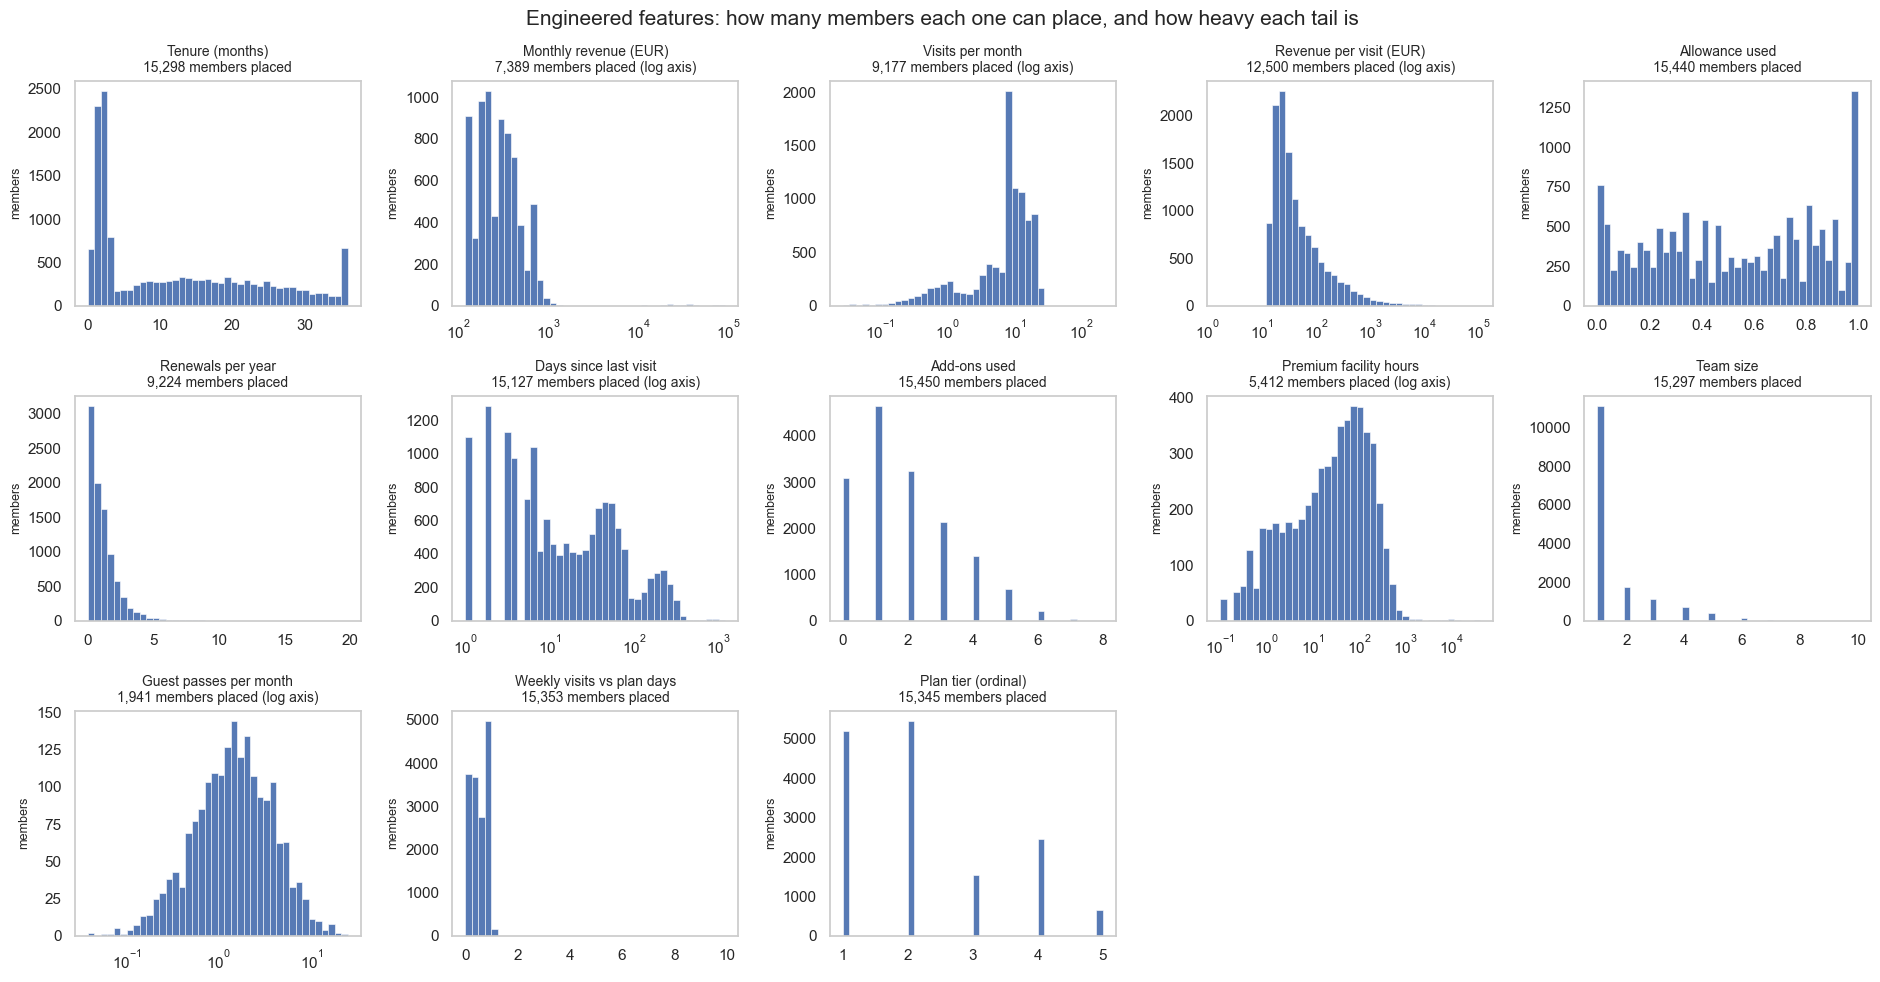

In [133]:
# One panel per engineered feature, on a log axis where the tail makes the natural axis unreadable.
log_needed = ["monthly_revenue", "visit_rate", "value_per_visit", "guest_pass_rate", "premium_hours_total",
              "recency_days"]
fig, axes = plt.subplots(3, 5, figsize=(19, 10))
for ax, feature in zip(axes.flatten(), engineered_numeric):
    values = analysis_data[feature].dropna()
    use_log = feature in log_needed
    if use_log:
        values = values[values > 0]
    sns.histplot(values, bins=40, color=BLUE, log_scale=use_log, ax=ax)
    ax.set_title(f"{FEATURE_LABELS[feature]}\n{len(values):,} members placed"
                 + (" (log axis)" if use_log else ""), fontsize=10)
    ax.set_xlabel("")
    ax.set_ylabel("members", fontsize=9)
    ax.grid(False)
for ax in axes.flatten()[len(engineered_numeric):]:
    ax.set_visible(False)
fig.suptitle("Engineered features: how many members each one can place, and how heavy each tail is", fontsize=15)
fig.tight_layout()
plt.show()

### Low-variance screening
A feature only helps a grouping if the members differ on it. Two plain measures say whether they do:
**coverage**, the share of members the feature can place at all, and the **share of the most common value**, that is
how many members sit on the single value most of the base takes. A column whose most common value holds almost
everyone, or whose **standard deviation** (the typical distance of the values from the average) is near zero, is
**near-constant**: it carries no contrast, and a distance would treat every member as identical on it.

In [134]:
# The candidate list the screening runs over: engineered features plus the raw flags and quantities they sit on.
candidate_columns = engineered_numeric + ["start_year_cohort", "addon_mix"] + addon_columns + [
    "lifetime_value", "total_visits", "actual_visits_last_period", "entitled_visits_last_period",
    "avg_weekly_visits", "plan_days_per_week", "meeting_room_hours", "event_space_hours", "guest_passes_issued",
    "n_renewals", "days_since_last_visit", "age", "n_colleagues_on_account", "is_team_account"]
print(f"{len(candidate_columns)} candidate columns screened")

38 candidate columns screened


In [135]:
# The screening table: coverage, distinct values, the share of the most common value and the standard deviation.
screening_rows = []
for column in candidate_columns:
    values = analysis_data[column]
    modal_share = float(values.value_counts(normalize=True).iloc[0] * 100) if values.notna().any() else 100.0
    numeric_values = pd.to_numeric(values, errors="coerce")
    screening_rows.append({"feature": column,
                           "coverage_pct": round(float(values.notna().mean() * 100), 1),
                           "distinct_values": int(values.nunique()),
                           "most_common_value_pct": round(modal_share, 1),
                           "std": round(float(numeric_values.std()), 3) if numeric_values.notna().any() else None})
screening = pd.DataFrame(screening_rows).set_index("feature")
print(screening.to_string())

                             coverage_pct  distinct_values  most_common_value_pct        std
feature                                                                                     
tenure_months                        99.0             1091                    3.7     11.133
monthly_revenue                      47.8             7024                    0.2   3336.764
visit_rate                           59.8             7628                    0.6      7.290
value_per_visit                      80.9            11956                    0.2   1193.239
utilization_rate                     99.9             2877                    4.9      0.312
renewal_rate                         59.7             2206                   26.0      1.265
recency_days                         98.4              405                    8.4     74.270
n_addons_used                       100.0                9                   30.1      1.504
premium_hours_total                  91.5             2025            

In [136]:
# The rule, applied to the whole table at once rather than to one column by hand.
NEAR_CONSTANT_SHARE = 99.0
near_constant = screening.loc[screening["most_common_value_pct"] >= NEAR_CONSTANT_SHARE]
low_coverage = screening.loc[screening["coverage_pct"] < 50]
print(f"rule: a feature is near-constant when the most common value holds {NEAR_CONSTANT_SHARE:.0f}% or more of the")
print(f"members, and thin when it covers under 50% of them. Applied to all {len(screening)} candidates.")
print(f"\nnear-constant ({len(near_constant)}): {', '.join(near_constant.index) or 'none'}")
print(f"thin coverage, under half the base ({len(low_coverage)}): {', '.join(low_coverage.index) or 'none'}")
print(f"largest modal share: {screening['most_common_value_pct'].idxmax()} at "
      f"{screening['most_common_value_pct'].max():.1f}% of members on one value")
print("Every near-constant feature is kept out of the candidate set in section 13. This is a systematic screen over")
print("all the candidates, not a comment about one unlucky add-on flag.")

rule: a feature is near-constant when the most common value holds 99% or more of the
members, and thin when it covers under 50% of them. Applied to all 38 candidates.

near-constant (1): uses_bike_locker
thin coverage, under half the base (1): monthly_revenue
largest modal share: uses_bike_locker at 99.8% of members on one value
Every near-constant feature is kept out of the candidate set in section 13. This is a systematic screen over
all the candidates, not a comment about one unlucky add-on flag.


### How far the features move together
The heatmap below is the ordinary Spearman matrix, so it needs no extra machinery: it answers "when one feature is
high for a member, is the other usually high too?". The pairs at the top of it are then listed in a table, because
the pairs that matter are the ones that nearly repeat each other.

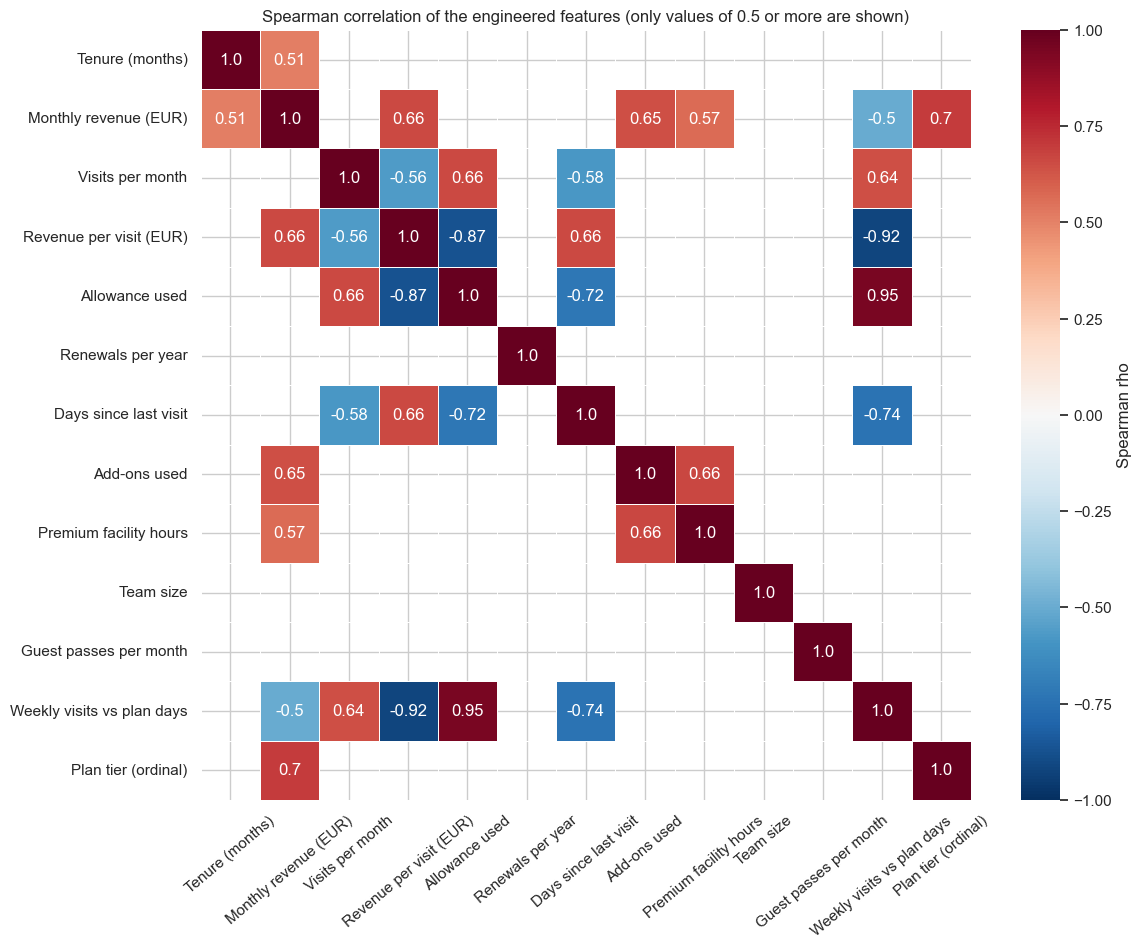

In [137]:
# Spearman matrix of the engineered features: which pairs move together in rank.
corr_engineered = analysis_data[engineered_numeric].corr(method="spearman")
corr_engineered.index = [chart_label(c) for c in corr_engineered.index]
corr_engineered.columns = [chart_label(c) for c in corr_engineered.columns]
weak_pairs = corr_engineered.abs() < 0.5
fig, ax = plt.subplots(figsize=(13, 10))
sns.heatmap(corr_engineered, mask=weak_pairs, annot=corr_engineered.round(2), fmt="", vmin=-1, vmax=1, center=0,
            square=True, linewidths=0.5, cmap=CORR_CMAP, ax=ax, cbar_kws={"label": "Spearman rho"})
ax.set_title("Spearman correlation of the engineered features (only values of 0.5 or more are shown)")
ax.tick_params(axis="x", rotation=40)
ax.tick_params(axis="y", rotation=0)
plt.show()

In [138]:
# The strongest links, written out as pairs so the duplicates are impossible to miss.
pair_list = []
for i, first in enumerate(engineered_numeric):
    for second in engineered_numeric[i + 1:]:
        rho = float(corr_engineered.loc[chart_label(first), chart_label(second)])
        pair_list.append({"pair": f"{first} ~ {second}", "spearman": round(rho, 3), "abs_spearman": round(abs(rho), 3)})
engineered_pairs = pd.DataFrame(pair_list).sort_values("abs_spearman", ascending=False)
print(engineered_pairs.head(8).to_string(index=False))
print(f"\n{int((engineered_pairs['abs_spearman'] >= 0.9).sum())} engineered pairs sit at 0.9 or above")
print("Reading: the duplicates are the feature and the raw column it was built from, as expected: monthly revenue")
print("with lifetime value, visit rate with total visits, renewal rate with renewals. The engineered version states")
print("the rate; the raw one states the level. Keeping both would count the same axis twice.")

                                      pair  spearman  abs_spearman
utilization_rate ~ visit_intensity_vs_plan     0.948         0.948
 value_per_visit ~ visit_intensity_vs_plan    -0.918         0.918
        value_per_visit ~ utilization_rate    -0.867         0.867
    recency_days ~ visit_intensity_vs_plan    -0.738         0.738
           utilization_rate ~ recency_days    -0.720         0.720
       monthly_revenue ~ plan_tier_ordinal     0.701         0.701
       n_addons_used ~ premium_hours_total     0.665         0.665
             visit_rate ~ utilization_rate     0.662         0.662

2 engineered pairs sit at 0.9 or above
Reading: the duplicates are the feature and the raw column it was built from, as expected: monthly revenue
with lifetime value, visit rate with total visits, renewal rate with renewals. The engineered version states
the rate; the raw one states the level. Keeping both would count the same axis twice.


### Redundancy: which features restate each other
The table is computed, not typed. Every pair of candidate columns is ranked by Spearman correlation; one threshold
decides the drop for all of them; and a stated priority says which column of a pair to keep. The pairs are read from
the strongest link downwards, and a column already resolved by a stronger pair is not touched again, so a column
nominated to keep can never be dropped by a later pair. Pairs that land in the band just below the threshold are
printed as edge cases with both columns kept, which is where the honest uncertainty belongs.

In [139]:
# The candidates and the priority. Lower priority number = the column to keep; a tie is broken by coverage.
REDUNDANCY_THRESHOLD = 0.95
NEAR_MISS_BAND = 0.90
feature_priority = {
    "n_colleagues_on_account": 1, "team_size": 2,
    "meeting_room_hours": 1, "event_space_hours": 1, "guest_passes_issued": 1, "premium_hours_total": 2,
    "avg_weekly_visits": 2, "visit_rate": 1,
    "lifetime_value": 1, "monthly_revenue": 2, "tenure_months": 1, "value_per_visit": 2,
    "total_visits": 1, "plan_days_per_week": 2, "visit_intensity_vs_plan": 1,
    "entitled_visits_last_period": 2, "utilization_rate": 1,
    "n_renewals": 1, "renewal_rate": 2, "n_addons_used": 1,
    "actual_visits_last_period": 3, "days_since_last_visit": 3, "age": 1, "recency_days": 1,
    "plan_tier_ordinal": 1, "guest_pass_rate": 2, "start_year_cohort": 1,
}
numeric_candidates = []
for column in feature_priority:
    if pd.to_numeric(analysis_data[column], errors="coerce").notna().any():
        numeric_candidates.append(column)
print(f"{len(numeric_candidates)} candidate columns enter the rank comparison: {', '.join(numeric_candidates)}")
print("Priority rule, applied identically to every pair: keep the column that separates more members or carries the")
print("clearer business meaning. A tie in priority is broken by coverage, so the column that places more members wins.")

27 candidate columns enter the rank comparison: n_colleagues_on_account, team_size, meeting_room_hours, event_space_hours, guest_passes_issued, premium_hours_total, avg_weekly_visits, visit_rate, lifetime_value, monthly_revenue, tenure_months, value_per_visit, total_visits, plan_days_per_week, visit_intensity_vs_plan, entitled_visits_last_period, utilization_rate, n_renewals, renewal_rate, n_addons_used, actual_visits_last_period, days_since_last_visit, age, recency_days, plan_tier_ordinal, guest_pass_rate, start_year_cohort
Priority rule, applied identically to every pair: keep the column that separates more members or carries the
clearer business meaning. A tie in priority is broken by coverage, so the column that places more members wins.


In [140]:
# Correlate every pair of candidates and keep the pairs that are close to repeating each other.
# recency_days and days_since_last_visit are the same quantity computed two ways (section 8), so that pair is
# skipped: its correlation is a property of the definition rather than a finding.
same_quantity_twice = [("recency_days", "days_since_last_visit")]
pair_rows = []
for i, first in enumerate(numeric_candidates):
    for second in numeric_candidates[i + 1:]:
        if (first, second) in same_quantity_twice or (second, first) in same_quantity_twice:
            continue
        pair = analysis_data[[first, second]].dropna()
        if len(pair) < 100:
            continue
        rho = float(pair.corr(method="spearman").iloc[0, 1])
        if abs(rho) >= NEAR_MISS_BAND:
            pair_rows.append({"first": first, "second": second, "n": len(pair), "spearman": round(rho, 4),
                              "abs_spearman": round(abs(rho), 4)})
all_pairs = pd.DataFrame(pair_rows).sort_values("abs_spearman", ascending=False)
print(all_pairs.to_string(index=False))
print(f"\n{len(all_pairs)} pairs sit at {NEAR_MISS_BAND} or above, the band worth deciding on")

                  first                    second     n  spearman  abs_spearman
n_colleagues_on_account                 team_size 15297    1.0000        1.0000
    guest_passes_issued           guest_pass_rate  8592    0.9976        0.9976
     plan_days_per_week         plan_tier_ordinal 15248    0.9930        0.9930
      avg_weekly_visits                visit_rate  9237    0.9846        0.9846
             visit_rate actual_visits_last_period  9237    0.9583        0.9583
visit_intensity_vs_plan          utilization_rate 15353    0.9478        0.9478
     meeting_room_hours       premium_hours_total 14136    0.9464        0.9464
         lifetime_value             tenure_months 12469    0.9396        0.9396
      avg_weekly_visits actual_visits_last_period 15450    0.9327        0.9327
        value_per_visit   visit_intensity_vs_plan 12429   -0.9179        0.9179

10 pairs sit at 0.9 or above, the band worth deciding on


In [141]:
# Turn the ranked pairs into keep or drop decisions, strongest pair first.
decisions = []
dropped_for_redundancy = []
for _, pair_row in all_pairs.iterrows():
    first = pair_row["first"]
    second = pair_row["second"]
    rho = pair_row["spearman"]
    if first in dropped_for_redundancy or second in dropped_for_redundancy:
        continue
    if feature_priority[first] < feature_priority[second]:
        keep, drop = first, second
    elif feature_priority[second] < feature_priority[first]:
        keep, drop = second, first
    else:
        keep_by_coverage = float(analysis_data[first].notna().mean()) >= float(analysis_data[second].notna().mean())
        keep, drop = (first, second) if keep_by_coverage else (second, first)
    if abs(rho) >= REDUNDANCY_THRESHOLD:
        dropped_for_redundancy.append(drop)
        decisions.append({"column_a": first, "column_b": second, "kept": keep, "dropped": drop,
                          "n": int(pair_row["n"]), "spearman": rho,
                          "decision": f"drop at the {REDUNDANCY_THRESHOLD} cut"})
    else:
        decisions.append({"column_a": first, "column_b": second, "kept": "both", "dropped": "none",
                          "n": int(pair_row["n"]), "spearman": rho,
                          "decision": f"edge case: at or above {NEAR_MISS_BAND} but below {REDUNDANCY_THRESHOLD}"})
redundancy = pd.DataFrame(decisions)
print(redundancy.to_string(index=False))

               column_a                  column_b                    kept                   dropped     n  spearman                                  decision
n_colleagues_on_account                 team_size n_colleagues_on_account                 team_size 15297    1.0000                      drop at the 0.95 cut
    guest_passes_issued           guest_pass_rate     guest_passes_issued           guest_pass_rate  8592    0.9976                      drop at the 0.95 cut
     plan_days_per_week         plan_tier_ordinal       plan_tier_ordinal        plan_days_per_week 15248    0.9930                      drop at the 0.95 cut
      avg_weekly_visits                visit_rate              visit_rate         avg_weekly_visits  9237    0.9846                      drop at the 0.95 cut
             visit_rate actual_visits_last_period              visit_rate actual_visits_last_period  9237    0.9583                      drop at the 0.95 cut
visit_intensity_vs_plan          utilization_rate   

In [142]:
print(f"threshold: an absolute rho of {REDUNDANCY_THRESHOLD} or more drops one column from the pair; between "
      f"{NEAR_MISS_BAND} and {REDUNDANCY_THRESHOLD} the pair is reported as an edge case and both columns are kept")
print(f"{len(dropped_for_redundancy)} columns nominated to drop: {', '.join(sorted(dropped_for_redundancy))}")
print("plan_tier_ordinal is kept over plan_days_per_week because the day count cannot separate dedicated desk from")
print("full time, while the tier code can. The recency pair above is excluded by design, since one column is the")
print("other recomputed with a stated anchor.")

threshold: an absolute rho of 0.95 or more drops one column from the pair; between 0.9 and 0.95 the pair is reported as an edge case and both columns are kept
5 columns nominated to drop: actual_visits_last_period, avg_weekly_visits, guest_pass_rate, plan_days_per_week, team_size
plan_tier_ordinal is kept over plan_days_per_week because the day count cannot separate dedicated desk from
full time, while the tier code can. The recency pair above is excluded by design, since one column is the
other recomputed with a stated anchor.


In [143]:
# The feature set that survives, and what each dropped column cost.
surviving_features = []
for column in engineered_numeric + ["start_year_cohort", "addon_mix"]:
    if column not in dropped_for_redundancy:
        surviving_features.append(column)
print("engineered features entering the hypothesis work:", ", ".join(surviving_features))
print(f"{len(surviving_features)} of {len(engineered_numeric) + 2} kept after the redundancy test")
for dropped_column in dropped_for_redundancy:
    pair_row = redundancy.loc[redundancy["dropped"] == dropped_column, ["kept", "spearman"]]
    if not pair_row.empty:
        print(f"  dropped {dropped_column}: kept {pair_row['kept'].iloc[0]} at rho = {pair_row['spearman'].iloc[0]}")
print("\nDropping these removes no information from the analysis: it removes a second copy of information the kept")
print("column already carries. The dropped ones stay in analysis_data, flagged and available for reporting.")

engineered features entering the hypothesis work: tenure_months, monthly_revenue, visit_rate, value_per_visit, utilization_rate, renewal_rate, recency_days, n_addons_used, premium_hours_total, visit_intensity_vs_plan, plan_tier_ordinal, start_year_cohort, addon_mix
13 of 15 kept after the redundancy test
  dropped team_size: kept n_colleagues_on_account at rho = 1.0
  dropped guest_pass_rate: kept guest_passes_issued at rho = 0.9976
  dropped plan_days_per_week: kept plan_tier_ordinal at rho = 0.993
  dropped avg_weekly_visits: kept visit_rate at rho = 0.9846
  dropped actual_visits_last_period: kept visit_rate at rho = 0.9583

Dropping these removes no information from the analysis: it removes a second copy of information the kept
column already carries. The dropped ones stay in analysis_data, flagged and available for reporting.


So what: the fifteen engineered features collapse into a smaller set that is not duplicated and not near-constant,
and that reduced set is what section 13 hands to Deliverable 2.

# 10. Anomaly screening
One diagnostic, and it uses only the fence rule already computed in section 5. A member is called unusual here when
they sit outside the ordinary range of one or more spread variables at the same time. The section counts how many
fences each member breaks and names the most extreme value in every variable. Nothing is scaled, nothing is modelled
and no member is removed: the point is to hand Deliverable 2 a list of the rows it has to decide about.

### What the count does and does not mean
The count answers one question only: on how many of the spread variables is this member outside the middle half of
the base? It is a summary of how the data is spread, not a measure of how interesting the member is, and it has three
limits worth saying out loud. It ignores members with a missing value on a variable, so a member with gaps can never
be called unusual there. It treats a value just past the fence the same as a value ten times past it. And a member
who is a heavy but genuine user of one service looks the same as a member whose record is broken.

In [144]:
# How many fences each member breaks, counted from the flags section 5 wrote.
fence_count = analysis_data["n_iqr_fences"]
count_rows = []
for value in sorted(fence_count.unique()):
    count_rows.append({"fences_broken": int(value), "members": int((fence_count == value).sum())})
fence_distribution = pd.DataFrame(count_rows).set_index("fences_broken")
fence_distribution["pct_of_members"] = (fence_distribution["members"] / len(analysis_data) * 100).round(1)
print(fence_distribution.to_string())
n_three_or_more = int((fence_count >= 3).sum())
print(f"\n{int((fence_count == 0).sum()):,} members break no fence at all "
      f"({(fence_count == 0).mean():.1%} of the base)")
print(f"{n_three_or_more:,} members break three or more ({fence_count.ge(3).mean():.1%}), and the busiest breaks "
      f"{int(fence_count.max())}")

               members  pct_of_members
fences_broken                         
0                10771            69.7
1                 3693            23.9
2                  665             4.3
3                  193             1.2
4                  114             0.7
5                   13             0.1
6                    1             0.0

10,771 members break no fence at all (69.7% of the base)
321 members break three or more (2.1%), and the busiest breaks 6


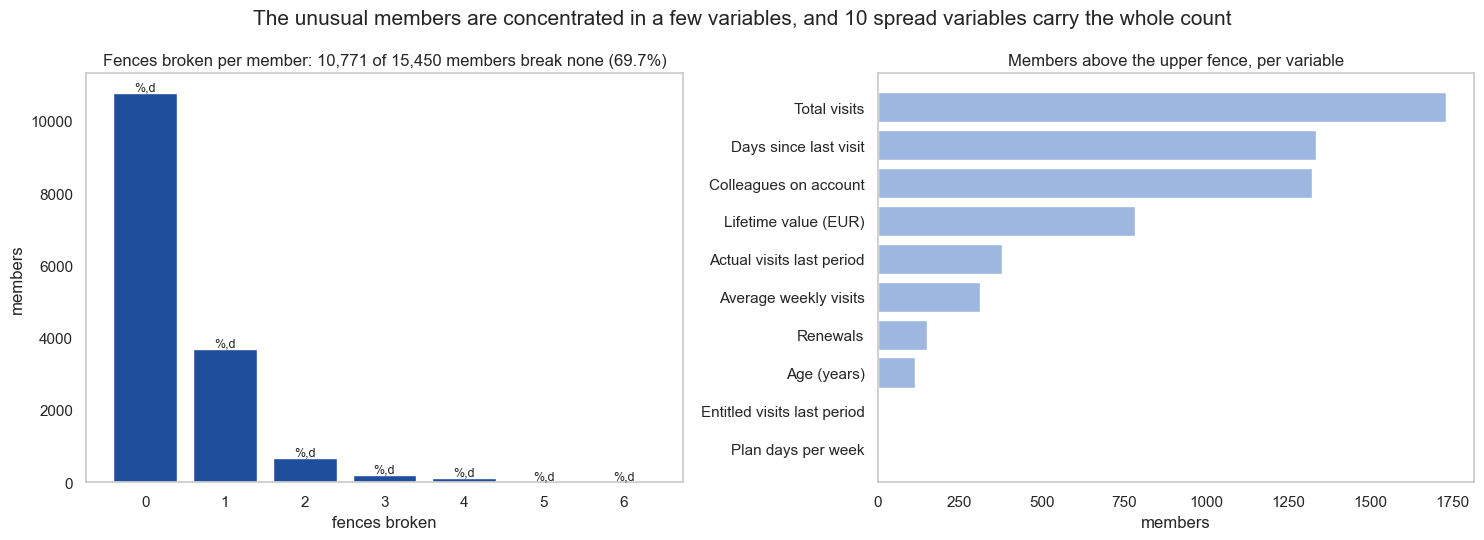

In [145]:
# The same distribution, plus which variables contribute the members above the upper fence.
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
bars = axes[0].bar([str(v) for v in fence_distribution.index], fence_distribution["members"], color=BLUE)
axes[0].bar_label(bars, fmt="%,d", fontsize=9)
axes[0].set(title=f"Fences broken per member: {int((fence_count == 0).sum()):,} of {len(analysis_data):,} members "
                  f"break none ({(fence_count == 0).mean():.1%})",
            xlabel="fences broken", ylabel="members")
axes[0].grid(False)
outside = fences["n_above"].sort_values()
axes[1].barh([chart_label(c) for c in outside.index], outside.values, color=LIGHT_BLUE)
axes[1].set(title="Members above the upper fence, per variable", xlabel="members", ylabel="")
axes[1].grid(False)
fig.suptitle(f"The unusual members are concentrated in a few variables, and {len(fence_features)} spread variables "
             "carry the whole count", fontsize=15)
fig.tight_layout()
plt.show()

In [146]:
# The most extreme values in each spread variable: the five largest, with the fence they are measured against.
extreme_rows = []
for feature in fence_features:
    upper = float(fences.loc[feature, "upper_fence"])
    top = analysis_data.nlargest(5, feature)
    for _, member_row in top.iterrows():
        extreme_rows.append({"variable": feature, "member_id": member_row["member_id"],
                             "value": member_row[feature], "upper_fence": round(upper, 2),
                             "times_the_upper_fence": round(float(member_row[feature]) / upper, 1) if upper > 0 else None,
                             "plan_tier": member_row["plan_tier"], "status": member_row["status"]})
extremes = pd.DataFrame(extreme_rows)
print(extremes.to_string(index=False))

                   variable member_id      value  upper_fence  times_the_upper_fence      plan_tier status
                        age  CW008375      93.00        56.50                    1.6 dedicated_desk  ended
                        age  CW008593      93.00        56.50                    1.6       hot_desk  ended
                        age  CW008678      92.00        56.50                    1.6           flex  ended
                        age  CW010731      91.00        56.50                    1.6       hot_desk  ended
                        age  CW003876      83.00        56.50                    1.5       hot_desk  ended
    n_colleagues_on_account  CW005363       9.00         2.50                    3.6       hot_desk  ended
    n_colleagues_on_account  CW006458       8.00         2.50                    3.2           flex active
    n_colleagues_on_account  CW009456       8.00         2.50                    3.2           flex  ended
    n_colleagues_on_account  CW001356

In [147]:
# The variables whose own upper fence sits at or below zero, since a multiple of it cannot be read.
degenerate_fences = fences.loc[fences["upper_fence"] <= 0, ["Q1", "median", "Q3", "upper_fence", "n_above"]]
print(f"{len(degenerate_fences)} of the {len(fence_features)} spread variables have an upper fence at or below zero")
if not degenerate_fences.empty:
    print(degenerate_fences.to_string())
print("That can happen when the middle half of a column sits on one value: the fence then lands right on top of it")
print("and every larger value counts as outside, so the measure stops meaning 'unusual' and starts meaning 'used it")
print("at all'. The three zero-inflated usage columns have exactly that shape, which is why section 5 keeps them out")
print("of the fence rule and describes them with a presence table instead.")

0 of the 10 spread variables have an upper fence at or below zero
That can happen when the middle half of a column sits on one value: the fence then lands right on top of it
and every larger value counts as outside, so the measure stops meaning 'unusual' and starts meaning 'used it
at all'. The three zero-inflated usage columns have exactly that shape, which is why section 5 keeps them out
of the fence rule and describes them with a presence table instead.


In [148]:
# Does a high fence count mean a noisy record? Tested directly rather than assumed.
flag_only = [c for c in flag_columns if c not in fence_flag_columns]
issue_count = analysis_data[flag_only].fillna(False).astype(bool).sum(axis=1)
analysis_data["n_data_quality_flags"] = issue_count
many_fences = fence_count >= 3
few_fences = fence_count == 0
coherence_flags = ["flag_renewals_exceed_tenure", "flag_visits_exceed_entitlement", "flag_no_entitlement_with_visits"]
impossible_flags = ["flag_age_invalid", "flag_days_since_last_visit_invalid", "flag_plan_days_invalid",
                    "flag_n_colleagues_placeholder"]
comparison_frame = pd.DataFrame({
    "members": [int(many_fences.sum()), int(few_fences.sum())],
    "mean_quality_flags": [round(float(issue_count[many_fences].mean()), 2), round(float(issue_count[few_fences].mean()), 2)],
    "pct_with_a_contradiction": [round(float(analysis_data[coherence_flags].any(axis=1)[many_fences].mean()) * 100, 1),
                                 round(float(analysis_data[coherence_flags].any(axis=1)[few_fences].mean()) * 100, 1)],
    "pct_with_an_impossible_value": [round(float(analysis_data[impossible_flags].any(axis=1)[many_fences].mean()) * 100, 1),
                                     round(float(analysis_data[impossible_flags].any(axis=1)[few_fences].mean()) * 100, 1)],
    "median_lifetime_value": [round(float(analysis_data.loc[many_fences, "lifetime_value"].median()), 0),
                              round(float(analysis_data.loc[few_fences, "lifetime_value"].median()), 0)],
}, index=["3 or more fences", "no fence broken"])
print(comparison_frame.to_string())

                  members  mean_quality_flags  pct_with_a_contradiction  pct_with_an_impossible_value  median_lifetime_value
3 or more fences      321                0.30                       0.0                           9.0                18457.0
no fence broken     10771                0.38                       0.2                          15.2                  588.0


In [149]:
# What that comparison says, read from the two rows above rather than from an expectation.
flag_gap = (comparison_frame.loc["3 or more fences", "pct_with_an_impossible_value"]
            - comparison_frame.loc["no fence broken", "pct_with_an_impossible_value"])
print(f"members breaking three or more fences carry an impossible value or a placeholder {flag_gap:+.1f} percentage")
print("points compared with members breaking none, so the fence count does not pick out bad records at all.")
print("The reason is in the handling: a value judged impossible was set to missing in section 4, and a missing value")
print("cannot fall outside a fence. What the count finds instead are members with genuinely extreme recorded values,")
print(f"and their median lifetime value is {comparison_frame.loc['3 or more fences', 'median_lifetime_value']:,.0f} EUR")
print(f"against {comparison_frame.loc['no fence broken', 'median_lifetime_value']:,.0f} EUR for the members breaking")
print("none. That is a business difference, not a data error, which is why the count is reported as a diagnostic")
print("here and kept out of the behavioural comparison in section 12.")

members breaking three or more fences carry an impossible value or a placeholder -6.2 percentage
points compared with members breaking none, so the fence count does not pick out bad records at all.
The reason is in the handling: a value judged impossible was set to missing in section 4, and a missing value
cannot fall outside a fence. What the count finds instead are members with genuinely extreme recorded values,
and their median lifetime value is 18,457 EUR
against 588 EUR for the members breaking
none. That is a business difference, not a data error, which is why the count is reported as a diagnostic
here and kept out of the behavioural comparison in section 12.


So what: the fence count names a small, inspectable set of extreme rows rather than a new kind of customer, so
Deliverable 2 can decide about scaling and about the EUR 1M members with the list in front of it instead of finding
them inside a fitted grouping.

# 11. Clustering-reliability risks
Each data-quality issue is connected to the way it could distort a later grouping. Two rules govern the register: the
unit is the **member**, so a row counts once however many columns it touches, and the ranking is by documented impact
first and by the number of members second.

One thing is deliberately not in the register: the fact that the file mixes active members with members whose
membership has ended. Both populations are real and correctly recorded, so that is a structural choice for section 12
to handle, not a defect to mitigate.

In [150]:
# The issue flags the register will count: every flag column except the section 5 fence flags, which are a spread
# summary rather than a record problem.
issue_columns = []
for column in analysis_data.columns:
    if column.startswith("flag_") and column not in fence_flag_columns:
        issue_columns.append(column)
issue_matrix = analysis_data[issue_columns].fillna(False).astype(bool)
members_with_any_issue = issue_matrix.any(axis=1)
issue_count_per_member = issue_matrix.sum(axis=1)
print(f"issues tracked as flags: {len(issue_columns)}")
print(f"members carrying at least one issue: {int(members_with_any_issue.sum()):,} ({members_with_any_issue.mean():.1%})")
print(f"members carrying two or more: {int((issue_count_per_member >= 2).sum()):,} "
      f"({(issue_count_per_member >= 2).mean():.1%})")
print(f"members carrying four or more: {int((issue_count_per_member >= 4).sum()):,} "
      f"({(issue_count_per_member >= 4).mean():.1%})")
print(f"the busiest member carries {int(issue_count_per_member.max())} flags")

issues tracked as flags: 25
members carrying at least one issue: 3,391 (21.9%)
members carrying two or more: 1,661 (10.8%)
members carrying four or more: 184 (1.2%)
the busiest member carries 7 flags


In [151]:
# Why the register cannot simply add its percentages up: the same member appears in several rows.
print(f"sum of the individual issue counts: {int(issue_count_per_member.sum()):,} against "
      f"{int(members_with_any_issue.sum()):,} distinct members")
heavy_tail_union = (analysis_data["flag_ltv_extreme"].fillna(False)
                    | analysis_data["flag_visits_above_daily_max"].fillna(False))
contradiction_union = (analysis_data["flag_renewals_exceed_tenure"].fillna(False)
                       | analysis_data["flag_visits_exceed_entitlement"].fillna(False)
                       | analysis_data["flag_no_entitlement_with_visits"].fillna(False))
zero_inflated_any_zero = (analysis_data[zero_inflated_features] == 0).any(axis=1)
print(f"heavy-tail overlap: {n_suspects} lifetime-value suspects + {n_visits_above_daily_max} visit-rate suspects "
      f"= {int(heavy_tail_union.sum()):,} distinct members")
print(f"contradiction overlap: renewals {n_renewal_flag}, visits above entitlement {n_over_entitled}, "
      f"zero entitlement with visits {n_zero_entitled} = {int(contradiction_union.sum()):,} distinct members")
print(f"members with at least one zero usage value: {int(zero_inflated_any_zero.sum()):,} "
      f"({zero_inflated_any_zero.mean():.1%})")

sum of the individual issue counts: 5,699 against 3,391 distinct members
heavy-tail overlap: 17 lifetime-value suspects + 8 visit-rate suspects = 24 distinct members
contradiction overlap: renewals 15, visits above entitlement 8, zero entitlement with visits 8 = 23 distinct members
members with at least one zero usage value: 14,783 (95.7%)


In [152]:
# The two date issues counted separately, since one is how the date was written and the other is what it means.
n_date_format_rows = int(analysis_data["flag_date_format_dmy"].sum())
both_date_issues = analysis_data["flag_date_format_dmy"] & analysis_data["is_active"]
print(f"date-format rows: {n_date_format_rows:,} | active-sentinel rows: {int(analysis_data['is_active'].sum()):,} "
      f"| rows carrying both: {int(both_date_issues.sum()):,} ({both_date_issues.mean():.1%})")
print("They stay as two register entries, and the overlap is printed here so neither one hides the other.")

date-format rows: 637 | active-sentinel rows: 3,954 | rows carrying both: 176 (1.1%)
They stay as two register entries, and the overlap is printed here so neither one hides the other.


In [153]:
# The register: one row per issue, counted in members, with the impact score that decides the order.
risk_rows = [
    {"issue": "Heavy tail in lifetime value or visit rate", "members": int(heavy_tail_union.sum()),
     "impact": 3, "effect": "one variable dominates every distance, so a grouping becomes a set of revenue bands",
     "mitigation": "the value axis is reported on log scales; the suspect rows are flagged and named in section 4.9",
     "residual": "the thousand-fold scale-error hypothesis is still open, and if it holds the value axis changes shape"},
    {"issue": "Missing lifetime value after placeholder treatment", "members": n_ltv_missing,
     "impact": 3, "effect": "a member without a value is placed by their other features only and drifts to whichever group is nearest",
     "mitigation": "kept missing with a flag; every value feature is computed on the rows that carry a value",
     "residual": "the missing share is not uniform across plans or status (section 7), so the drift is biased, not random"},
    {"issue": "Zero-inflated usage columns", "members": int(zero_inflated_any_zero.sum()),
     "impact": 3, "effect": "a distance on a column that is zero for most members measures service presence twice and invents a group of non-users",
     "mitigation": "excluded from the fences and from the diagnostic; presence is carried by the add-on flags, intensity among users only",
     "residual": "intensity among users is still a tail, and only the users can be compared on it"},
]
print(f"{len(risk_rows)} high-impact entries written, covering the value axis, the gaps and the zero-inflated columns")

3 high-impact entries written, covering the value axis, the gaps and the zero-inflated columns


In [154]:
# The lower-impact entries, added to the same table.
risk_rows += [
    {"issue": "Placeholder and impossible codes (999, -1, 0 and 9 days, ages)",
     "members": int((analysis_data["flag_days_since_last_visit_invalid"] | analysis_data["flag_plan_days_invalid"]
                      | analysis_data["flag_n_colleagues_placeholder"] | analysis_data["flag_age_invalid"]).sum()),
     "impact": 2, "effect": "a sentinel read as a real number gives a member a position they never occupied",
     "mitigation": "converted to missing with one flag per rule; the true plan days are documented as recoverable (section 4.7)",
     "residual": "why ACDC wrote the placeholder is unknown, so the recovered value is documented and not filled in"},
    {"issue": "Extreme meeting-room hours beyond the capacity of the window", "members": n_above_working,
     "impact": 2, "effect": "one impossible hour figure can separate a member from the whole base on its own",
     "mitigation": "kept with a flag and reported in the decision table of section 4.9",
     "residual": "the unit of the column is not documented, so 'hours' may not mean hours"},
    {"issue": "Fields that contradict each other", "members": int(contradiction_union.sum()),
     "impact": 2, "effect": "a ratio built on a contradicted denominator becomes unbounded or undefined",
     "mitigation": "guarded denominators, flag kept, ratio defined only where the denominator is valid",
     "residual": "those members carry no allowance signal and are placed by tenure and revenue alone"},
    {"issue": "Category spelling variants", "members": n_variants_rows,
     "impact": 1, "effect": "unmapped variants would split one category into several groups of the same members",
     "mitigation": "explicit mapping with the missing counts preserved, checked per column in section 4.2",
     "residual": "the mapping assumed the annex label set; a new variant in a later extract would need adding"},
    {"issue": "Two date formats in the same columns", "members": n_dmy_rows,
     "impact": 1, "effect": "a misread format moves a member along the lifecycle axis, and tenure feeds every rate",
     "mitigation": "day-first proven from the data before parsing, and the rows carry flag_date_format_dmy",
     "residual": "the proof is statistical; a slash date with a day below 12 stays ambiguous"},
]
print(f"register complete: {len(risk_rows)} issues, impacts from 3 (distorts every axis) down to 1 (cosmetic)")

register complete: 8 issues, impacts from 3 (distorts every axis) down to 1 (cosmetic)


In [155]:
# Sort the register by impact and then by the number of members.
risks = pd.DataFrame(risk_rows)
risks["pct_of_members"] = (risks["members"] / len(analysis_data) * 100).round(1)
risks = risks.sort_values(["impact", "members"], ascending=[False, False]).reset_index(drop=True)
risks.insert(0, "rank", risks.index + 1)
print(risks[["rank", "issue", "members", "pct_of_members", "impact"]].to_string(index=False))
print(f"\n{len(risks)} registered risks. Impact 3 distorts every axis, 2 distorts one axis, 1 is cosmetic.")
print(f"largest by member count: {risks.sort_values('members', ascending=False)['issue'].iloc[0]}")

 rank                                                          issue  members  pct_of_members  impact
    1                                    Zero-inflated usage columns    14783            95.7       3
    2             Missing lifetime value after placeholder treatment     2864            18.5       3
    3                     Heavy tail in lifetime value or visit rate       24             0.2       3
    4 Placeholder and impossible codes (999, -1, 0 and 9 days, ages)     2060            13.3       2
    5                              Fields that contradict each other       23             0.1       2
    6   Extreme meeting-room hours beyond the capacity of the window        6             0.0       2
    7                                     Category spelling variants     3238            21.0       1
    8                           Two date formats in the same columns      637             4.1       1

8 registered risks. Impact 3 distorts every axis, 2 distorts one axis, 1 is cosme

In [156]:
# The full wording behind each rank: what the issue does, what we did, and what is still unresolved.
for _, row in risks.iterrows():
    print(f"[{int(row['rank'])}] {row['issue']}  ({row['members']:,} members, {row['pct_of_members']}%)")
    print(f"    effect     : {row['effect']}")
    print(f"    mitigation : {row['mitigation']}")
    print(f"    residual   : {row['residual']}")

[1] Zero-inflated usage columns  (14,783 members, 95.7%)
    effect     : a distance on a column that is zero for most members measures service presence twice and invents a group of non-users
    mitigation : excluded from the fences and from the diagnostic; presence is carried by the add-on flags, intensity among users only
    residual   : intensity among users is still a tail, and only the users can be compared on it
[2] Missing lifetime value after placeholder treatment  (2,864 members, 18.5%)
    effect     : a member without a value is placed by their other features only and drifts to whichever group is nearest
    mitigation : kept missing with a flag; every value feature is computed on the rows that carry a value
    residual   : the missing share is not uniform across plans or status (section 7), so the drift is biased, not random
[3] Heavy tail in lifetime value or visit rate  (24 members, 0.2%)
    effect     : one variable dominates every distance, so a grouping becomes a s

In [157]:
# One figure for the register: how many members each issue touches, with the date issues kept apart.
issue_sizes = pd.DataFrame({
    "members": [n_ltv_missing, int(heavy_tail_union.sum()), n_dmy_rows, n_active, n_variants_rows,
                n_age_invalid, int(contradiction_union.sum()), n_above_working],
    "impact": [3, 3, 1, 2, 1, 2, 2, 2],
}, index=["lifetime value missing", "heavy-tail value or visits", "DD/MM date format", "active sentinel",
          "category variants", "impossible age", "contradicting fields", "impossible meeting hours"])
issue_sizes = issue_sizes.sort_values("members")
print(issue_sizes.to_string())

                            members  impact
impossible meeting hours          6       2
contradicting fields             23       2
heavy-tail value or visits       24       3
impossible age                  143       2
DD/MM date format               637       1
lifetime value missing         2864       3
category variants              3238       1
active sentinel                3954       2


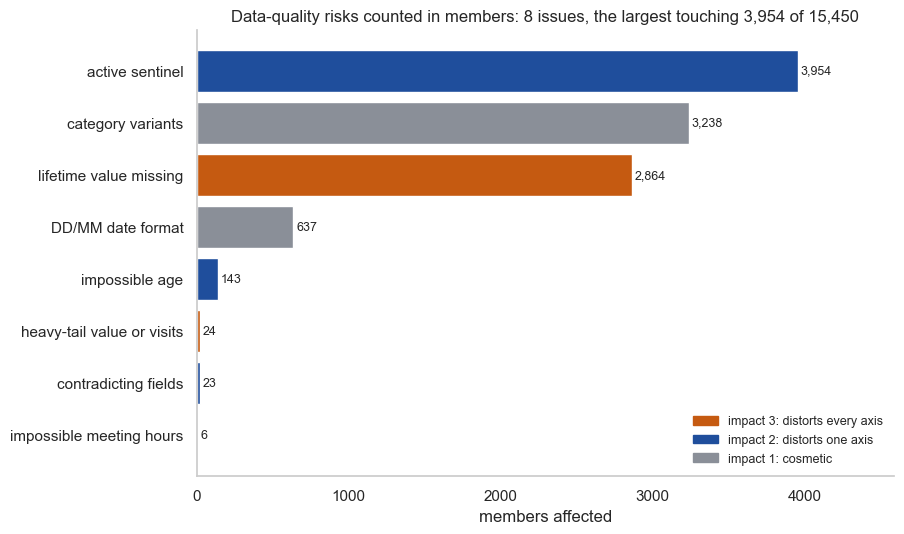

The bars are counts of members, so they overlap: the first cell of this section reports by how much.


In [158]:
# The same counts as a chart, coloured by the impact score.
impact_colors = {3: ACCENT, 2: BLUE, 1: GRAY}
fig, ax = plt.subplots(figsize=(9, 0.5 * len(issue_sizes) + 1.8))
bars = ax.barh(range(len(issue_sizes)), issue_sizes["members"],
               color=[impact_colors[int(i)] for i in issue_sizes["impact"]])
ax.set_yticks(range(len(issue_sizes)), issue_sizes.index)
ax.bar_label(bars, labels=[f"{int(value):,}" for value in issue_sizes["members"]], fontsize=9, padding=2)
ax.set(xlabel="members affected", xlim=(0, issue_sizes["members"].max() * 1.16),
       title=f"Data-quality risks counted in members: {len(issue_sizes)} issues, "
             f"the largest touching {issue_sizes['members'].max():,} of {len(analysis_data):,}")
handles = [plt.Rectangle((0, 0), 1, 1, color=impact_colors[k]) for k in [3, 2, 1]]
ax.legend(handles, ["impact 3: distorts every axis", "impact 2: distorts one axis", "impact 1: cosmetic"],
          fontsize=9, loc="lower right", frameon=False)
ax.grid(False)
sns.despine()
plt.show()
print("The bars are counts of members, so they overlap: the first cell of this section reports by how much.")

**Reading the register.** A missing value makes a member hard to place on one axis. A placeholder read as a real
number gives a member a position they never occupied, and can gather all such members into a group of its own.
Keeping the flags, and keeping the issues counted in members, is what lets Deliverable 2 check whether a group it
finds is behaviour or bookkeeping.

So what: three issues can invent a group on their own, so the flags travel with the rows and Deliverable 2 checks a
candidate group against this list before naming it.

# 12. Behavioural signals and group hypotheses
We use the observed patterns in value, usage and lifecycle to propose groups that a clustering in Deliverable 2 can
test. The rule counts below are descriptive: they are not cluster assignments, and no clustering is run in this
notebook. Status is used as an explicit stratification throughout, because the file mixes members whose membership
has run with members whose membership is still open (section 4.5).

In [159]:
# Median behaviour profile by plan tier and membership status, built one row at a time.
profile_columns = ["monthly_revenue", "visit_rate", "utilization_rate", "visit_intensity_vs_plan", "tenure_months",
                   "n_addons_used", "team_size", "recency_days"]
profile_rows = []
for tier in tier_order:
    for group_value in ["active", "ended"]:
        in_cell = (analysis_data["plan_tier"] == tier) & (analysis_data["status"] == group_value)
        row = {"plan_tier": tier, "status": group_value, "members": int(in_cell.sum())}
        for column in profile_columns:
            row[column] = round(float(analysis_data.loc[in_cell, column].median()), 2)
        profile_rows.append(row)
behaviour_profile = pd.DataFrame(profile_rows).set_index(["plan_tier", "status"])
print(behaviour_profile.to_string())

                       members  monthly_revenue  visit_rate  utilization_rate  visit_intensity_vs_plan  tenure_months  n_addons_used  team_size  recency_days
plan_tier      status                                                                                                                                        
hot_desk       active      696           132.15        8.07              0.52                     0.52           1.26            1.0        1.0           9.0
               ended      4516           138.27        7.99              0.46                     0.48           2.83            1.0        1.0          19.0
flex           active     1104           195.01        0.84              0.38                     0.38           2.60            1.0        1.0          16.0
               ended      4345           213.02        9.97              0.61                     0.65           9.10            1.0        1.0          10.0
dedicated_desk active      876           374.92     

In [160]:
# Which behaviour column separates the two statuses most inside the same tier? The gap is read in the column's own units.
gap_rows = []
for column in profile_columns:
    gaps = []
    for tier in tier_order:
        active_median = behaviour_profile.loc[(tier, "active"), column]
        ended_median = behaviour_profile.loc[(tier, "ended"), column]
        gaps.append(abs(active_median - ended_median))
    gap_rows.append({"column": column, "mean_abs_gap_within_tier": round(float(np.mean(gaps)), 2),
                     "largest_tier_gap": round(float(np.max(gaps)), 2)})
status_gaps = pd.DataFrame(gap_rows).set_index("column").sort_values("mean_abs_gap_within_tier", ascending=False)
print(status_gaps.to_string())
print("\nRead across each pair of rows in the table above: the same plan behaves differently depending on whether the")
print(f"membership is still open. The behavioural column that separates them most, on average inside a tier, is "
      f"{status_gaps.index[0]}.")

                         mean_abs_gap_within_tier  largest_tier_gap
column                                                             
recency_days                                58.70            139.50
monthly_revenue                             24.93             56.39
visit_rate                                   8.20             17.09
tenure_months                                5.20              9.97
n_addons_used                                0.40              2.00
visit_intensity_vs_plan                      0.34              0.78
utilization_rate                             0.32              0.77
team_size                                    0.00              0.00

Read across each pair of rows in the table above: the same plan behaves differently depending on whether the
membership is still open. The behavioural column that separates them most, on average inside a tier, is recency_days.


In [161]:
# The monthly-revenue band each plan tier actually occupies.
band_rows = []
for tier in tier_order:
    values = analysis_data.loc[analysis_data["plan_tier"] == tier, "monthly_revenue"].dropna()
    band_rows.append({"plan_tier": tier, "members": int(len(values)),
                      "q25": round(float(values.quantile(0.25)), 0),
                      "median": round(float(values.median()), 0),
                      "q75": round(float(values.quantile(0.75)), 0)})
bands = pd.DataFrame(band_rows).set_index("plan_tier")
bands["iqr"] = bands["q75"] - bands["q25"]
print("tiers in the documented commitment order:")
print(bands.to_string())

tiers in the documented commitment order:
                members    q25  median    q75   iqr
plan_tier                                          
hot_desk           1744  128.0   138.0  183.0  55.0
flex               2650  191.0   210.0  241.0  50.0
dedicated_desk     1117  373.0   406.0  449.0  76.0
full_time          1377  296.0   320.0  371.0  75.0
private_office      447  683.0   703.0  729.0  46.0


In [162]:
# How many distinct revenue levels the five tiers actually form.
bands_sorted = bands.sort_values("median")
print("the same tiers sorted by median monthly revenue, which is the order the pairwise test is valid in:")
print(bands_sorted.to_string())
separated_pairs = []
for position in range(len(bands_sorted) - 1):
    lower_row = bands_sorted.iloc[position]
    higher_row = bands_sorted.iloc[position + 1]
    separated_pairs.append(bool(higher_row["q25"] > lower_row["q75"]))
n_separated = int(sum(separated_pairs))
revenue_levels = 1 + n_separated
expected_cluster_min, expected_cluster_max = revenue_levels - 1, revenue_levels + 1
print(f"\nadjacent pairs whose middle halves do not overlap: {n_separated} of {len(separated_pairs)}")
print(f"-> {revenue_levels} separable monthly-revenue levels")
print(f"documented order and realised revenue order agree: {bands_sorted.index.tolist() == tier_order}")

the same tiers sorted by median monthly revenue, which is the order the pairwise test is valid in:
                members    q25  median    q75   iqr
plan_tier                                          
hot_desk           1744  128.0   138.0  183.0  55.0
flex               2650  191.0   210.0  241.0  50.0
full_time          1377  296.0   320.0  371.0  75.0
dedicated_desk     1117  373.0   406.0  449.0  76.0
private_office      447  683.0   703.0  729.0  46.0

adjacent pairs whose middle halves do not overlap: 4 of 4
-> 5 separable monthly-revenue levels
documented order and realised revenue order agree: False


In [163]:
# Where the documented ladder and the realised money disagree.
inversions = []
for position in range(len(tier_order) - 1):
    lower_tier = tier_order[position]
    higher_tier = tier_order[position + 1]
    if bands.loc[higher_tier, "median"] < bands.loc[lower_tier, "median"]:
        inversions.append((lower_tier, higher_tier))
for lower_tier, higher_tier in inversions:
    print(f"INVERSION: {higher_tier} (documented above {lower_tier}) realises a median of "
          f"{bands.loc[higher_tier, 'median']:,.0f} EUR per month against "
          f"{bands.loc[lower_tier, 'median']:,.0f} for {lower_tier}")
print(f"\n{len(inversions)} inversion(s) found, so the annex ladder orders access, not price")

INVERSION: full_time (documented above dedicated_desk) realises a median of 320 EUR per month against 406 for dedicated_desk

1 inversion(s) found, so the annex ladder orders access, not price


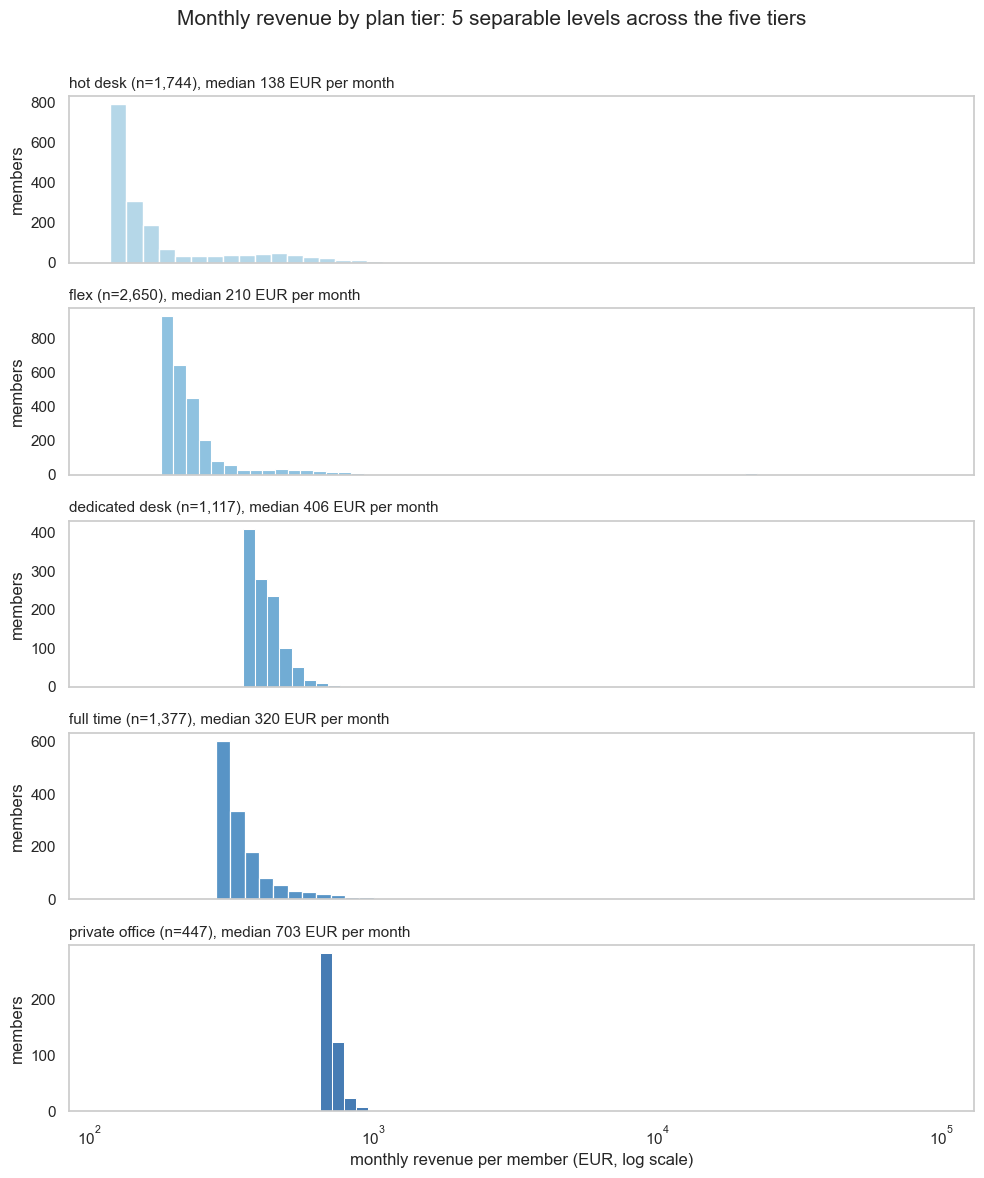

In [164]:
# Monthly revenue per member, one panel per tier, so the overlap between the tiers is visible rather than asserted.
revenue_frame = analysis_data[["monthly_revenue", "plan_tier"]].dropna()
fig, axes = plt.subplots(5, 1, figsize=(10, 12), sharex=True)
for ax, tier in zip(axes, tier_order):
    values = revenue_frame.loc[revenue_frame["plan_tier"] == tier, "monthly_revenue"]
    sns.histplot(values, bins=50, log_scale=True, color=TIER_COLORS[tier], ax=ax)
    ax.set(xlabel="", ylabel="members")
    ax.set_title(f"{tier.replace('_', ' ')} (n={len(values):,}), median "
                 f"{bands.loc[tier, 'median']:,.0f} EUR per month", fontsize=11, loc="left")
    ax.grid(False)
axes[-1].set_xlabel("monthly revenue per member (EUR, log scale)")
fig.suptitle(f"Monthly revenue by plan tier: {revenue_levels} separable levels across the five tiers", fontsize=15)
fig.tight_layout(rect=(0, 0, 1, 0.97))
plt.show()

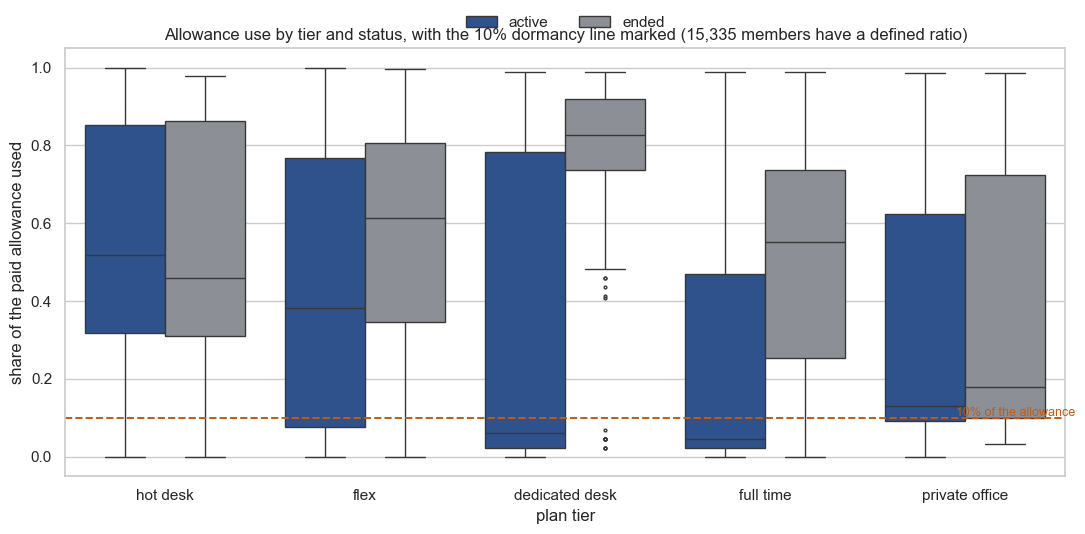

members with no defined allowance ratio: 10 (zero entitlement or missing values)


In [165]:
# Allowance use by plan tier and status: the behavioural axis the plan itself cannot express.
utilization_frame = analysis_data[["utilization_rate", "plan_tier", "status"]].dropna()
fig, ax = plt.subplots(figsize=(11, 5.5))
sns.boxplot(data=utilization_frame, x="plan_tier", y="utilization_rate", hue="status", order=tier_order,
            hue_order=["active", "ended"], palette={"active": BLUE, "ended": GRAY}, fliersize=2, ax=ax)
ax.axhline(0.10, color=ACCENT, linestyle="--", linewidth=1.4)
ax.text(len(tier_order) - 0.45, 0.105, "10% of the allowance", color=ACCENT, fontsize=9, ha="right")
ax.set(xlabel="plan tier", ylabel="share of the paid allowance used",
       title=f"Allowance use by tier and status, with the 10% dormancy line marked "
             f"({len(utilization_frame):,} members have a defined ratio)")
ax.set_xticks(ax.get_xticks())
ax.set_xticklabels([t.get_text().replace("_", " ") for t in ax.get_xticklabels()])
ax.legend(title="", loc="lower center", bbox_to_anchor=(0.5, 1.01), ncol=2, frameon=False)
fig.tight_layout()
plt.show()
print(f"members with no defined allowance ratio: {int(analysis_data['utilization_rate'].isna().sum()):,} "
      "(zero entitlement or missing values)")

In [166]:
# The dormant-payer pattern: active members on a committed plan who use almost none of what they pay for.
desk_tiers = ["dedicated_desk", "full_time"]
active_desk = analysis_data["is_active"] & analysis_data["plan_tier"].isin(desk_tiers)
ended_desk = ~analysis_data["is_active"] & analysis_data["plan_tier"].isin(desk_tiers)
valid_utilization = analysis_data["utilization_rate"].notna()
dormant = active_desk & (analysis_data["utilization_rate"] < 0.10)
n_active_desk_valid = int((active_desk & valid_utilization).sum())
n_dormant = int(dormant.sum())
dormant_share = n_dormant / n_active_desk_valid * 100
ended_desk_low_util = int((ended_desk & (analysis_data["utilization_rate"] < 0.10)).sum()) / int((ended_desk & valid_utilization).sum()) * 100
dormant_recency = float(analysis_data.loc[dormant, "recency_days"].median())
other_active_recency = float(analysis_data.loc[analysis_data["is_active"] & ~dormant, "recency_days"].median())
dormant_monthly_revenue = float(analysis_data.loc[dormant, "monthly_revenue"].sum())
total_monthly_revenue = float(analysis_data["monthly_revenue"].sum())
print(f"active members on the committed plans: {int(active_desk.sum()):,} "
      f"({n_active_desk_valid:,} with a defined allowance ratio)")
print(f"of those, {n_dormant:,} use under 10% of their allowance = {dormant_share:.0f}%")
print(f"the same rule on ended committed members: {ended_desk_low_util:.0f}%")
print(f"median days since last visit: dormant {dormant_recency:.0f} vs other active members {other_active_recency:.0f}")
print(f"monthly revenue sitting behind the dormant group: {dormant_monthly_revenue:,.0f} EUR = "
      f"{dormant_monthly_revenue / total_monthly_revenue * 100:.1f}% of recorded monthly revenue")
print("Limitation the data cannot settle: the extract cannot tell whether these members are absent or simply not")
print("using their badge. ACDC has to confirm what feeds last_badge_swipe before this group is used for retention.")

active members on the committed plans: 1,806 (1,804 with a defined allowance ratio)
of those, 1,112 use under 10% of their allowance = 62%
the same rule on ended committed members: 2%
median days since last visit: dormant 195 vs other active members 8
monthly revenue sitting behind the dormant group: 327,728 EUR = 8.1% of recorded monthly revenue
Limitation the data cannot settle: the extract cannot tell whether these members are absent or simply not
using their badge. ACDC has to confirm what feeds last_badge_swipe before this group is used for retention.


### Which features actually separate behaviour
The comparison is made **inside** each plan tier: active members are measured against ended members who bought the
same plan. Pooling the tiers would simply rediscover the price list, which is a plan and not a behaviour. The section
5 fence count is deliberately not in the candidate list, because it summarises how a column is spread rather than what
the member did.

**The measure, in plain words.** For a feature and a tier, take the median of the active members and the median of
the ended members, subtract them, and express the gap as a percentage of that tier's own IQR. A reading of 100 means
the two medians sit one full middle-half-width apart, which is a large difference for that tier; 10 means they are
almost on top of each other. A feature whose values are identical inside a tier has an IQR of zero, so the percentage
cannot be computed there and the tier is skipped and counted. Two limits follow directly: the measure says nothing
about whether a difference is statistically significant, and a tier with a very narrow IQR can turn a small absolute
gap into a large percentage.

In [167]:
# The candidate features for the behavioural comparison: the engineered set plus the two label features.
behaviour_candidates = engineered_numeric + ["start_year_cohort", "addon_mix"]
MIN_SIDE_FOR_TIER = 30
print(f"{len(behaviour_candidates)} candidate features compared, {MIN_SIDE_FOR_TIER} members the minimum on each side")
print("start_year_cohort is reported but kept out of the ranking: the year of joining fixes how long a member could")
print("have been observed to leave, so it measures exposure rather than behaviour.")

15 candidate features compared, 30 members the minimum on each side
start_year_cohort is reported but kept out of the ranking: the year of joining fixes how long a member could
have been observed to leave, so it measures exposure rather than behaviour.


In [168]:
# The within-tier median gap, as a percentage of the tier's IQR, computed one tier at a time.
separation_rows = []
for feature in behaviour_candidates:
    values = pd.to_numeric(analysis_data[feature], errors="coerce")
    if int(values.notna().sum()) < 100:
        print(f"skipped {feature}: not a numeric column with at least 100 values")
        continue
    tier_gaps, tiers_computed, tiers_skipped = {}, 0, 0
    for tier in tier_order:
        in_tier = analysis_data["plan_tier"] == tier
        active_values = values[in_tier & analysis_data["is_active"]].dropna()
        ended_values = values[in_tier & ~analysis_data["is_active"]].dropna()
        if len(active_values) < MIN_SIDE_FOR_TIER or len(ended_values) < MIN_SIDE_FOR_TIER:
            continue
        tier_iqr = float(values[in_tier].quantile(0.75) - values[in_tier].quantile(0.25))
        if tier_iqr <= 0:
            tiers_skipped += 1
            continue
        gap = float(active_values.median() - ended_values.median())
        tier_gaps[tier] = round(gap / tier_iqr * 100, 1)
        tiers_computed += 1
    if tiers_computed == 0:
        print(f"{feature}: no tier could be measured, because every tier holds one value or too few members "
              f"({tiers_skipped} tier(s) skipped)")
        continue
    separation_rows.append({"feature": feature, "tiers_measured": tiers_computed,
                            "tiers_skipped_zero_iqr": tiers_skipped,
                            "mean_abs_gap_pct_of_iqr": round(float(np.mean(np.abs(list(tier_gaps.values())))), 1),
                            "per_tier_gap_pct": tier_gaps})
separation = pd.DataFrame(separation_rows).sort_values("mean_abs_gap_pct_of_iqr", ascending=False).reset_index(drop=True)
print("\n" + separation[["feature", "tiers_measured", "tiers_skipped_zero_iqr", "mean_abs_gap_pct_of_iqr"]].to_string(index=False))

plan_tier_ordinal: no tier could be measured, because every tier holds one value or too few members (5 tier(s) skipped)


skipped addon_mix: not a numeric column with at least 100 values



                feature  tiers_measured  tiers_skipped_zero_iqr  mean_abs_gap_pct_of_iqr
      start_year_cohort               3                       2                    116.7
             visit_rate               5                       0                     91.7
        value_per_visit               5                       0                     62.2
           recency_days               5                       0                     60.9
visit_intensity_vs_plan               5                       0                     51.1
       utilization_rate               5                       0                     48.4
        monthly_revenue               5                       0                     37.4
          tenure_months               5                       0                     35.7
    premium_hours_total               5                       0                     20.5
          n_addons_used               5                       0                     13.3
           renewal_

In [169]:
# The ranking that section 13 hands over, with the structural feature set aside.
structural_features = ["start_year_cohort"]
ranked = separation.loc[~separation["feature"].isin(structural_features)]
top_differentiating = ranked.head(3)["feature"].tolist()
print(f"most differentiating behavioural features: {', '.join(top_differentiating)}")
print(f"weakest, and better kept as profile than as a feature: {', '.join(ranked.tail(3)['feature'])}")
print("\nper-tier gaps of the three leading features, as a percentage of that tier's IQR:")
for _, row in ranked.head(3).iterrows():
    print(f"  {row['feature']}: {row['per_tier_gap_pct']}")
print("How to read the figures: about 10 or under is a small difference for that tier, 30 to 60 is a clear one, and")
print("100 or more means the two medians are a whole middle-half apart.")

most differentiating behavioural features: visit_rate, value_per_visit, recency_days
weakest, and better kept as profile than as a feature: renewal_rate, guest_pass_rate, team_size

per-tier gaps of the three leading features, as a percentage of that tier's IQR:
  visit_rate: {'hot_desk': 2.9, 'flex': -261.8, 'dedicated_desk': -96.6, 'full_time': -90.6, 'private_office': -6.6}
  value_per_visit: {'hot_desk': -12.3, 'flex': 22.7, 'dedicated_desk': 77.7, 'full_time': 180.0, 'private_office': 18.2}
  recency_days: {'hot_desk': -25.6, 'flex': 16.7, 'dedicated_desk': 87.2, 'full_time': 158.5, 'private_office': 16.7}
How to read the figures: about 10 or under is a small difference for that tier, 30 to 60 is a clear one, and
100 or more means the two medians are a whole middle-half apart.


### Candidate customer groups
Each member is assigned to the first rule that applies, so the groups do not overlap. The next cell counts how many
members meet each rule and what their median behaviour looks like.

| # | Hypothesis | Rule (computed features only) | Business meaning |
|---|---|---|---|
| H1 | Dormant payers | active, tier in {dedicated_desk, full_time}, allowance used below 0.10 | paying for a desk they hardly use: a churn risk and a re-engagement target |
| H2 | Engaged desk members | tier in {dedicated_desk, full_time}, allowance used 0.50 or above | the core users of the commitment plans |
| H3 | Private-office premium | tier = private_office | the highest monthly revenue per member |
| H4 | Short-stay flexible leavers | tier in {flex, hot_desk}, ended, tenure under 3 months | try-and-leave members |
| H5 | Established flexible members | tier in {flex, hot_desk}, tenure 12 months or more | the stable low-price base |
| H6 | Guest-driven networkers | guest pass rate in the top decile | members whose value runs through bringing other people in |

In [170]:
# The six rules, written as conditions on the computed features. Each member takes the first rule that matches, so
# the groups cannot overlap.
desk = analysis_data["plan_tier"].isin(desk_tiers)
flexible = analysis_data["plan_tier"].isin(["flex", "hot_desk"])
guest_top_decile = analysis_data["guest_pass_rate"] >= analysis_data["guest_pass_rate"].quantile(0.90)
rule_names = ["H1 Dormant payers", "H2 Engaged desk members", "H3 Private-office premium",
              "H4 Short-stay flexible leavers", "H5 Established flexible members", "H6 Guest-driven networkers"]
rule_conditions = [dormant,
                   desk & (analysis_data["utilization_rate"] >= 0.50),
                   analysis_data["plan_tier"] == "private_office",
                   flexible & ~analysis_data["is_active"] & (analysis_data["tenure_months"] < 3),
                   flexible & (analysis_data["tenure_months"] >= 12),
                   guest_top_decile & ~dormant]
print("allowance used thresholds: H1 below 0.10, H2 at 0.50 or above")
print(f"tenure thresholds: H4 under 3 months, H5 12 months or more")
print(f"H6 takes the top decile of guest_pass_rate, which starts at "
      f"{analysis_data['guest_pass_rate'].quantile(0.90):.2f} passes per month")

allowance used thresholds: H1 below 0.10, H2 at 0.50 or above
tenure thresholds: H4 under 3 months, H5 12 months or more
H6 takes the top decile of guest_pass_rate, which starts at 1.69 passes per month


In [171]:
# Apply the rules in order.
analysis_data["hypothesis_group"] = "Not covered by a rule"
for condition, name in zip(rule_conditions, rule_names):
    still_open = analysis_data["hypothesis_group"] == "Not covered by a rule"
    analysis_data.loc[condition & still_open, "hypothesis_group"] = name
print(analysis_data["hypothesis_group"].value_counts().reindex(rule_names + ["Not covered by a rule"]).to_string())

hypothesis_group
H1 Dormant payers                  1112
H2 Engaged desk members            2073
H3 Private-office premium           664
H4 Short-stay flexible leavers     4003
H5 Established flexible members    3149
H6 Guest-driven networkers          240
Not covered by a rule              4209


In [172]:
# Profile each rule group on the median of the behaviour columns.
def median_for_group(group_mask, column, decimals):
    """Return the rounded median of one column for the selected group."""
    values = analysis_data.loc[group_mask, column].dropna()
    return round(float(values.median()), decimals) if not values.empty else None

profile_rows = []
for group_name in rule_names + ["Not covered by a rule"]:
    in_group = analysis_data["hypothesis_group"] == group_name
    profile_rows.append({"hypothesis_group": group_name,
                         "members": int(in_group.sum()),
                         "pct_of_all_members": round(float(in_group.mean()) * 100, 1),
                         "pct_active": round(float(analysis_data.loc[in_group, "is_active"].mean()) * 100, 1),
                         "median_monthly_revenue": median_for_group(in_group, "monthly_revenue", 0),
                         "median_visit_rate": median_for_group(in_group, "visit_rate", 2),
                         "median_allowance_used": median_for_group(in_group, "utilization_rate", 3),
                         "median_tenure_months": median_for_group(in_group, "tenure_months", 1),
                         "median_recency_days": median_for_group(in_group, "recency_days", 0),
                         "median_addons": median_for_group(in_group, "n_addons_used", 1)})
hypothesis_profile = pd.DataFrame(profile_rows).set_index("hypothesis_group")
print(hypothesis_profile.to_string())

                                 members  pct_of_all_members  pct_active  median_monthly_revenue  median_visit_rate  median_allowance_used  median_tenure_months  median_recency_days  median_addons
hypothesis_group                                                                                                                                                                                    
H1 Dormant payers                   1112                 7.2       100.0                   328.0               0.72                  0.023                  25.8                195.0            1.0
H2 Engaged desk members             2073                13.4        27.8                   393.0              17.22                  0.782                  23.9                  3.0            3.0
H3 Private-office premium            664                 4.3        45.0                   703.0               4.48                  0.148                  29.9                  7.0            3.0
H4 Short-stay f

In [173]:
# How much of the base the hand-written rules describe.
uncovered_pct = float(hypothesis_profile.loc["Not covered by a rule", "pct_of_all_members"])
print(f"the six rules cover {100 - uncovered_pct:.1f}% of members; {uncovered_pct:.1f}% "
      f"({int(hypothesis_profile.loc['Not covered by a rule', 'members']):,}) match no rule")
print("That uncovered share is the space a real grouping can fill, and it is the honest measure of how much of the")
print("base these hand-written rules do not describe.")

the six rules cover 72.8% of members; 27.2% (4,209) match no rule
That uncovered share is the space a real grouping can fill, and it is the honest measure of how much of the
base these hand-written rules do not describe.


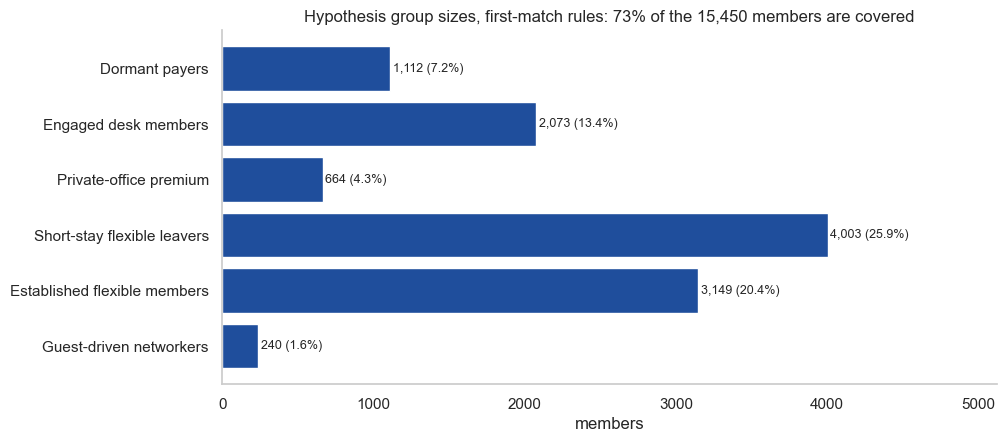

In [174]:
# The group sizes as a chart.
fig, ax = plt.subplots(figsize=(10, 4.6))
group_sizes = hypothesis_profile["members"].drop("Not covered by a rule")
bars = ax.barh(range(len(group_sizes)), group_sizes.values, color=BLUE)
ax.set_yticks(range(len(group_sizes)), [name.split(" ", 1)[1] for name in group_sizes.index])
ax.bar_label(bars, labels=[f"{v:,} ({v / len(analysis_data) * 100:.1f}%)" for v in group_sizes.values], fontsize=9, padding=2)
ax.set(xlabel="members", xlim=(0, group_sizes.max() * 1.28), ylabel="",
       title=f"Hypothesis group sizes, first-match rules: {100 - uncovered_pct:.0f}% of the "
             f"{len(analysis_data):,} members are covered")
ax.invert_yaxis()
ax.grid(False)
sns.despine()
plt.show()

In [175]:
# The expected number of groups, with the rule stated in full.
print("Expected number of groups, the rule stated exactly:")
print("  1. Sort the five plan tiers by median monthly revenue, the value axis a grouping would use.")
print("  2. Two adjacent tiers count as the SAME revenue level when their middle halves overlap.")
print(f"  3. revenue_levels = 1 + the number of adjacent pairs that do not overlap = {revenue_levels}.")
print(f"  4. The working range is revenue_levels - 1 to revenue_levels + 1, that is "
      f"{expected_cluster_min} to {expected_cluster_max} groups.")
print("  5. The lower bound lets two levels merge once behaviour is taken into account; the upper bound lets one")
print(f"     level split on the leading behavioural feature ({top_differentiating[0]}).")

Expected number of groups, the rule stated exactly:
  1. Sort the five plan tiers by median monthly revenue, the value axis a grouping would use.
  2. Two adjacent tiers count as the SAME revenue level when their middle halves overlap.
  3. revenue_levels = 1 + the number of adjacent pairs that do not overlap = 5.
  4. The working range is revenue_levels - 1 to revenue_levels + 1, that is 4 to 6 groups.
  5. The lower bound lets two levels merge once behaviour is taken into account; the upper bound lets one
     level split on the leading behavioural feature (visit_rate).


In [176]:
print(f"So the hypothesis Deliverable 2 should test is {expected_cluster_min} to {expected_cluster_max} groups, "
      f"centred on {revenue_levels}.")
print("Read on these features:", ", ".join(top_differentiating))
print("and separated by membership status, since the active and the ended populations differ inside every tier")
print("(the profile table at the top of this section).")
print("This is a descriptive hypothesis about how many groups the data can support. No grouping model has been run")
print("in this notebook, so no group named here is a model result.")

So the hypothesis Deliverable 2 should test is 4 to 6 groups, centred on 5.
Read on these features: visit_rate, value_per_visit, recency_days
and separated by membership status, since the active and the ended populations differ inside every tier
(the profile table at the top of this section).
This is a descriptive hypothesis about how many groups the data can support. No grouping model has been run
in this notebook, so no group named here is a model result.


So what: the plan tier fixes what a member pays, but usage, recency and allowance use inside the tier say which of
those members will still be there, so the six hypotheses and the working range of groups printed above are what
Deliverable 2 has to test.

# 13. Conclusion
The four questions the brief asks are answered below. Every number in the answers is printed by the cells in this
section or by the section named at the end of each answer.

**1. What do the data show?** The base is a three-year extract of one market, concentrated in the two cheapest plans
and in Portugal. Revenue is a tail: a small number of members hold most of the recorded lifetime value, and the
monthly-revenue levels the plans actually form do not follow the documented ladder, since `full_time` earns less per
month than `dedicated_desk`. Usage separates members better than price does: inside the same plan, the members who
left and the members who stayed differ on attendance, recency and allowance use. (Sections 5, 6, 7, 12.)

**2. What are the data-quality issues, and how do they affect a grouping?** Duplicates, category variants, two date
formats plus an active sentinel, placeholder codes, impossible values, extremes that include a live unit-error
hypothesis, and fields that contradict each other. They reach a grouping in three ways: a member with no value is
placed by the other axes alone, a placeholder read as a real number gives a member a position they never held, and
one heavy tail can dominate every distance. Section 11 ranks these by impact and counts them in members. Nothing is
filled in, trimmed or deleted beyond the exact duplicates. (Sections 3, 4, 10, 11.)

**3. What customer groups do we expect, and on what evidence?** Six named hypotheses whose sizes are counted in
section 12, and a working range of groups derived by the stated rule from the number of separable monthly-revenue
levels. The evidence is behavioural, measured inside each plan tier, so the plan itself is not credited with the
separation. (Sections 8, 9, 12.)

**4. What would we tell the client in plain language?** A few members carry most of the revenue, a large block of
committed members pay for desks they hardly use, and the cheapest plans hold most of the people. A segmentation
should therefore be built on behaviour rather than on the price list, and the first thing to settle with ACDC is
whether the dormant members are genuinely absent or simply not badging. (Sections 5, 7, 12.)

In [177]:
# The headline answers, printed from this run rather than restated from notes.
ltv_final = analysis_data["lifetime_value"]
print(f"members analysed: {len(analysis_data):,} of {len(raw):,} rows in the extract")
print(f"value concentration : the top 1% hold {share_with:.1f}% of recorded lifetime value; "
      f"the {n_suspects} suspect extremes alone hold {share_held_by_suspects:.1f}%")
print(f"median lifetime value {ltv_final.median():,.0f} EUR against a mean of {ltv_final.mean():,.0f}")
print(f"revenue levels      : {revenue_levels} -> expected groups {expected_cluster_min} to {expected_cluster_max}")
print(f"tier order vs money : {'inverted' if inversions else 'agrees'} "
      f"({', '.join(f'{h} below {l}' for l, h in inversions)})")

members analysed: 15,450 of 15,465 rows in the extract
value concentration : the top 1% hold 45.8% of recorded lifetime value; the 17 suspect extremes alone hold 29.5%
median lifetime value 1,668 EUR against a mean of 7,340
revenue levels      : 5 -> expected groups 4 to 6
tier order vs money : inverted (full_time below dedicated_desk)


In [178]:
print(f"lifecycle           : {pct_ended:.1f}% ended over a {window_years:.0f}-year window, "
      f"median tenure at exit {analysis_data.loc[~analysis_data['is_active'], 'tenure_months'].median():.1f} months")
print(f"dormant payers      : {n_dormant:,} members, {dormant_share:.0f}% of the committed actives with a defined ratio, "
      f"{dormant_monthly_revenue:,.0f} EUR a month behind them")
print(f"behavioural leaders : {', '.join(top_differentiating)}")
print(f"groups not covered  : {uncovered_pct:.1f}% of members match none of the six rules")
print(f"flags in the frame  : {len(issue_columns)} issue flags over "
      f"{int(members_with_any_issue.sum()):,} members ({members_with_any_issue.mean():.1%})")

lifecycle           : 74.4% ended over a 3-year window, median tenure at exit 8.2 months
dormant payers      : 1,112 members, 62% of the committed actives with a defined ratio, 327,728 EUR a month behind them
behavioural leaders : visit_rate, value_per_visit, recency_days
groups not covered  : 27.2% of members match none of the six rules
flags in the frame  : 25 issue flags over 3,391 members (21.9%)


In [179]:
# The candidate features for Deliverable 2: what survived both screens, and what did not.
final_features = list(surviving_features)
for _, pair_row in redundancy.iterrows():
    keeper = pair_row["kept"]
    if pair_row["dropped"] != "none" and keeper not in final_features and keeper in screening.index:
        final_features.append(keeper)
excluded_redundant = [f for f in engineered_numeric + ["start_year_cohort", "addon_mix"] if f in dropped_for_redundancy]
excluded_constant = [f for f in screening.index if screening.loc[f, "most_common_value_pct"] >= NEAR_CONSTANT_SHARE]
candidate_features = []
for feature in final_features:
    if feature not in excluded_constant:
        candidate_features.append(feature)
print("features proposed for the grouping work:")
for feature in candidate_features:
    coverage = analysis_data[feature].notna().mean() * 100
    print(f"  {feature:26s} covers {coverage:5.1f}% of members")
thin_candidates = [f for f in candidate_features if screening.loc[f, "coverage_pct"] < 50]
print(f"\n{len(candidate_features)} candidates, of which {len(thin_candidates)} cover under half the base: "
      f"{', '.join(thin_candidates) or 'none'}")
print("Those stay on the list because they carry the value axis, but Deliverable 2 has to decide explicitly whether")
print("to group on them and report the members they cannot place.")
final_features = candidate_features

features proposed for the grouping work:
  tenure_months              covers  99.0% of members
  monthly_revenue            covers  47.8% of members
  visit_rate                 covers  59.8% of members
  value_per_visit            covers  80.9% of members
  utilization_rate           covers  99.9% of members
  renewal_rate               covers  59.7% of members
  recency_days               covers  98.4% of members
  n_addons_used              covers 100.0% of members
  premium_hours_total        covers  91.5% of members
  visit_intensity_vs_plan    covers  99.4% of members
  plan_tier_ordinal          covers  99.3% of members
  start_year_cohort          covers 100.0% of members
  addon_mix                  covers 100.0% of members
  n_colleagues_on_account    covers  99.0% of members
  guest_passes_issued        covers  91.7% of members

15 candidates, of which 1 cover under half the base: monthly_revenue
Those stay on the list because they carry the value axis, but Deliverable 2 has

In [180]:
# What was set aside, and on which grounds.
print(f"set aside as redundant with a stronger column ({len(excluded_redundant)}): {', '.join(excluded_redundant) or 'none'}")
for feature in excluded_redundant:
    pair_row = redundancy.loc[redundancy["dropped"] == feature, ["kept", "spearman"]]
    if not pair_row.empty:
        print(f"    {feature}: kept {pair_row['kept'].iloc[0]} at rho = {pair_row['spearman'].iloc[0]}")
print(f"\nset aside as near-constant ({len(excluded_constant)}): {', '.join(excluded_constant) or 'none'}")
for feature in excluded_constant:
    print(f"    {feature}: {screening.loc[feature, 'most_common_value_pct']:.1f}% of members on one value")

set aside as redundant with a stronger column (2): team_size, guest_pass_rate
    team_size: kept n_colleagues_on_account at rho = 1.0
    guest_pass_rate: kept guest_passes_issued at rho = 0.9976

set aside as near-constant (1): uses_bike_locker
    uses_bike_locker: 99.8% of members on one value


### Open questions for ACDC
Whether the EUR 1M-plus values are a thousand-fold unit error; what feeds `last_badge_swipe`, which decides whether
the dormant group is absence or a reporting gap; why `full_time` is priced below `dedicated_desk`; what the extraction
date and the `1970-01-01` sentinel mean in the source system; and why `plan_days_per_week` carries 0 and 9 at all,
given that both propagate into the entitlement column. Every flag column stays with the rows it marks: a member is
never removed because of a flag, and a feature a flag invalidates is defined only on the unflagged rows.

### Preprocessing Deliverable 2 has to decide on
These are recommendations, not decisions taken here: this notebook applies none of them.

- **Missing values.** Lifetime value, recency and the usage columns carry honest gaps. Options are to leave them
  missing and group on the complete cases, to fill them with a simple value, or to add a missing indicator. The choice
  should be reported, because section 7 showed the gaps fall on the cheap plans and on the ended members, so filling
  them shifts where those members land.
- **Scaling.** The revenue, visit and recency columns are long-tailed and sit on different units, so a distance
  without scaling would be dominated by lifetime value. Options are a rank or log view of the heavy columns, or a
  per-column standardisation. Section 10 deliberately did none of this.
- **Categorical features.** `plan_tier` is ordinal and already has a documented code. Country, industry and gender
  are nominal: they need an encoding before any distance reads them, and the screen in sections 6 and 7 found little
  spread in value or status across their levels, so the recommendation is to use them for describing the groups
  rather than for forming them.
- **Weighting and trimming.** The near-constant columns are already out. Whether to trim the extreme revenue rows is
  a modelling decision that belongs to Deliverable 2, and it should be taken with the section 10 list of extremes in
  front of it and the `flag_ltv_extreme` members reported separately either way.
- **The active and ended populations.** They differ inside every tier, so the recommendation is to group within each
  status, or to carry status as a stated stratifier, rather than pooling them silently.

### Grouping families worth evaluating
Nothing below is fitted here; the point is which families suit this data shape and how explainable each one will be
to ACDC.

- **Centroid methods such as K-means.** Cheap to explain and fast on this size of table, and it suits a set of
  numerical features on one comparable scale. It assumes roughly round, equally sized groups, which the heavy revenue
  tail breaks, so it needs the tails handled first and the number of groups fixed in advance, which is where the
  revenue-level rule gives a starting range.
- **Hierarchical methods such as agglomerative clustering.** They need no group count up front and produce a tree a
  manager can read, which suits the six named hypotheses well: each hypothesis can be looked for in the branches.
  The cost is that the choice of distance and of linkage changes the answer, and both must be stated.
- **Model-based methods such as a Gaussian mixture.** They fit a shape per group and give each member a probability of
  belonging, which is useful when the boundary between two paying behaviours is genuinely gradual. They are the least
  explainable of the three to a non-technical client and the most sensitive to the tails, so they suit a second pass
  after one of the first two has produced a picture.

Given the shape of the data, one numerical value axis plus behaviour rates and a status split, the recommendation is
to try a centroid method and a hierarchical method on the same prepared feature set, compare them against the six
hypotheses, and keep a model-based method in reserve.

### Expected segments and the challenges in finding them
The six hypotheses point at segments along the lines of dormant committed payers, engaged committed members,
private-office premium accounts, short-stay flexible leavers, established flexible members and guest-driven
networkers, plus the uncovered share of the base the rules do not describe. The challenges are the ones the quality
work already named: a grouping will be tempted to rediscover the plan price list because revenue is the widest axis;
the members with a missing value will drift to whichever group is nearest; the zero-inflated usage columns will try to
create a group of non-users out of a service most members never needed; and the extreme rows in section 10 can become
a group of their own. Checking a candidate group against the section 11 register, before naming it, is what separates
a behaviour from a bookkeeping accident.

In [181]:
# What leaves this notebook for Deliverable 2, counted rather than asserted.
populated_flags = []
for column in issue_columns:
    n_flagged = int(analysis_data[column].fillna(False).astype(bool).sum())
    if n_flagged:
        populated_flags.append({"flag": column, "members": n_flagged})
flags_frame = pd.DataFrame(populated_flags).sort_values("members", ascending=False)
print(flags_frame.to_string(index=False))
print(f"\n{len(final_features)} candidate features, {len(flags_frame)} populated flags, "
      f"{len(analysis_data.columns)} columns in the working frame, {len(risks)} registered risks")

                              flag  members
          flag_ltv_zero_as_missing     1742
flag_days_since_last_visit_invalid     1354
              flag_date_format_dmy      637
     flag_n_colleagues_placeholder      565
             flag_recency_negative      240
              flag_swipe_after_end      213
           flag_tenure_nonpositive      152
             flag_end_before_start      152
                  flag_age_invalid      143
            flag_plan_days_invalid       97
           flag_swipe_before_start       94
                 flag_ltv_negative       82
          flag_n_renewals_negative       66
        flag_total_visits_negative       42
        flag_swipe_after_reference       27
                  flag_ltv_extreme       17
  flag_meeting_room_hours_negative       16
       flag_renewals_exceed_tenure       15
   flag_event_space_hours_negative        8
       flag_visits_above_daily_max        8
    flag_visits_exceed_entitlement        8
   flag_no_entitlement_with_visi

### What this notebook does not do
It does not train a grouping model, reduce the dimensions, split the data into a training and a test part, or fit
anything. It does not fill a missing value, trim a tail, or delete a member for being extreme. No column is scaled or
encoded: section 8 says which candidates are numerical, which categorical and which ordinal, and leaves the treatment
to Deliverable 2. The groups in section 12 are rules the analysts wrote and counted, not model assignments, and the
expected group count comes from the stated rule about revenue levels. The notebook is also the record: it reads one
file and writes no output file.

So what: everything a grouping needs is here in printed form, the candidate features and the reasons for rejecting
the rest, and the decisions that remain are listed as recommendations for Deliverable 2 to own.